# Co-fractionation evidence for protein complexes, with CCprofiler

**Question.** For a complex from Complex Portal, does the SEC co-fractionation data support it, where does it peak, and do the intensities follow the expected copy numbers?

**What does what.**

| Step | Tool | Established method |
|---|---|---|
| Peak finding and co-elution scoring of each complex | CCprofiler (R), `findComplexFeatures` | Heusel et al. 2019, Mol Syst Biol |
| False discovery rate | CCprofiler decoy complexes + `calculateQvalue` (uses the `qvalue` package) | target-decoy, Storey q-values |
| Choosing one feature per complex | CCprofiler `getBestFeatures` | |
| Fraction -> mass calibration | CCprofiler `calibrateMW` (linear fit of log mass vs fraction) | |
| Protein mass and tryptic peptides | `pyteomics` (average mass, ExPASy trypsin rule) | |
| Everything else | plain Python / polars, shown table by table | |

Python prepares the inputs and writes them to `ccprofiler_files/`. R reads them, runs CCprofiler and writes its results there. Python reads them back.


## 0. Setup

In [13]:
from pathlib import Path
import re

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from pyteomics import mass, parser
from scipy.stats import spearmanr
from procompa import get_project_root
import matplotlib.cm as cm
import matplotlib.colors as mcolors



PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"
cofrac_data_dir =  data_dir / "cofrac"
portal_dir = data_dir/ "Complex_Portal"
sequence_data_dir = data_dir / 'iPTM_and_pLDDT'


%config InlineBackend.figure_format = "retina"
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
pl.Config.set_tbl_rows(12)
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#888780'


CF_FILES = {'highglu': 'highglu.tsv', 'nacl': 'nacl.tsv', 'ypd': 'ypd.tsv'}
COMPLEX_FILE = 'Saccharomyces_cerevisiae_ComplexTab.tsv'
SEQUENCE_FILE = 'all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv'

WORK_DIR = 'ccprofiler_files'                      # tables exchanged between Python and R
Path(WORK_DIR).mkdir(exist_ok=True)

N_FRACTIONS = 60
Q_CUTOFF = 0.05
N_CORES = 1                                        # CCprofiler cores; raise this only on a compute node

for file_name in [*CF_FILES.values(), COMPLEX_FILE]:
    assert (cofrac_data_dir / file_name).exists(), f'missing input file: {cofrac_data_dir / file_name}'
assert (sequence_data_dir / SEQUENCE_FILE).exists(), f'missing input file: {sequence_data_dir / SEQUENCE_FILE}'


**R and CCprofiler.** The next cell loads the R. The cell after it installs CCprofiler into personal R library (if it isn't already there).
If the installation fails with compiler or `mpfr` errors, : `module load stack/2024-06 gcc/12.2.0 gmp/6.2.1 mpfr/4.2.0 r/4.6.1`, then rerun the cell.

In [3]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [4]:
%%R
user_library <- Sys.getenv('R_LIBS_USER')
dir.create(user_library, recursive = TRUE, showWarnings = FALSE)
.libPaths(c(user_library, .libPaths()))

if (!requireNamespace('CCprofiler', quietly = TRUE)) {
    options(repos = c(CRAN = 'https://cloud.r-project.org'))
    install.packages(c('remotes', 'BiocManager'))
    BiocManager::install('qvalue', update = FALSE, ask = FALSE)
    remotes::install_github('CCprofiler/CCprofiler', upgrade = 'never', build_vignettes = FALSE)
}
suppressPackageStartupMessages({
    library(CCprofiler)
    library(data.table)
})
cat(sprintf('CCprofiler %s, data.table %s, R %s\n', packageVersion('CCprofiler'), packageVersion('data.table'), getRversion()))

CCprofiler 0.99.1, data.table 1.18.4, R 4.6.1


## 1. Elution profiles

One row per protein (group), one column per fraction. Empty cells mean "not detected" and become 0.

In [5]:
FRACTION_COLUMNS = [str(i) for i in range(1, N_FRACTIONS + 1)]

def read_profiles(path):
    wide = (pl.read_csv(path, separator='\t', infer_schema_length=0)        # read as text: some columns are empty
              .with_columns(pl.col(FRACTION_COLUMNS).cast(pl.Float64).fill_null(0)))
    assert wide.columns == ['ID', *FRACTION_COLUMNS], f'{path}: expected ID + fractions 1..{N_FRACTIONS}'
    assert wide['ID'].is_unique().all(), f'{path}: duplicated IDs'
    return wide

profiles_wide = {condition: read_profiles(cofrac_data_dir / file_name) for condition, file_name in CF_FILES.items()}
profiles_wide['highglu'].head()

ID,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""P0C5R9""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22097.844,16380.963,29986.148,31155.9,19424.547,14636.092,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P03875""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35184.9,95155.46,228527.22,663732.06,568166.56,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P00410""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,4778.473,34428.086,22215.281,42210.91,46920.9,32430.82,30135.215,35351.61,11644.201,8468.228,9983.028,7965.838,6973.484,12418.893,7540.567,7035.867,5221.679,5473.873,4831.0146,3174.3264,4629.427,4496.3345,2917.5918,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P39714""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2727.935,5756.823,11278.288,26878.35,52431.52,64903.684,227087.16,385942.84,710290.56,468790.16,364865.8,202893.75,127663.37,102478.484,80755.836,85972.14,72677.37
"""P39726""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3981.1946,14156.326,9510.102,18156.055,38399.387,32859.535,79139.94,195643.97,500502.88,715126.1,508061.0,262811.22,127700.77,74796.14,43423.805


**Protein groups.** A few rows are groups of near-identical paralogues (`[A;B]`). CCprofiler needs one trace per protein, splitting a group would give two proteins the same trace (perfect, artificial co-elution). These rows are therefore left out, but listed.

In [6]:
protein_groups = pl.concat([wide.filter(pl.col('ID').str.contains(';')).select(pl.lit(condition).alias('condition'), 'ID')
                            for condition, wide in profiles_wide.items()])
profiles_wide = {condition: wide.filter(~pl.col('ID').str.contains(';')) for condition, wide in profiles_wide.items()}
protein_groups.group_by('ID').agg(pl.col('condition')).sort('ID')

ID,condition
str,list[str]
"""[P02407;P14127]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P04911;P04912]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P07280;P07281]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0T4;Q3E792]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0W1;Q3E7Y3]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0W9;Q3E757]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0X0;Q3E7X9]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C2J4;Q12392]""","[""highglu"", ""nacl""]"
"""[P0CX14;P53819]""","[""highglu"", ""nacl""]"


In [7]:
detection_summary = pl.DataFrame([
    dict(condition=condition, proteins=wide.height,
         fractions_without_any_signal=int((wide.select(FRACTION_COLUMNS).sum().to_numpy() == 0).sum()),
         median_fractions_detected_per_protein=float(np.median((wide.select(FRACTION_COLUMNS).to_numpy() > 0).sum(axis=1))))
    for condition, wide in profiles_wide.items()])
detection_summary

condition,proteins,fractions_without_any_signal,median_fractions_detected_per_protein
str,i64,i64,f64
"""highglu""",3569,0,21.0
"""nacl""",3618,0,21.0
"""ypd""",2167,6,16.0


**CCprofiler input format.** CCprofiler reads a long table (`protein_id`, `filename`, `intensity`) plus a table that maps each file name to its fraction number. The fraction names are invented here (`fraction_01` ...); only the mapping matters. Zeros are kept so that every fraction exists even if it has no signal.

In [8]:
fraction_annotation = pl.DataFrame({'filename': [f'fraction_{i:02d}' for i in range(1, N_FRACTIONS + 1)],
                                    'fraction_number': list(range(1, N_FRACTIONS + 1))})

def to_long(wide):
    return (wide.rename({'ID': 'protein_id'})
                .unpivot(index='protein_id', variable_name='fraction_number', value_name='intensity')
                .with_columns(pl.col('fraction_number').cast(pl.Int64))
                .join(fraction_annotation, on='fraction_number')
                .select('protein_id', 'filename', 'intensity')
                .sort('protein_id', 'filename'))

profiles_long = {condition: to_long(wide) for condition, wide in profiles_wide.items()}
for condition, long_table in profiles_long.items():
    assert long_table.height == profiles_wide[condition].height * N_FRACTIONS
profiles_long['highglu'].head(10)

protein_id,filename,intensity
str,str,f64
"""D6VTK4""","""fraction_01""",0.0
"""D6VTK4""","""fraction_02""",0.0
"""D6VTK4""","""fraction_03""",0.0
"""D6VTK4""","""fraction_04""",0.0
"""D6VTK4""","""fraction_05""",0.0
"""D6VTK4""","""fraction_06""",0.0
"""D6VTK4""","""fraction_07""",0.0
"""D6VTK4""","""fraction_08""",2936.6624
"""D6VTK4""","""fraction_09""",26952.701


## 2. Complexes from Complex Portal

Parsed from the *Expanded participant list* (falling back to *Identifiers*).
* Complexes with a paralogue set `[P1,P2]` are dropped, because it is unclear which paralogue is in the complex.
* Non-protein participants (RNA, ligands) are ignored and flagged; masses of such complexes are lower bounds.
* Copy number 0 means "unknown". Those complexes are still searched by CCprofiler, but they are left out of anything that needs a mass or a stoichiometry.

In [9]:
PARTICIPANT = re.compile(r'(\[[^\]]+\]|[^|()]+)\((\d+)\)')
UNIPROT = re.compile(r'^[OPQ][0-9][A-Z0-9]{3}[0-9]|^[A-NR-Z][0-9]')

portal = pl.read_csv(portal_dir / COMPLEX_FILE, separator='\t', quote_char=None, infer_schema_length=0)

member_rows, complex_rows = [], []
for complex_id, complex_name, identifiers, expanded in portal.select(
        '#Complex ac', 'Recommended name', 'Identifiers (and stoichiometry) of molecules in complex',
        'Expanded participant list').iter_rows():
    identifiers, expanded = identifiers or '', expanded or '-'
    participants = PARTICIPANT.findall(expanded if expanded != '-' else identifiers)
    proteins = {acc.split('-')[0]: int(copies) for acc, copies in participants if UNIPROT.match(acc)}
    has_paralogue_set = '[' in identifiers or '[' in expanded
    complex_rows.append(dict(complex_id=complex_id, complex_name=complex_name, n_proteins=len(proteins),
                             has_paralogue_set=has_paralogue_set, has_non_protein=len(proteins) < len(participants),
                             copies_known=bool(proteins) and all(c > 0 for c in proteins.values())))
    if not has_paralogue_set:
        member_rows += [dict(complex_id=complex_id, complex_name=complex_name, protein_id=acc, copies=copies)
                        for acc, copies in proteins.items()]

complex_overview = pl.DataFrame(complex_rows)
complex_members = (pl.DataFrame(member_rows)
                     .join(complex_overview.select('complex_id', 'n_proteins', 'has_non_protein', 'copies_known'), on='complex_id')
                     .filter(pl.col('n_proteins') >= 2))
complex_overview.select(
    complexes=pl.len(), with_paralogue_set=pl.col('has_paralogue_set').sum(),
    usable=(~pl.col('has_paralogue_set') & (pl.col('n_proteins') >= 2)).sum(),
    usable_with_known_copies=(~pl.col('has_paralogue_set') & (pl.col('n_proteins') >= 2) & pl.col('copies_known')).sum())

complexes,with_paralogue_set,usable,usable_with_known_copies
u32,u32,u32,u32
634,2,614,283


In [10]:
complex_members.head()

complex_id,complex_name,protein_id,copies,n_proteins,has_non_protein,copies_known
str,str,str,i64,i64,bool,bool
"""CPX-15""","""CST complex""","""P32797""",0,3,false,false
"""CPX-15""","""CST complex""","""P38960""",0,3,false,false
"""CPX-15""","""CST complex""","""Q07921""",0,3,false,false
"""CPX-21""","""Replication protein A complex""","""P22336""",1,3,false,true
"""CPX-21""","""Replication protein A complex""","""P26754""",1,3,false,true


**Calibration anchors** (the CF-MS expert's obligate complexes, mapped to yeast). The multi-protein anchors are added to the CCprofiler search as extra hypotheses (`ANCHOR_...`), so their peaks come from the same method and the same FDR. Single-protein anchors cannot be searched by a complex method; their peak is simply the fraction with the highest intensity (section 5).

PCNA (Pol30) is left out: it appears as trimer and monomer, and "highest intensity" cannot tell which state a peak is.

In [14]:
def same_copies(accessions, copies):
    return dict.fromkeys(accessions, copies)

SINGLE_PROTEIN_ANCHORS = {               # name: (UniProt accession, copies)
    'Sod1 dimer': ('P00445', 2),
    'Tpi1 dimer': ('P00942', 2),
    'Eno1 dimer': ('P00924', 2),         # Eno1 / Eno2 are ~95% identical; both are used
    'Eno2 dimer': ('P00925', 2),
    'Tdh3 tetramer': ('P00359', 4),      # Tdh1 / Tdh2 / Tdh3 are paralogues; only Tdh3 is used
    'Gln1 decamer': ('P32288', 10),
}
COMPLEX_ANCHORS = {                      # name: {UniProt accession: copies}
    'Prefoldin': same_copies(['P40005', 'P46988', 'P48363', 'P52553', 'P53900', 'Q04493'], 1),
    'Arp2/3': same_copies(['P32381', 'P33204', 'P38328', 'P40518', 'P47117', 'P53731', 'Q05933'], 1),
    'COPI coatomer': same_copies(['P32074', 'P40509', 'P41810', 'P41811', 'P43621', 'P53600', 'P53622'], 1),
    'MCM2-7': same_copies(['P24279', 'P29469', 'P29496', 'P30665', 'P38132', 'P53091'], 1),
    '20S proteasome': same_copies(['P22141', 'P30656', 'P38624', 'P30657', 'P40302', 'P40303', 'P23724',
                                   'P23639', 'P23638', 'P21242', 'P25043', 'P32379', 'P25451', 'P21243'], 2),
    'CCT / TRiC': same_copies(['P12612', 'P39076', 'P39077', 'P39078', 'P39079', 'P40413', 'P42943', 'P47079'], 2),
}
anchor_members = pl.DataFrame([dict(complex_id='ANCHOR_' + re.sub(r'\W+', '_', name), complex_name=name,
                                    protein_id=acc, copies=copies)
                               for name, subunits in COMPLEX_ANCHORS.items() for acc, copies in subunits.items()])
anchor_members.group_by('complex_id', 'complex_name').agg(n_proteins=pl.len(), copies=pl.col('copies').first()).sort('complex_id')

complex_id,complex_name,n_proteins,copies
str,str,u32,i64
"""ANCHOR_20S_proteasome""","""20S proteasome""",14,2
"""ANCHOR_Arp2_3""","""Arp2/3""",7,1
"""ANCHOR_CCT_TRiC""","""CCT / TRiC""",8,2
"""ANCHOR_COPI_coatomer""","""COPI coatomer""",7,1
"""ANCHOR_MCM2_7""","""MCM2-7""",6,1
"""ANCHOR_Prefoldin""","""Prefoldin""",6,1


In [15]:
complex_hypotheses = pl.concat([complex_members.select('complex_id', 'complex_name', 'protein_id'),
                                anchor_members.select('complex_id', 'complex_name', 'protein_id')])
assert not complex_hypotheses.is_duplicated().any()
assert not complex_hypotheses['complex_id'].str.contains('DECOY').any(), 'CCprofiler marks decoys by "DECOY" in the id'
print(complex_hypotheses['complex_id'].n_unique(), 'complex hypotheses,', complex_hypotheses['protein_id'].n_unique(), 'distinct proteins')
complex_hypotheses.head()

620 complex hypotheses, 1839 distinct proteins


complex_id,complex_name,protein_id
str,str,str
"""CPX-15""","""CST complex""","""P32797"""
"""CPX-15""","""CST complex""","""P38960"""
"""CPX-15""","""CST complex""","""Q07921"""
"""CPX-21""","""Replication protein A complex""","""P22336"""
"""CPX-21""","""Replication protein A complex""","""P26754"""


## 3. Protein masses and tryptic peptides (pyteomics)

* Mass: average mass of the sequence (`pyteomics.mass.calculate_mass(..., average=True)`, includes water).
* Tryptic peptides: distinct peptides of 6-30 residues from an in-silico digest with the ExPASy trypsin rule, no missed cleavages. Used like iBAQ to normalise intensities in section 6.
* Three proteins have no 6-30 aa tryptic peptide (Rpl41a, Atp8, Ost4). They are kept everywhere, but their per-peptide intensity is left empty, so they drop out of the per-peptide comparison only.

In [16]:
VALID_RESIDUES = set('ACDEFGHIKLMNPQRSTVWY') | {'U'}

sequences = (pl.read_csv(sequence_data_dir / SEQUENCE_FILE)
               .select('uniprot_id', 'sequence')
               .drop_nulls('sequence')
               .with_columns(pl.col('sequence').str.replace_all('*', '', literal=True).str.strip_chars()))
print(f'{sequences.height} rows, {sequences["uniprot_id"].n_unique()} accessions; '
      f'{sequences.filter(pl.col("uniprot_id").is_duplicated())["uniprot_id"].n_unique()} accessions appear more than once (first kept)')
sequences = sequences.unique('uniprot_id', keep='first', maintain_order=True)
unexpected = {aa for seq in sequences['sequence'] for aa in seq} - VALID_RESIDUES
assert not unexpected, f'unexpected residue letters: {unexpected}'

def n_tryptic_peptides(sequence):
    return len(parser.cleave(sequence, parser.expasy_rules['trypsin'], min_length=6, max_length=30))

protein_info = sequences.select(
    protein_id=pl.col('uniprot_id'),
    mass_kda=pl.col('sequence').map_elements(lambda s: mass.calculate_mass(sequence=s, average=True) / 1000, return_dtype=pl.Float64),
    n_tryptic_peptides=pl.col('sequence').map_elements(n_tryptic_peptides, return_dtype=pl.Int64))
proteins_without_peptides = (protein_info.filter(pl.col('n_tryptic_peptides') == 0)
                               .join(sequences.select(protein_id='uniprot_id', sequence='sequence'), on='protein_id')
                               .with_columns(length=pl.col('sequence').str.len_chars()))
proteins_without_peptides

2954 rows, 2954 accessions; 0 accessions appear more than once (first kept)


protein_id,mass_kda,n_tryptic_peptides,sequence,length
str,f64,i64,str,u32
"""P0CX86""",3.337115,0,"""MRAKWRKKRTRRLKRKRRKVRARSK""",25
"""P00856""",5.822201,0,"""MPQLVPFYFMNQLTYGFLLMITLLILFSQF…",48
"""Q99380""",3.984685,0,"""MISDEQLNSLAITFGIVMMTLIVIYHAVDS…",36


In [17]:
print(f'{proteins_without_peptides.height} proteins without a 6-30 aa tryptic peptide; their per-peptide intensity stays empty')
protein_info = protein_info.with_columns(
    n_tryptic_peptides=pl.when(pl.col('n_tryptic_peptides') > 0).then(pl.col('n_tryptic_peptides'))) 

3 proteins without a 6-30 aa tryptic peptide; their per-peptide intensity stays empty


## 4. CCprofiler

### 4a. Write the inputs

In [18]:
fraction_annotation.write_csv(f'{WORK_DIR}/fraction_annotation.tsv', separator='\t')
complex_hypotheses.write_csv(f'{WORK_DIR}/complex_hypotheses.tsv', separator='\t')
for condition, long_table in profiles_long.items():
    long_table.write_csv(f'{WORK_DIR}/profiles_long_{condition}.tsv', separator='\t')
CONDITIONS = list(CF_FILES)
sorted(p.name for p in Path(WORK_DIR).iterdir())

['calibration_anchors.tsv',
 'calibration_curves.tsv',
 'complex_features_best_highglu.tsv',
 'complex_features_best_nacl.tsv',
 'complex_features_best_ypd.tsv',
 'complex_features_highglu.tsv',
 'complex_features_nacl.tsv',
 'complex_features_q_highglu.tsv',
 'complex_features_q_nacl.tsv',
 'complex_features_q_ypd.tsv',
 'complex_features_scored_highglu.tsv',
 'complex_features_scored_nacl.tsv',
 'complex_features_scored_ypd.tsv',
 'complex_features_ypd.tsv',
 'complex_hypotheses.tsv',
 'complex_hypotheses_with_decoys.tsv',
 'complexes_before_ribosome_wide.csv',
 'fraction_annotation.tsv',
 'profiles_long_highglu.tsv',
 'profiles_long_nacl.tsv',
 'profiles_long_ypd.tsv',
 'uniprot_go_cellular_component.tsv']

### 4b. Decoy complexes
CCprofiler builds a protein network from all target complexes (every pair of proteins in a complex is an edge) and draws decoy complexes of the same sizes from proteins that are at least `min_distance = 2` steps apart, i.e. never in a known complex together. One decoy per target. The same decoys are used for all three conditions.

The network distances are computed with `igraph` directly instead of CCprofiler's `calculatePathlength`. That function ends with `melt(matrix)`, which current `data.table` versions no longer accept (they used to forward it to the retired `reshape2`). The three lines below do the same thing: all-pairs shortest path lengths in the format `x`, `y`, `dist` that `generateComplexDecoys` expects.

In [19]:
%%R -i WORK_DIR
target_hypotheses <- fread(file.path(WORK_DIR, 'complex_hypotheses.tsv'))
binary_network <- generateBinaryNetwork(copy(target_hypotheses))

protein_graph <- igraph::graph_from_data_frame(binary_network, directed = FALSE)
path_lengths <- as.data.table(as.table(igraph::distances(protein_graph)))
setnames(path_lengths, c('x', 'y', 'dist'))

progress_bar_text <- capture.output(
    hypotheses_with_decoys <- generateComplexDecoys(target_hypotheses = target_hypotheses,
                                                    dist_info = path_lengths,
                                                    min_distance = 2,
                                                    append = TRUE))
fwrite(hypotheses_with_decoys, file.path(WORK_DIR, 'complex_hypotheses_with_decoys.tsv'), sep = '\t')
cat(sprintf('%d proteins in the network, %d pairs at distance 1; %d targets -> %d targets + decoys\n',
            igraph::vcount(protein_graph), nrow(path_lengths[dist == 1]) / 2,
            uniqueN(target_hypotheses$complex_id), uniqueN(hypotheses_with_decoys$complex_id)))

1839 proteins in the network, 9797 pairs at distance 1; 620 targets -> 1240 targets + decoys


In [20]:
hypotheses_with_decoys = pl.read_csv(f'{WORK_DIR}/complex_hypotheses_with_decoys.tsv', separator='\t')
hypothesis_sizes = (hypotheses_with_decoys
                      .with_columns(kind=pl.when(pl.col('complex_id').str.starts_with('DECOY')).then(pl.lit('decoy')).otherwise(pl.lit('target')))
                      .group_by('kind', 'complex_id').len()
                      .group_by('kind').agg(hypotheses=pl.len(), median_size=pl.col('len').median(), max_size=pl.col('len').max()))
hypothesis_sizes

kind,hypotheses,median_size,max_size
str,u32,f64,u32
"""decoy""",620,3.0,47
"""target""",620,3.0,47


### 4c. Complex feature finding
For every hypothesis (target or decoy), CCprofiler
1. replaces zeros by small random noise (below the 5% intensity quantile) so correlations can be computed,
2. slides a window of `window_size` fractions along the profiles and keeps the subunits whose profiles correlate above `corr_cutoff` inside the window,
3. smooths (Savitzky-Golay, `smoothing_length`) and picks peaks in the combined trace of those subunits, giving apex and left/right boundaries,
4. merges features whose apexes are closer than `rt_height` fractions.

One hypothesis can give several features (e.g. a subcomplex and the full complex at different positions).
The parameters below are CCprofiler's defaults. This step takes a few minutes per condition. CCprofiler's progress bar and its message *"Subsetting returns empty traces object"* (printed for every hypothesis with no detected protein) are suppressed.

In [17]:

'''
takes 17 min to run 
%%R -i WORK_DIR,N_CORES
fraction_annotation <- fread(file.path(WORK_DIR, 'fraction_annotation.tsv'))
for (condition in c('highglu', 'nacl', 'ypd')) {
    long_table <- fread(file.path(WORK_DIR, paste0('profiles_long_', condition, '.tsv')))
    protein_traces <- importPCPdata(input_data = long_table, fraction_annotation = copy(fraction_annotation))
    progress_bar_text <- capture.output(suppressMessages(
        complex_features <- findComplexFeatures(traces = protein_traces,
                                                complex_hypothesis = hypotheses_with_decoys,
                                                corr_cutoff = 0.95,  # all these parameters are ccprofilers default
                                                window_size = 15,
                                                smoothing_length = 11,
                                                rt_height = 5,
                                                parallelized = N_CORES > 1,
                                                n_cores = N_CORES)))
    fwrite(complex_features, file.path(WORK_DIR, paste0('complex_features_', condition, '.tsv')), sep = '\t')
    cat(sprintf('%-8s %d proteins, %d features from %d hypotheses (%d of them decoys)\n', condition,
                nrow(protein_traces$traces), nrow(complex_features), uniqueN(complex_features$complex_id),
                uniqueN(complex_features[grepl('DECOY', complex_id)]$complex_id)))
}
'''

"\ntakes 17 min to run \n%%R -i WORK_DIR,N_CORES\nfraction_annotation <- fread(file.path(WORK_DIR, 'fraction_annotation.tsv'))\nfor (condition in c('highglu', 'nacl', 'ypd')) {\n    long_table <- fread(file.path(WORK_DIR, paste0('profiles_long_', condition, '.tsv')))\n    protein_traces <- importPCPdata(input_data = long_table, fraction_annotation = copy(fraction_annotation))\n    progress_bar_text <- capture.output(suppressMessages(\n        complex_features <- findComplexFeatures(traces = protein_traces,\n                                                complex_hypothesis = hypotheses_with_decoys,\n                                                corr_cutoff = 0.95,  # all these parameters are ccprofilers default\n                                                window_size = 15,\n                                                smoothing_length = 11,\n                                                rt_height = 5,\n                                                parallelized = N_CORES > 

In [21]:
raw_features = pl.read_csv(f'{WORK_DIR}/complex_features_highglu.tsv', separator='\t')
print(raw_features.columns)
raw_features.select('complex_id', 'complex_name', 'n_subunits_annotated', 'n_subunits_with_signal', 'n_subunits_detected',
                    'subunits_detected', 'left_pp', 'apex', 'right_pp', 'peak_corr', 'area').head(8)

['complex_id', 'complex_name', 'subunits_annotated', 'n_subunits_annotated', 'subunits_with_signal', 'n_subunits_with_signal', 'subunits_detected', 'n_subunits_detected', 'completeness', 'left_sw', 'right_sw', 'sw_score', 'left_pp', 'right_pp', 'apex', 'area', 'peak_corr', 'total_intensity', 'intensity_ratio', 'stoichiometry_estimated']


complex_id,complex_name,n_subunits_annotated,n_subunits_with_signal,n_subunits_detected,subunits_detected,left_pp,apex,right_pp,peak_corr,area
str,str,i64,i64,i64,str,i64,i64,i64,f64,f64
"""CPX-21""","""Replication protein A complex""",3,3,3,"""P22336;P26754;P26755""",38,46,52,0.621081,2.6433e6
"""CPX-21""","""Replication protein A complex""",3,3,3,"""P22336;P26754;P26755""",6,13,20,0.979177,1.1108e6
"""CPX-23""","""U1 small nuclear ribonucleopro…",17,16,13,"""P32605;P33203;P39682;P40204;P4…",10,15,20,0.840137,1.2566e6
"""CPX-23""","""U1 small nuclear ribonucleopro…",17,16,5,"""P40018;P54999;Q00916;Q02260;Q0…",1,5,8,0.092638,23178.0
"""CPX-24""","""U6 small nuclear ribonucleopro…",8,8,6,"""P38203;P40070;P47093;P49960;P5…",38,44,51,0.848356,758576.5033
"""CPX-24""","""U6 small nuclear ribonucleopro…",8,8,5,"""P38203;P40070;P40089;P53905;Q0…",10,18,26,0.906081,973126.6629
"""CPX-24""","""U6 small nuclear ribonucleopro…",8,8,2,"""P40089;P53905""",50,57,60,0.96037,505884.6997
"""CPX-25""","""U4/U6.U5 tri-small nuclear rib…",29,27,23,"""P19735;P20053;P32639;P33334;P3…",9,15,20,0.731374,4.6823e6


### 4d. Scoring and q-values
* `calculateCoelutionScore`: combines the within-peak correlation (`peak_corr`) with how many of the annotated subunits co-elute. It is the probability-based score from the CCprofiler paper: seeing many of a complex's subunits correlate is less likely by chance than seeing few.
* `calculateQvalue`: p-value of each target feature = share of decoy features scoring at least as high; q-values from the `qvalue` package. Returns targets only.
* `getBestFeatures`: of the features with q <= cutoff, one per complex (most co-eluting subunits, then highest `peak_corr`, then largest area).

In [22]:
%%R -i WORK_DIR,Q_CUTOFF
for (condition in c('highglu', 'nacl', 'ypd')) {
    complex_features <- fread(file.path(WORK_DIR, paste0('complex_features_', condition, '.tsv')))
    scored_features <- calculateCoelutionScore(complex_features)
    fwrite(scored_features, file.path(WORK_DIR, paste0('complex_features_scored_', condition, '.tsv')), sep = '\t')
    target_features_q <- calculateQvalue(scored_features, plot = FALSE)
    stopifnot(is.data.table(target_features_q))          # calculateQvalue returns the string "NA" if it cannot fit
    fwrite(target_features_q, file.path(WORK_DIR, paste0('complex_features_q_', condition, '.tsv')), sep = '\t')
    best_features <- getBestFeatures(subset(target_features_q, qvalue <= Q_CUTOFF))
    fwrite(best_features, file.path(WORK_DIR, paste0('complex_features_best_', condition, '.tsv')), sep = '\t')
    cat(sprintf('%-8s %d target features, %d with q <= %.2f, from %d complexes\n', condition, nrow(target_features_q),
                nrow(subset(target_features_q, qvalue <= Q_CUTOFF)), Q_CUTOFF, nrow(best_features)))
}

highglu  603 target features, 251 with q <= 0.05, from 228 complexes
nacl     603 target features, 328 with q <= 0.05, from 273 complexes
ypd      349 target features, 181 with q <= 0.05, from 146 complexes


**Targets against decoys.** If the data contain real complexes, targets should have more high scores than decoys.

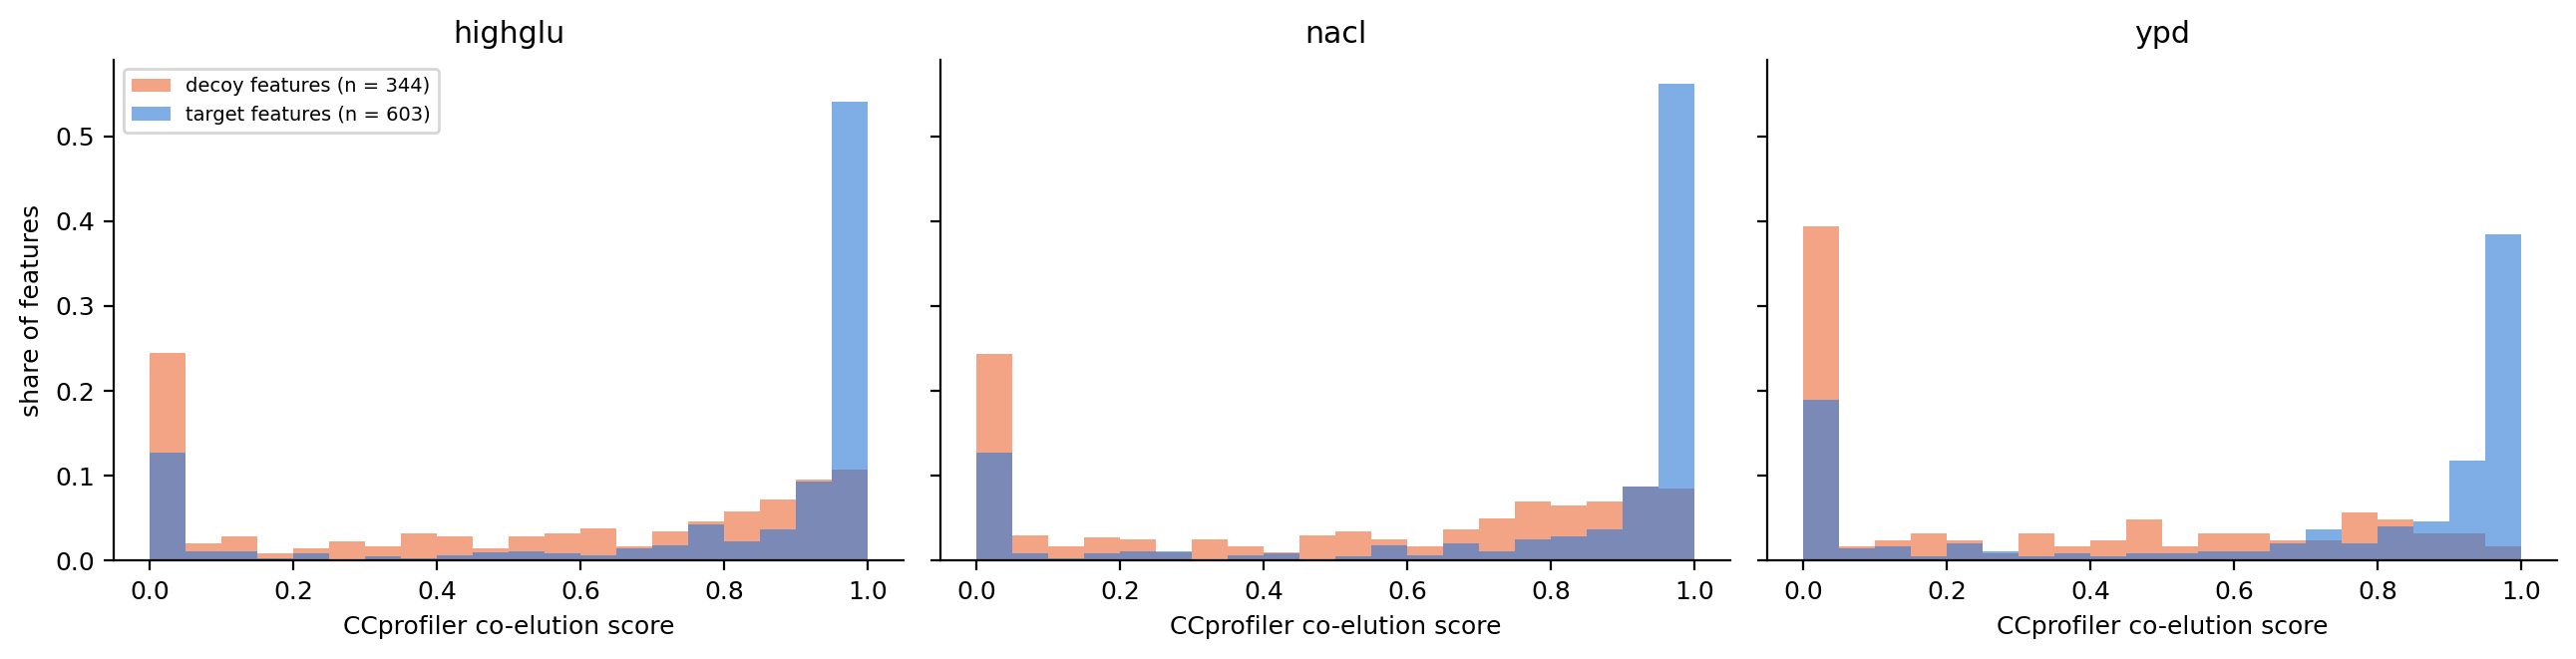

In [23]:
scored_features = {condition: pl.read_csv(f'{WORK_DIR}/complex_features_scored_{condition}.tsv', separator='\t')
                                .with_columns(is_decoy=pl.col('complex_id').str.starts_with('DECOY'))
                   for condition in CONDITIONS}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, (condition, table) in zip(axes, scored_features.items()):
    for is_decoy, colour, label in [(True, ORANGE, 'decoy'), (False, BLUE, 'target')]:
        scores = table.filter(pl.col('is_decoy') == is_decoy)['coelution_score'].to_numpy()
        ax.hist(scores, bins, weights=np.full(len(scores), 1 / len(scores)), color=colour, alpha=0.6, label=f'{label} features (n = {len(scores)})')
    ax.set(title=condition, xlabel='CCprofiler co-elution score')
axes[0].set_ylabel('share of features'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [24]:
best_features = pl.concat([pl.read_csv(f'{WORK_DIR}/complex_features_best_{condition}.tsv', separator='\t')
                             .select(pl.lit(condition).alias('condition'), 'complex_id', 'complex_name', 'n_subunits_annotated',
                                     'n_subunits_detected', 'subunits_detected', 'left_pp', 'apex', 'right_pp',
                                     'peak_corr', 'coelution_score', 'qvalue')
                           for condition in CONDITIONS])
best_features.group_by('condition').agg(
    complexes_with_q_below_cutoff=pl.len(),
    of_which_anchors=pl.col('complex_id').str.starts_with('ANCHOR').sum()).sort('condition')

condition,complexes_with_q_below_cutoff,of_which_anchors
str,u32,u32
"""highglu""",228,6
"""nacl""",273,6
"""ypd""",146,4


In [22]:
# best_features.sort('condition', 'apex').head()

## 5. Where do complexes peak, and does position follow mass?

Expected mass = sum over the subunits **in the CCprofiler feature** of copies x protein mass. Only Complex Portal complexes with known copy numbers and known masses for those subunits.

In [25]:
feature_subunits = (best_features
                      .filter(~pl.col('complex_id').str.starts_with('ANCHOR'))
                      .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
                      .explode('protein_id')
                      .join(complex_members.select('complex_id', 'protein_id', 'copies', 'copies_known', 'has_non_protein'),
                            on=['complex_id', 'protein_id'], how='left')
                      .join(protein_info, on='protein_id', how='left'))
assert feature_subunits['copies'].null_count() == 0, 'a detected subunit is not a member of its complex'
feature_subunits.select('condition', 'complex_id', 'complex_name', 'protein_id', 'copies', 'copies_known', 'mass_kda', 'apex').head()

condition,complex_id,complex_name,protein_id,copies,copies_known,mass_kda,apex
str,str,str,str,i64,bool,f64,i64
"""highglu""","""CPX-1021""","""DNF1-LEM3 P4-ATPase complex""","""P32660""",0,false,177.796331,12
"""highglu""","""CPX-1021""","""DNF1-LEM3 P4-ATPase complex""","""P42838""",0,false,47.437099,12
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""",1,true,37.12171,15
"""highglu""","""CPX-1039""","""COMPASS complex""","""P38123""",1,true,34.753404,15
"""highglu""","""CPX-1039""","""COMPASS complex""","""P39706""",1,true,48.654312,15


In [26]:
complex_masses = (feature_subunits
                    .group_by('condition', 'complex_id', 'complex_name', 'apex', 'n_subunits_detected', 'n_subunits_annotated', 'has_non_protein')
                    .agg(copies_known=pl.col('copies_known').all(),
                         all_masses_known=pl.col('mass_kda').is_not_null().all(),
                         mass_detected_subunits_kda=(pl.col('copies') * pl.col('mass_kda')).sum()))
print(complex_masses.group_by('copies_known', 'all_masses_known').len())
complex_masses = complex_masses.filter('copies_known', 'all_masses_known').drop('copies_known', 'all_masses_known')
complex_masses.sort('condition', 'apex').head()

shape: (3, 3)
┌──────────────┬──────────────────┬─────┐
│ copies_known ┆ all_masses_known ┆ len │
│ ---          ┆ ---              ┆ --- │
│ bool         ┆ bool             ┆ u32 │
╞══════════════╪══════════════════╪═════╡
│ false        ┆ true             ┆ 286 │
│ true         ┆ false            ┆ 4   │
│ true         ┆ true             ┆ 341 │
└──────────────┴──────────────────┴─────┘


condition,complex_id,complex_name,apex,n_subunits_detected,n_subunits_annotated,has_non_protein,mass_detected_subunits_kda
str,str,str,i64,i64,i64,bool,f64
"""highglu""","""CPX-1732""","""Ku70:Ku80 complex""",11,2,2,false,141.88706
"""highglu""","""CPX-5322""","""Endosomal SNARE complex TLG2-V…",12,4,4,false,109.560554
"""highglu""","""CPX-5424""","""Endosomal SNARE complex PEP12-…",12,4,4,false,99.923326
"""highglu""","""CPX-3056""","""SEC62-SEC63 complex""",12,4,4,false,152.527603
"""highglu""","""CPX-565""","""Mitochondrial respiratory chai…",12,4,4,false,142.775819


In [27]:
CYTOSOLIC_RIBOSOME = {'CPX-1599': '40S', 'CPX-1601': '60S'}
UNIPROT_ANYWHERE = re.compile(r'[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9][A-Z][A-Z0-9]{2}[0-9]')

ribosome_accessions = {}
for complex_id, identifiers, expanded in (portal.filter(pl.col('#Complex ac').is_in(list(CYTOSOLIC_RIBOSOME)))
        .select('#Complex ac', 'Identifiers (and stoichiometry) of molecules in complex', 'Expanded participant list').iter_rows()):
    participant_text = expanded if expanded and expanded != '-' else identifiers
    ribosome_accessions[CYTOSOLIC_RIBOSOME[complex_id]] = set(UNIPROT_ANYWHERE.findall(participant_text))

ribosome_marker_rows = []
for condition, wide in profiles_wide.items():
    for subunit, accessions in ribosome_accessions.items():
        measured = wide.filter(pl.col('ID').is_in(list(accessions)))
        profiles = measured.select(FRACTION_COLUMNS).to_numpy()
        median_profile = np.median(profiles / profiles.max(axis=1, keepdims=True), axis=0)
        ribosome_marker_rows.append(dict(condition=condition, subunit=subunit, proteins_in_complex_portal=len(accessions),
                                         proteins_measured=measured.height, apex_of_median_profile=int(np.argmax(median_profile)) + 1))
ribosome_markers = pl.DataFrame(ribosome_marker_rows)
ribosome_markers

condition,subunit,proteins_in_complex_portal,proteins_measured,apex_of_median_profile
str,str,i64,i64,i64
"""highglu""","""40S""",55,30,15
"""highglu""","""60S""",76,50,15
"""nacl""","""40S""",55,30,16
"""nacl""","""60S""",76,51,16
"""ypd""","""40S""",55,29,19
"""ypd""","""60S""",76,45,19


excluded from the plot: {'CPX-3207': 'Mitochondrial pyruvate dehydrogenase complex', 'CPX-1162': 'Fatty-acyl-CoA synthase'}
shape: (60, 3)
┌───────────┬────────────┬─────────────────────────────────────────────────────────────────────────┐
│ category  ┆ complex_id ┆ complex_name                                                            │
│ ---       ┆ ---        ┆ ---                                                                     │
│ str       ┆ str        ┆ str                                                                     │
╞═══════════╪════════════╪═════════════════════════════════════════════════════════════════════════╡
│ chromatin ┆ CPX-1039   ┆ COMPASS complex                                                         │
│ chromatin ┆ CPX-422    ┆ DNA replication factor C complex, ELG1 variant                          │
│ chromatin ┆ CPX-3215   ┆ FACT complex                                                            │
│ chromatin ┆ CPX-1884   ┆ HDA1 histone deacetylase c

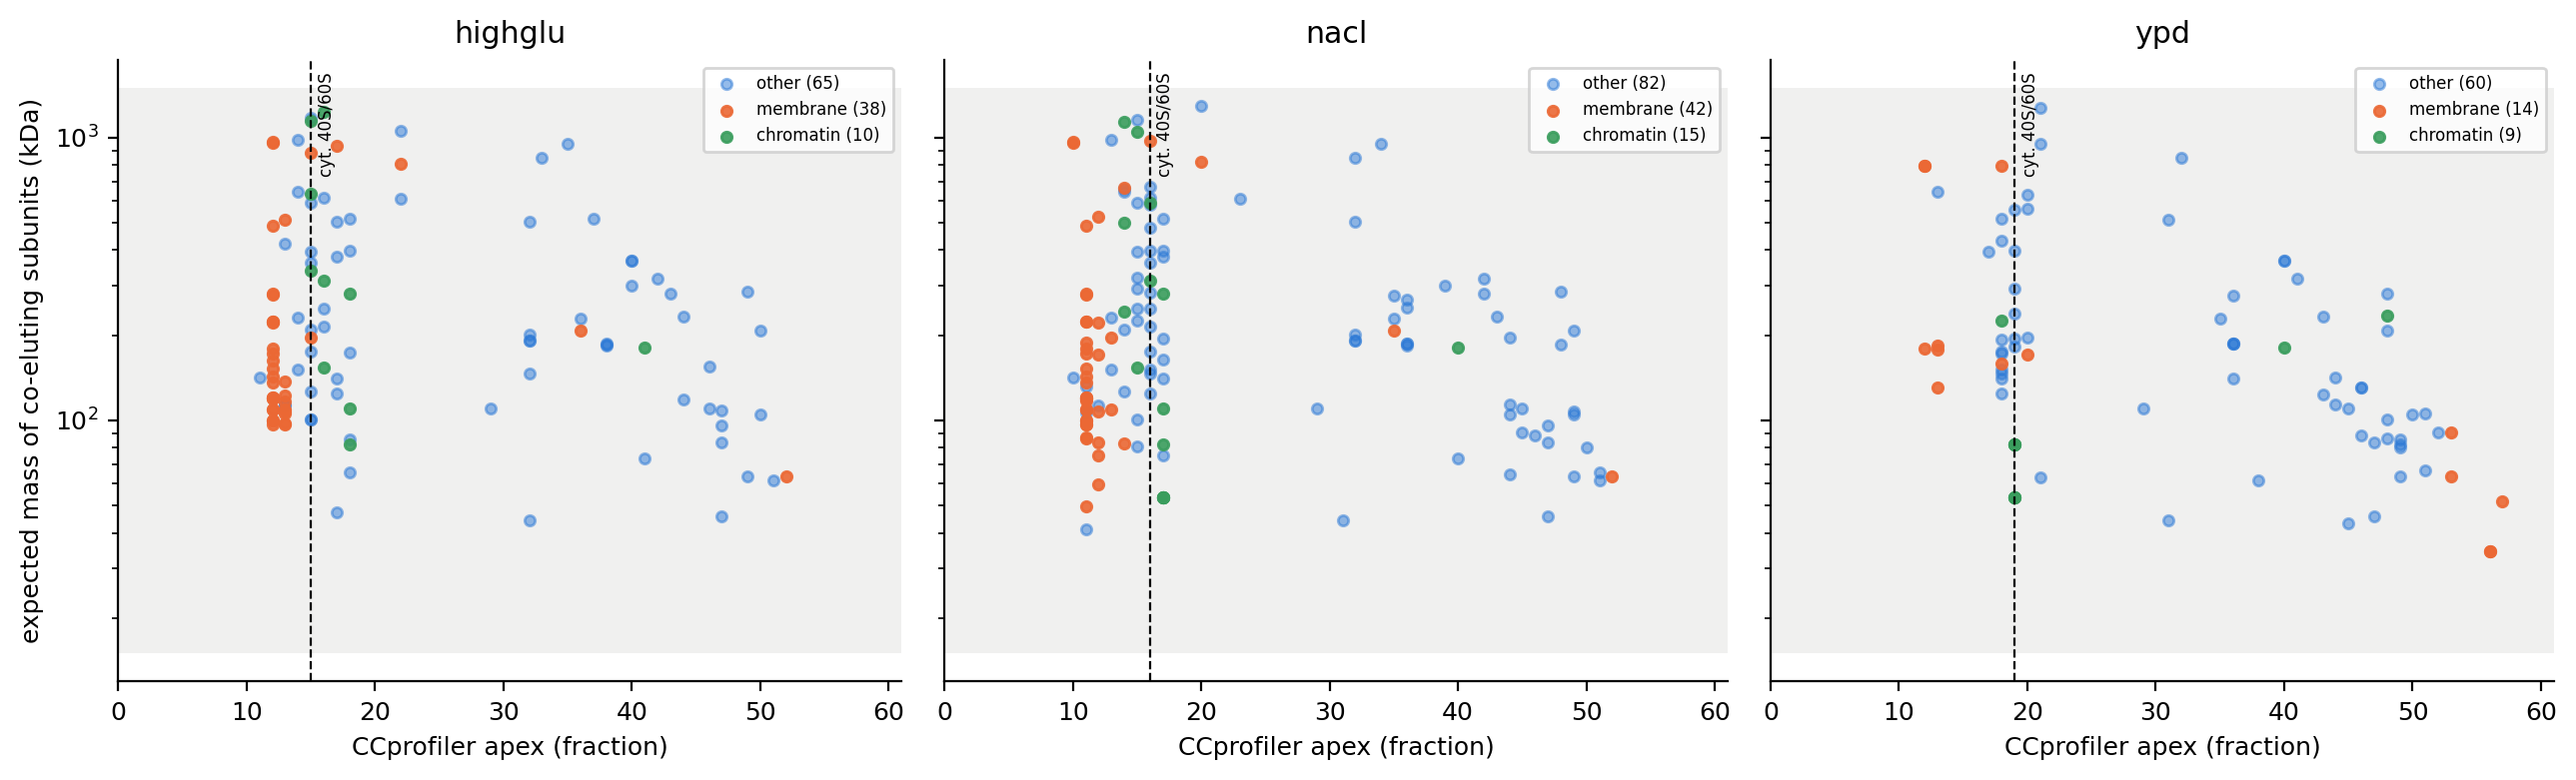

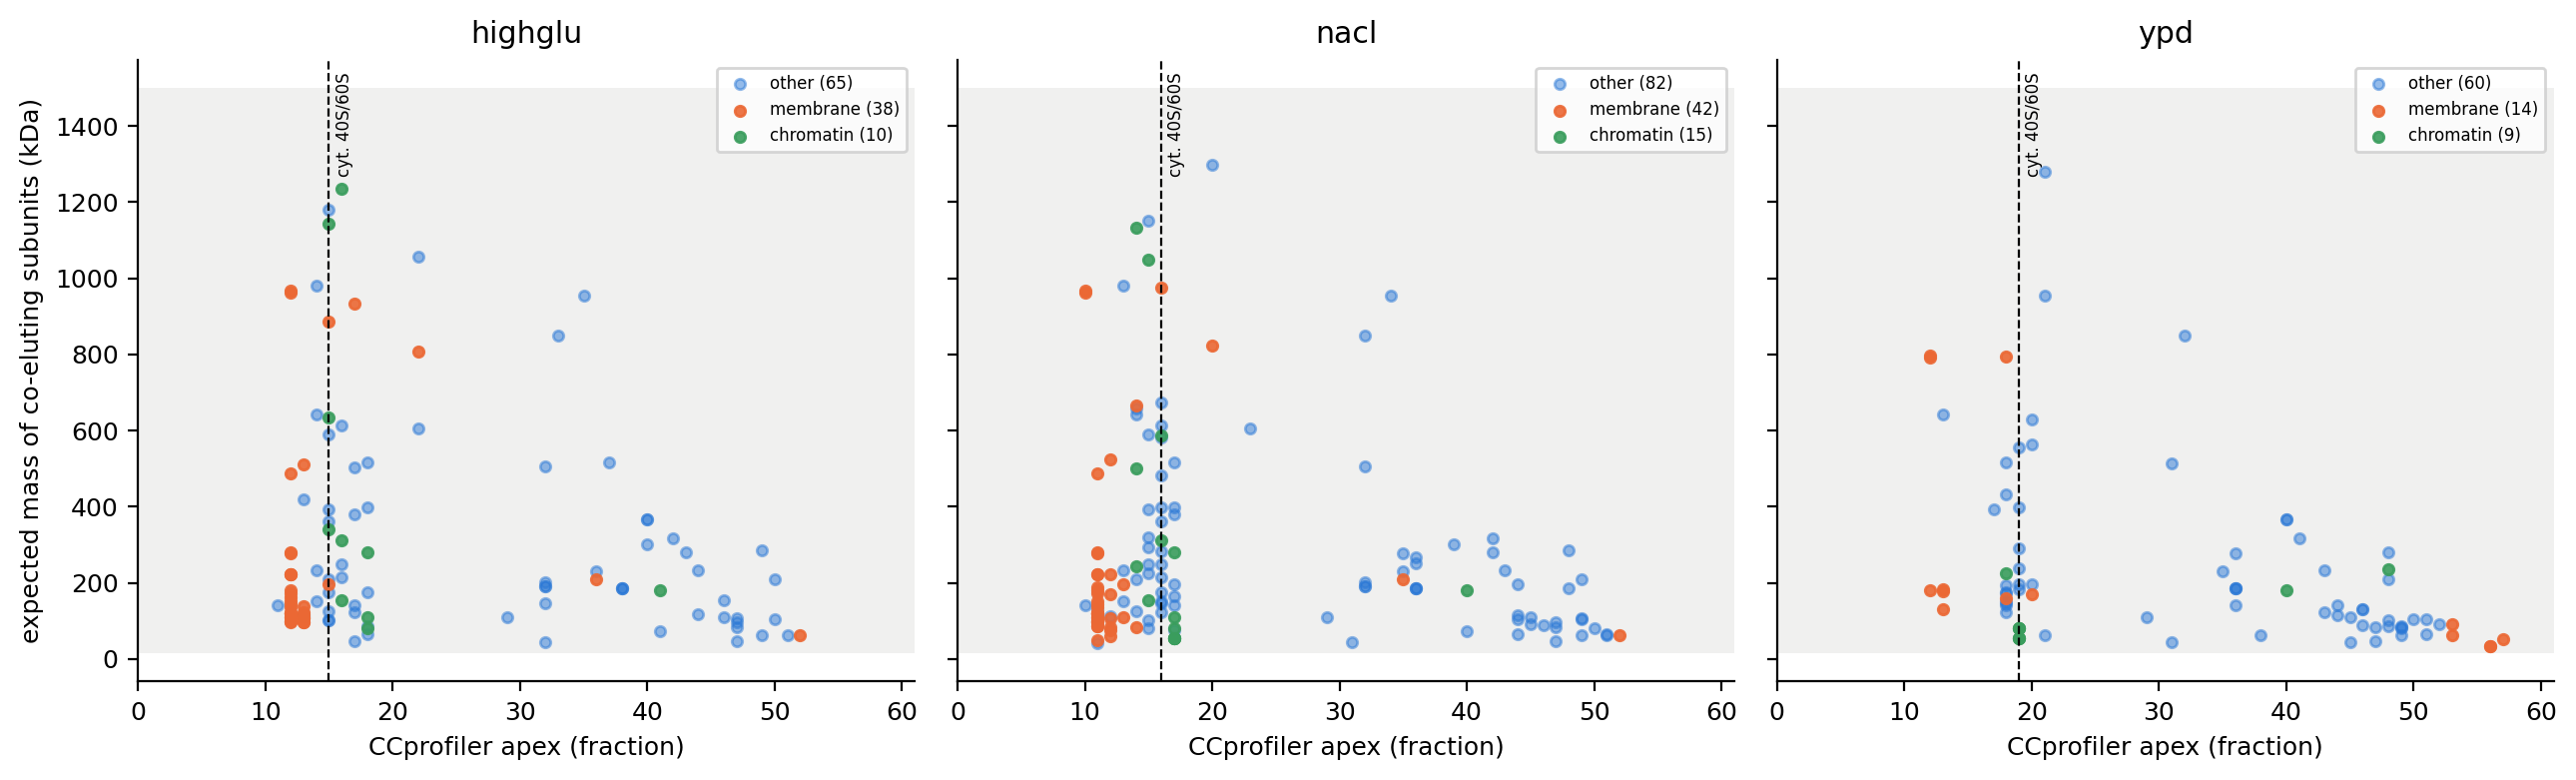

In [49]:
assert 'ribosome_markers' in globals(), 'run the ribosome-marker cell (CYTOSOLIC_RIBOSOME ...) first'
assert 'Go Annotations' in portal.columns, f'no GO column in Complex Portal file: {portal.columns}'

WINDOW_KDA = (15, 1500)        # resolvable range of the column (from the lab)
MEMBRANE_TERMS = 'membrane'
CHROMATIN_TERMS = 'chromatin|nucleosome|histone'


# --- category per complex from its Complex Portal GO term names ---
complex_categories = (
    portal.select(complex_id='#Complex ac', go_annotations=pl.col('Go Annotations').fill_null('').str.to_lowercase())
    .with_columns(is_membrane=pl.col('go_annotations').str.contains(MEMBRANE_TERMS),
                  is_chromatin=pl.col('go_annotations').str.contains(CHROMATIN_TERMS))
    .with_columns(category=pl.when(pl.col('is_membrane') & pl.col('is_chromatin')).then(pl.lit('membrane + chromatin'))
                             .when('is_membrane').then(pl.lit('membrane'))
                             .when('is_chromatin').then(pl.lit('chromatin'))
                             .otherwise(pl.lit('other')))
    .select('complex_id', 'category'))
complex_masses_with_category = complex_masses.join(complex_categories, on='complex_id', how='left')
assert complex_masses_with_category['category'].null_count() == 0, 'plotted complex missing from Complex Portal table'
complex_masses_with_category = complex_masses.join(complex_categories, on='complex_id', how='left')
assert complex_masses_with_category['category'].null_count() == 0, 'plotted complex missing from Complex Portal table'

# megadalton complexes above the column's resolvable range (PDH ~5.7 MDa, FAS ~2.6 MDa): apex carries no size information
EXCLUDED_FROM_PLOT = {'CPX-3207': 'Mitochondrial pyruvate dehydrogenase complex', 'CPX-1162': 'Fatty-acyl-CoA synthase'}
assert set(EXCLUDED_FROM_PLOT) <= set(complex_masses_with_category['complex_id']), 'an excluded complex is not in the table'
complex_masses_with_category = complex_masses_with_category.filter(~pl.col('complex_id').is_in(list(EXCLUDED_FROM_PLOT)))
print(f'excluded from the plot: {EXCLUDED_FROM_PLOT}')

with pl.Config(tbl_rows=-1, fmt_str_lengths=70):
    print(complex_masses_with_category.filter(pl.col('category') != 'other')
          .unique('complex_id').select('category', 'complex_id', 'complex_name').sort('category', 'complex_name'))

# --- how many complexes could in theory be detected, per condition ---
searched_members = complex_members.select('complex_id', 'protein_id')         # Complex Portal targets given to CCprofiler
n_searched = searched_members['complex_id'].n_unique()
detection_count_rows = []
for condition in CONDITIONS:
    measured_protein_ids = profiles_wide[condition].filter(pl.sum_horizontal(FRACTION_COLUMNS) > 0)['ID'].to_list()
    n_with_two_measured = (searched_members.filter(pl.col('protein_id').is_in(measured_protein_ids))
                           .group_by('complex_id').len().filter(pl.col('len') >= 2).height)
    detection_count_rows.append(dict(
        condition=condition, searched=n_searched, with_at_least_2_subunits_measured=n_with_two_measured,
        significant=best_features.filter((pl.col('condition') == condition) & ~pl.col('complex_id').str.starts_with('ANCHOR')).height,
        plotted_copies_and_masses_known=complex_masses.filter(pl.col('condition') == condition).height))
detection_counts = pl.DataFrame(detection_count_rows)
print(detection_counts)

CATEGORY_COLOURS = {'other': BLUE, 'membrane': ORANGE, 'chromatin': '#3a9d5d', 'membrane + chromatin': '#8e5bb5'}

def plot_apex_vs_mass(log_scale):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
    for ax, condition in zip(axes, CONDITIONS):
        table = complex_masses_with_category.filter(pl.col('condition') == condition)
        counts = detection_counts.filter(pl.col('condition') == condition).row(0, named=True)
        ax.axhspan(*WINDOW_KDA, color=GREY, alpha=0.12, lw=0)
        for apex, subunits in (ribosome_markers.filter(pl.col('condition') == condition)
                               .group_by('apex_of_median_profile').agg(pl.col('subunit').sort()).iter_rows()):
            ax.axvline(apex, color='k', ls='--', lw=0.8)
            ax.text(apex + 0.5, 0.98, f"cyt. {'/'.join(subunits)}", fontsize=6, rotation=90, va='top',
                    transform=ax.get_xaxis_transform())
        for category, colour in CATEGORY_COLOURS.items():
            subset = table.filter(pl.col('category') == category)
            if subset.height == 0:
                continue
            ax.scatter(subset['apex'], subset['mass_detected_subunits_kda'], s=14, c=colour,
                       alpha=0.5 if category == 'other' else 0.9, label=f'{category} ({subset.height})')
            ax.set(xlim=(0, N_FRACTIONS + 1), xlabel='CCprofiler apex (fraction)')
            ax.set_title(f"{condition}")
        if log_scale:
            ax.set_yscale('log')
        ax.legend(fontsize=6, loc='upper right')
    axes[0].set_ylabel('expected mass of co-eluting subunits (kDa)')
    plt.tight_layout(); plt.show()

plot_apex_vs_mass(log_scale=True)
plot_apex_vs_mass(log_scale=False)

excluded from the plot (above column range): {'CPX-3207': 'Mitochondrial pyruvate dehydrogenase complex', 'CPX-1162': 'Fatty-acyl-CoA synthase'}
hidden as membrane / cytoskeletal: 60 complexes
shape: (60, 4)
┌─────────────┬─────────────────┬────────────┬─────────────────────────────────────────────────────┐
│ is_membrane ┆ is_cytoskeletal ┆ complex_id ┆ complex_name                                        │
│ ---         ┆ ---             ┆ ---        ┆ ---                                                 │
│ bool        ┆ bool            ┆ str        ┆ str                                                 │
╞═════════════╪═════════════════╪════════════╪═════════════════════════════════════════════════════╡
│ false       ┆ true            ┆ CPX-1039   ┆ COMPASS complex                                     │
│ false       ┆ true            ┆ CPX-422    ┆ DNA replication factor C complex, ELG1 variant      │
│ false       ┆ true            ┆ CPX-3215   ┆ FACT complex                          

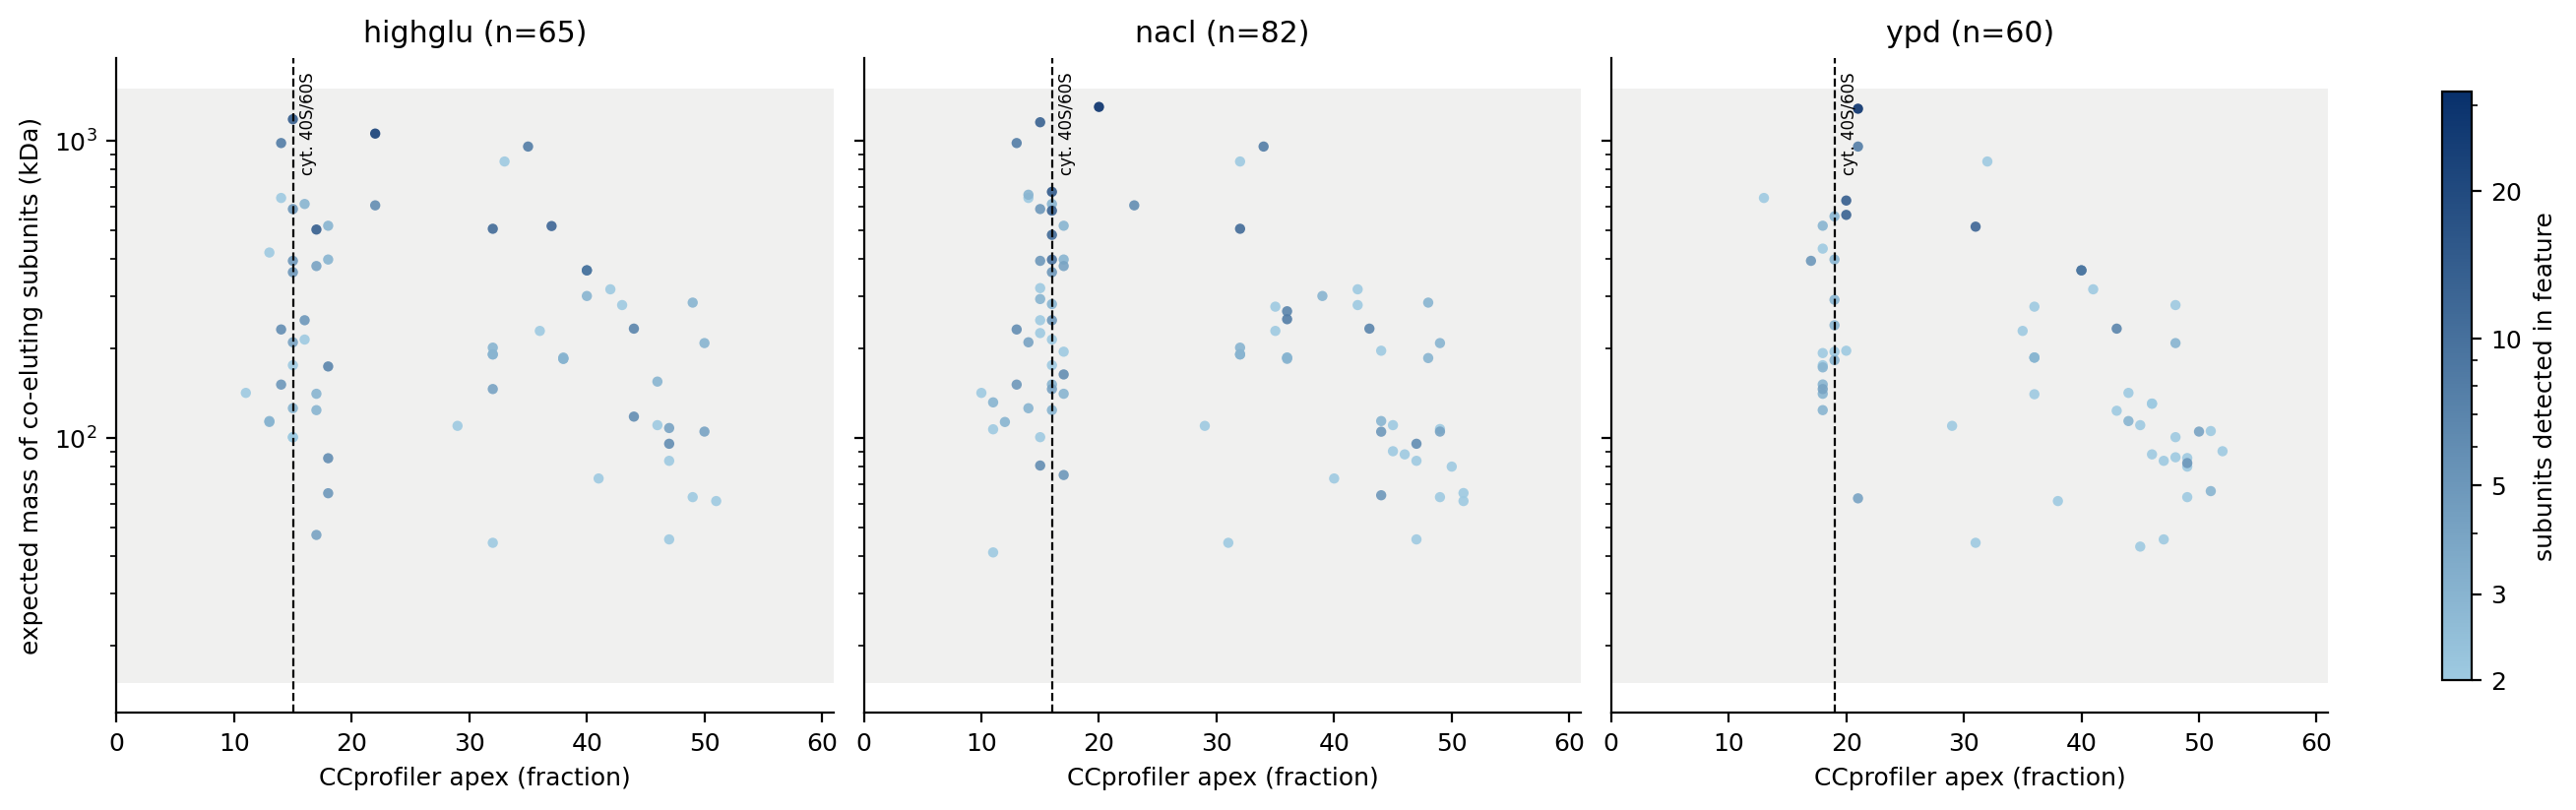

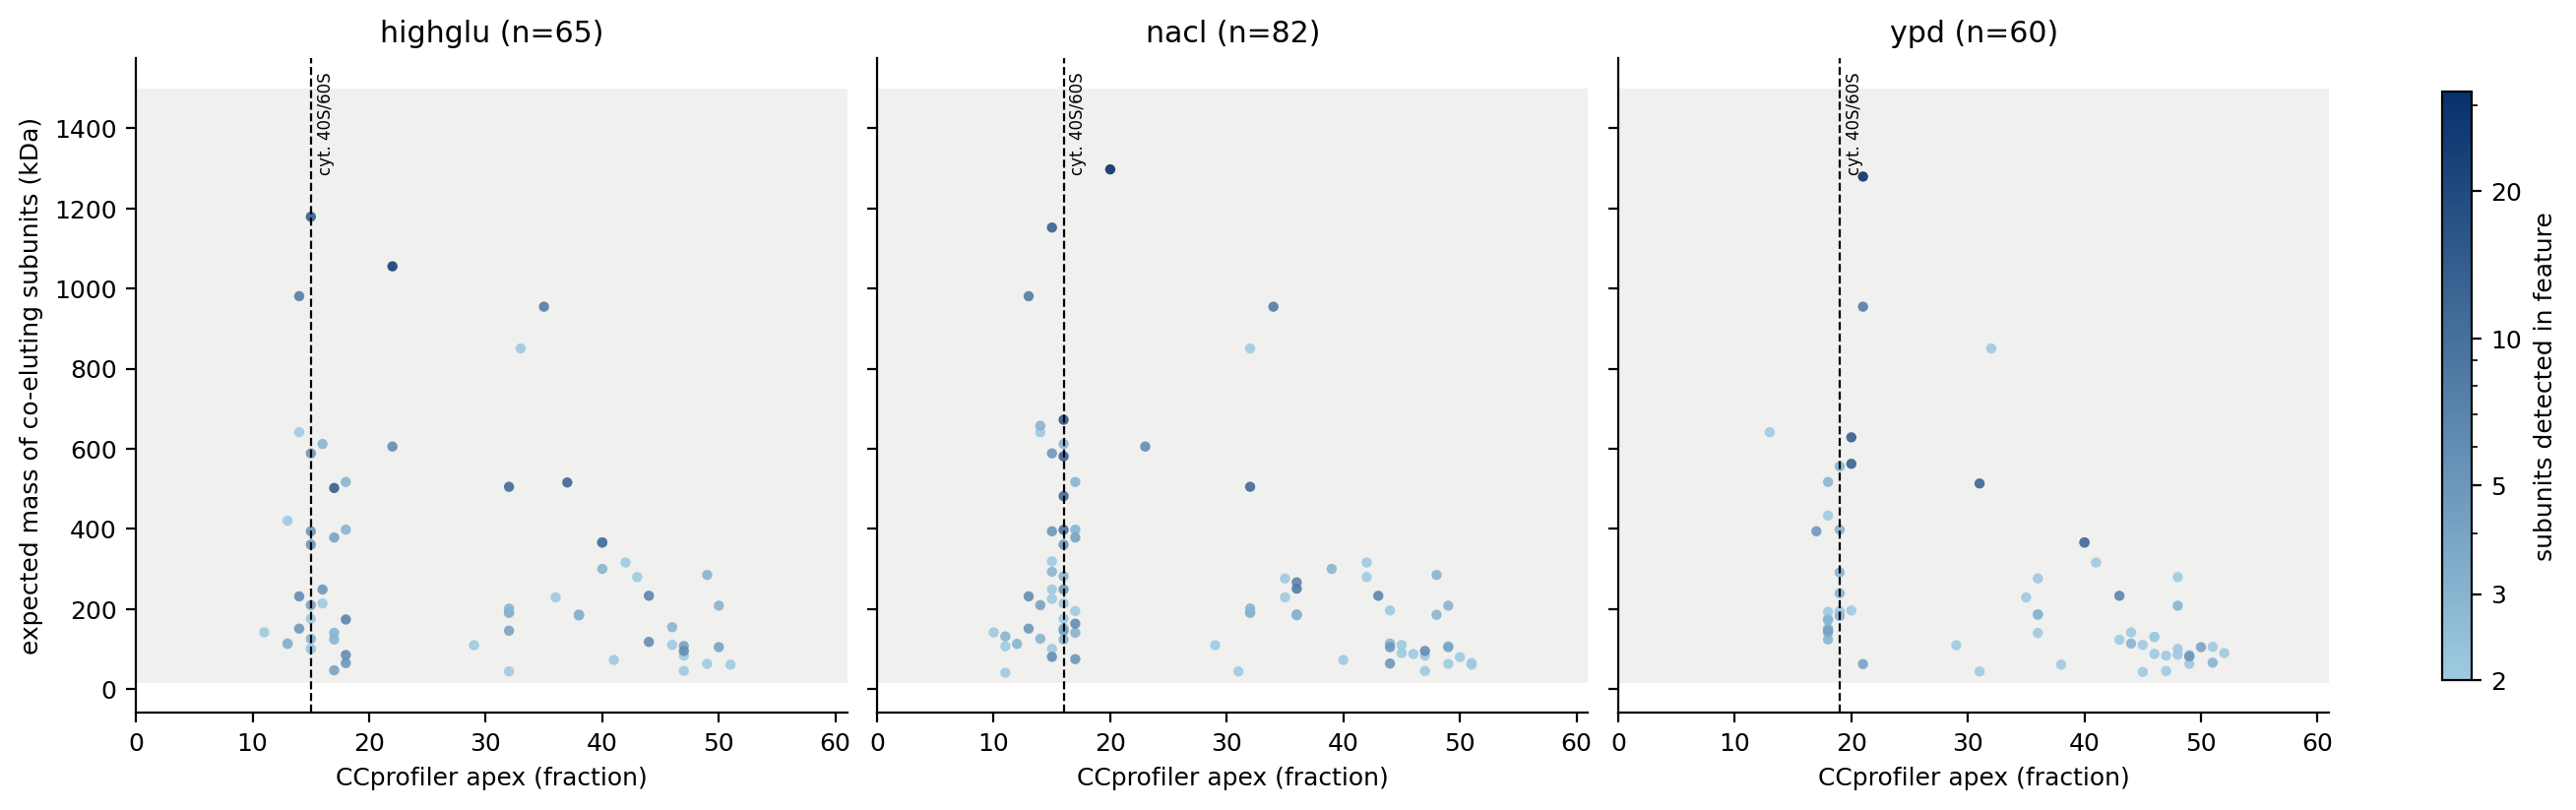

In [29]:
#are maybe the complexes detected prior ribisome that arent mebane bound just where 2 subunits were detected, doenst seem so

assert 'ribosome_markers' in globals(), 'run the ribosome-marker cell (CYTOSOLIC_RIBOSOME ...) first'
assert 'Go Annotations' in portal.columns, f'no GO column in Complex Portal file: {portal.columns}'
assert 'n_subunits_detected' in complex_masses.columns, f'no n_subunits_detected column: {complex_masses.columns}'

WINDOW_KDA = (15, 1500)        # resolvable range of the column (from the lab)
MEMBRANE_TERMS = 'membrane'
CHROMATIN_TERMS = r'chromatin|nucleosome|histone'

# --- membrane / cytoskeletal flags per complex from its Complex Portal GO term names ---
complex_go_flags = (
    portal.select(complex_id='#Complex ac', go_annotations=pl.col('Go Annotations').str.to_lowercase())
    .with_columns(has_go_annotation=pl.col('go_annotations').is_not_null(),
                  is_membrane=pl.col('go_annotations').fill_null('').str.contains(MEMBRANE_TERMS),
                  is_cytoskeletal=pl.col('go_annotations').fill_null('').str.contains(CHROMATIN_TERMS))
    .select('complex_id', 'has_go_annotation', 'is_membrane', 'is_cytoskeletal'))
complex_masses_with_flags = complex_masses.join(complex_go_flags, on='complex_id', how='left')
assert complex_masses_with_flags['is_membrane'].null_count() == 0, 'plotted complex missing from Complex Portal table'

# megadalton complexes above the column's resolvable range (PDH ~5.7 MDa, FAS ~2.6 MDa): apex carries no size information
EXCLUDED_FROM_PLOT = {'CPX-3207': 'Mitochondrial pyruvate dehydrogenase complex', 'CPX-1162': 'Fatty-acyl-CoA synthase'}
assert set(EXCLUDED_FROM_PLOT) <= set(complex_masses_with_flags['complex_id']), 'an excluded complex is not in the table'
print(f'excluded from the plot (above column range): {EXCLUDED_FROM_PLOT}')

hidden_complexes = (complex_masses_with_flags.filter(pl.col('is_membrane') | pl.col('is_cytoskeletal'))
                    .unique('complex_id')
                    .select('is_membrane', 'is_cytoskeletal', 'complex_id', 'complex_name')
                    .sort('is_membrane', 'is_cytoskeletal', 'complex_name'))
assert hidden_complexes.height > 0, 'no membrane/cytoskeletal complex matched, check the GO term patterns'
print(f'hidden as membrane / cytoskeletal: {hidden_complexes.height} complexes')
with pl.Config(tbl_rows=-1, fmt_str_lengths=70):
    print(hidden_complexes)

complex_masses_for_plot = complex_masses_with_flags.filter(
    ~pl.col('is_membrane') & ~pl.col('is_cytoskeletal') & ~pl.col('complex_id').is_in(list(EXCLUDED_FROM_PLOT)))
n_plotted_without_go = complex_masses_for_plot.unique('complex_id').filter(~pl.col('has_go_annotation')).height
print(f'plotted complexes without any GO annotation (cannot be checked, kept visible): {n_plotted_without_go}')

# --- how many complexes could in theory be detected, per condition ---
searched_members = complex_members.select('complex_id', 'protein_id')         # Complex Portal targets given to CCprofiler
n_searched = searched_members['complex_id'].n_unique()
detection_count_rows = []
for condition in CONDITIONS:
    measured_protein_ids = profiles_wide[condition].filter(pl.sum_horizontal(FRACTION_COLUMNS) > 0)['ID'].to_list()
    n_with_two_measured = (searched_members.filter(pl.col('protein_id').is_in(measured_protein_ids))
                           .group_by('complex_id').len().filter(pl.col('len') >= 2).height)
    detection_count_rows.append(dict(
        condition=condition, searched=n_searched, with_at_least_2_subunits_measured=n_with_two_measured,
        significant=best_features.filter((pl.col('condition') == condition) & ~pl.col('complex_id').str.starts_with('ANCHOR')).height,
        plotted_copies_and_masses_known=complex_masses.filter(pl.col('condition') == condition).height,
        plotted_after_hiding=complex_masses_for_plot.filter(pl.col('condition') == condition).height))
detection_counts = pl.DataFrame(detection_count_rows)
print(detection_counts)

# --- colour = number of subunits detected in the feature: 2 = light blue, more = darker blue ---
min_subunits_detected = complex_masses_for_plot['n_subunits_detected'].min()
max_subunits_detected = complex_masses_for_plot['n_subunits_detected'].max()
assert min_subunits_detected >= 2, f'feature with fewer than 2 detected subunits: {min_subunits_detected}'
assert max_subunits_detected > 2, 'all plotted features have exactly 2 detected subunits, no colour range'
SUBUNIT_COLOURMAP = mcolors.LinearSegmentedColormap.from_list('light_to_dark_blue', ['#9ecae1', '#08306b'])
subunit_norm = mcolors.LogNorm(vmin=2, vmax=max_subunits_detected)            # same scale in all panels

def plot_apex_vs_mass(log_scale):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout='constrained')
    for ax, condition in zip(axes, CONDITIONS):
        table = (complex_masses_for_plot.filter(pl.col('condition') == condition)
                 .sort('n_subunits_detected'))                                 # darkest points drawn last, on top
        ax.axhspan(*WINDOW_KDA, color=GREY, alpha=0.12, lw=0)
        for apex, subunits in (ribosome_markers.filter(pl.col('condition') == condition)
                               .group_by('apex_of_median_profile').agg(pl.col('subunit').sort()).iter_rows()):
            ax.axvline(apex, color='k', ls='--', lw=0.8)
            ax.text(apex + 0.5, 0.98, f"cyt. {'/'.join(subunits)}", fontsize=6, rotation=90, va='top',
                    transform=ax.get_xaxis_transform())
        ax.scatter(table['apex'], table['mass_detected_subunits_kda'], s=14,
                   c=table['n_subunits_detected'].to_numpy(), cmap=SUBUNIT_COLOURMAP, norm=subunit_norm,
                   alpha=0.9, edgecolors='none')
        ax.set(xlim=(0, N_FRACTIONS + 1), xlabel='CCprofiler apex (fraction)')
        ax.set_title(f'{condition} (n={table.height})')
        if log_scale:
            ax.set_yscale('log')
    axes[0].set_ylabel('expected mass of co-eluting subunits (kDa)')
    colorbar = fig.colorbar(cm.ScalarMappable(norm=subunit_norm, cmap=SUBUNIT_COLOURMAP), ax=axes.tolist(),
                            label='subunits detected in feature', shrink=0.9)
    tick_values = [value for value in (2, 3, 5, 10, 20, 40, 80) if value <= max_subunits_detected]
    colorbar.set_ticks(tick_values)
    colorbar.set_ticklabels([str(value) for value in tick_values])
    plt.show()

plot_apex_vs_mass(log_scale=True)
plot_apex_vs_mass(log_scale=False)

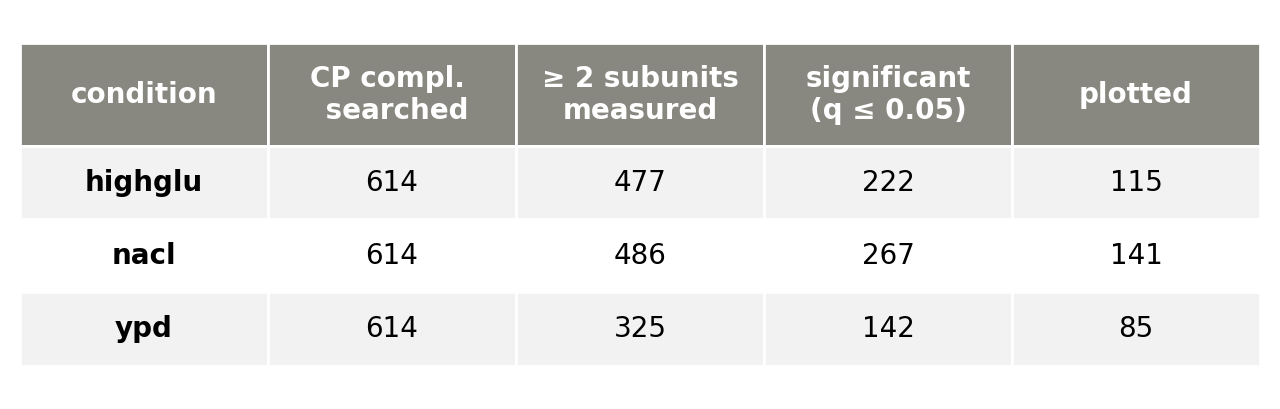

In [32]:
table_columns = {
    'condition': 'condition',
    'searched': 'CP compl. \n searched',
    'with_at_least_2_subunits_measured': '≥ 2 subunits\nmeasured',
    'significant': f'significant\n(q ≤ {Q_CUTOFF})',
    'plotted_copies_and_masses_known': 'plotted',
}
assert set(table_columns) <= set(detection_counts.columns), f'missing columns: {set(table_columns) - set(detection_counts.columns)}'

table_rows = [[str(value) for value in row] for row in detection_counts.select(list(table_columns)).iter_rows()]

fig, ax = plt.subplots(figsize=(8, 0.8 + 0.4 * (len(table_rows) + 1)))
ax.axis('off')
slide_table = ax.table(cellText=table_rows, colLabels=list(table_columns.values()), cellLoc='center', loc='center')
slide_table.auto_set_font_size(False)
slide_table.set_fontsize(10)
slide_table.scale(1, 2.2)
for (row_index, column_index), cell in slide_table.get_celld().items():
    cell.set_edgecolor('white')
    if row_index == 0:
        cell.set_facecolor(GREY)
        cell.set_text_props(color='white', fontweight='bold')
        cell.set_height(cell.get_height() * 1.4)
    else:
        cell.set_facecolor('#f2f2f2' if row_index % 2 else 'white')
        if column_index == 0:
            cell.set_text_props(fontweight='bold')
plt.show()

In [34]:
complexes_above_window = (complex_masses
    .filter(pl.col('mass_detected_subunits_kda') > WINDOW_KDA[1])
    .select('condition', 'complex_id', 'complex_name', 'apex', 'n_subunits_detected', 'n_subunits_annotated',
            'mass_detected_subunits_kda', 'has_non_protein')
    .sort('mass_detected_subunits_kda', 'condition', descending=[True, False]))

with pl.Config(tbl_rows=-1, fmt_str_lengths=70):
    print(complexes_above_window)

# copy numbers behind the large masses: which subunits contribute most
with pl.Config(tbl_rows=-1, fmt_str_lengths=70):
    print(feature_subunits
          .filter(pl.col('complex_id').is_in(complexes_above_window['complex_id'].unique().to_list()))
          .unique(['complex_id', 'protein_id'])
          .select('complex_id', 'complex_name', 'protein_id', 'copies', 'mass_kda',
                  subunit_mass_kda=(pl.col('copies') * pl.col('mass_kda')).round(0))
          .sort('complex_id', 'subunit_mass_kda', descending=[False, True]))

shape: (6, 8)
┌───────────┬────────────┬─────────────┬──────┬─────────────┬────────────┬────────────┬────────────┐
│ condition ┆ complex_id ┆ complex_nam ┆ apex ┆ n_subunits_ ┆ n_subunits ┆ mass_detec ┆ has_non_pr │
│ ---       ┆ ---        ┆ e           ┆ ---  ┆ detected    ┆ _annotated ┆ ted_subuni ┆ otein      │
│ str       ┆ str        ┆ ---         ┆ i64  ┆ ---         ┆ ---        ┆ ts_kda     ┆ ---        │
│           ┆            ┆ str         ┆      ┆ i64         ┆ i64        ┆ ---        ┆ bool       │
│           ┆            ┆             ┆      ┆             ┆            ┆ f64        ┆            │
╞═══════════╪════════════╪═════════════╪══════╪═════════════╪════════════╪════════════╪════════════╡
│ highglu   ┆ CPX-3207   ┆ Mitochondri ┆ 15   ┆ 4           ┆ 5          ┆ 5726.88838 ┆ false      │
│           ┆            ┆ al pyruvate ┆      ┆             ┆            ┆ 9          ┆            │
│           ┆            ┆ dehydrogena ┆      ┆             ┆            ┆   

Rank correlation between apex and log mass, using only complexes that peak at or after a given fraction (a size-resolved region should show a clearly negative rho).

In [35]:
correlation_rows = []
for condition in CONDITIONS:
    table = complex_masses.filter(pl.col('condition') == condition)
    for first_fraction in range(1, 31, 3):
        subset = table.filter(pl.col('apex') >= first_fraction)
        if subset.height < 8:
            continue
        rho, p_value = spearmanr(subset['apex'], np.log10(subset['mass_detected_subunits_kda']))
        correlation_rows.append(dict(condition=condition, from_fraction=first_fraction, n=subset.height, rho=round(rho, 2), p=round(p_value, 3)))
pl.DataFrame(correlation_rows).pivot(on='condition', index='from_fraction', values=['rho', 'p', 'n'])

from_fraction,rho_highglu,rho_nacl,rho_ypd,p_highglu,p_nacl,p_ypd,n_highglu,n_nacl,n_ypd
i64,f64,f64,f64,f64,f64,f64,i64,i64,i64
1,-0.03,-0.06,-0.45,0.786,0.51,0.0,115,141,85
4,-0.03,-0.06,-0.45,0.786,0.51,0.0,115,141,85
7,-0.03,-0.06,-0.45,0.786,0.51,0.0,115,141,85
10,-0.03,-0.06,-0.45,0.786,0.51,0.0,115,141,85
13,-0.16,-0.4,-0.43,0.129,0.0,0.0,91,102,82
16,-0.35,-0.41,-0.43,0.007,0.0,0.0,60,76,78
19,-0.56,-0.63,-0.37,0.0,0.0,0.002,40,46,65
22,-0.56,-0.55,-0.62,0.0,0.0,0.0,40,43,46
25,-0.4,-0.52,-0.59,0.015,0.0,0.0,36,42,45


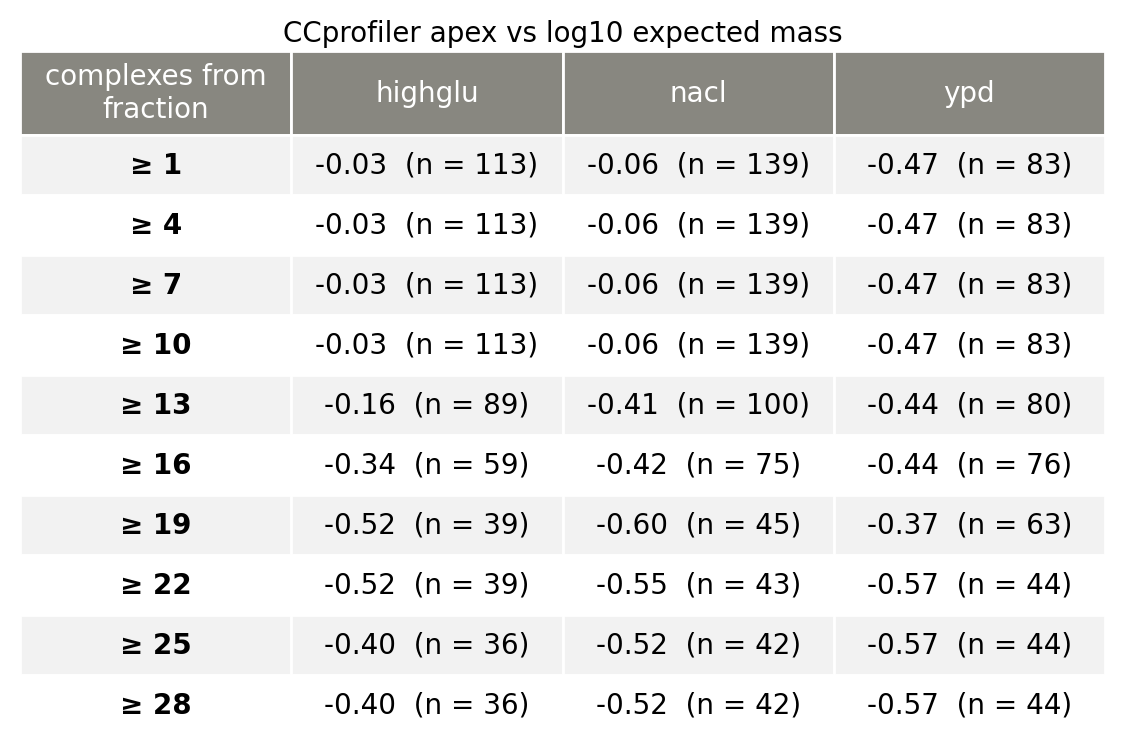

In [36]:
apex_mass_correlation_rows = []
for condition in CONDITIONS:
    condition_masses = complex_masses.filter((pl.col('condition') == condition) & (pl.col('mass_detected_subunits_kda') <= WINDOW_KDA[1]))
    for first_fraction in range(1, 31, 3):
        complexes_from_fraction = condition_masses.filter(pl.col('apex') >= first_fraction)
        if complexes_from_fraction.height < 8:
            continue
        rho, p_value = spearmanr(complexes_from_fraction['apex'], np.log10(complexes_from_fraction['mass_detected_subunits_kda']))
        apex_mass_correlation_rows.append(dict(condition=condition, from_fraction=first_fraction,
                                               n=complexes_from_fraction.height, rho=rho, p=p_value))
apex_mass_correlations = pl.DataFrame(apex_mass_correlation_rows)

from_fractions = sorted(apex_mass_correlations['from_fraction'].unique().to_list())
correlation_lookup = {(row['condition'], row['from_fraction']): row for row in apex_mass_correlations.iter_rows(named=True)}
cell_texts = [[f'≥ {first_fraction}'] + [
                  f"{correlation_lookup[(condition, first_fraction)]['rho']:+.2f}  (n = {correlation_lookup[(condition, first_fraction)]['n']})"
                  if (condition, first_fraction) in correlation_lookup else '–'
                  for condition in CONDITIONS]
              for first_fraction in from_fractions]

fig, ax = plt.subplots(figsize=(7, 0.5 + 0.35 * (len(cell_texts) + 1)))
ax.axis('off')
correlation_table = ax.table(cellText=cell_texts, colLabels=['complexes from\nfraction', *CONDITIONS], cellLoc='center', loc='center')
correlation_table.auto_set_font_size(False)
correlation_table.set_fontsize(10)
correlation_table.scale(1, 1.8)
for (row_index, column_index), cell in correlation_table.get_celld().items():
    cell.set_edgecolor('white')
    if row_index == 0:
        cell.set_facecolor(GREY)
        cell.set_text_props(color='white')
        cell.set_height(cell.get_height() * 1.4)
        continue
    cell.set_facecolor('#f2f2f2' if row_index % 2 else 'white')
    if column_index == 0:
        cell.set_text_props(fontweight='bold')
    else:
        key = (CONDITIONS[column_index - 1], from_fractions[row_index - 1])

ax.set_title('CCprofiler apex vs log10 expected mass', fontsize=10)
plt.show()

## 5b. Calibration from the anchors (CCprofiler `calibrateMW`)

* Complex anchors: apex of their CCprofiler feature, only if q <= cutoff. Mass from the subunits in that feature.
* Single-protein anchors: fraction with the highest raw intensity.

`calibrateMW` fits a straight line of log mass against fraction by ordinary least squares.

In [46]:
complex_anchor_points = (best_features
    .filter(pl.col('complex_id').str.starts_with('ANCHOR'))
    .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
    .explode('protein_id')
    .join(anchor_members.select('complex_id', 'protein_id', 'copies'), on=['complex_id', 'protein_id'])
    .join(protein_info, on='protein_id', how='left')
    .group_by('condition', 'complex_name', 'apex')
    .agg(mass_kda=(pl.col('copies') * pl.col('mass_kda')).sum(), all_masses_known=pl.col('mass_kda').is_not_null().all(),
         n_subunits=pl.len())
    .filter('all_masses_known')
    .select('condition', anchor=pl.col('complex_name'), fraction=pl.col('apex'), mass_kda='mass_kda', how=pl.lit('CCprofiler feature')))

single_rows = []
for condition, wide in profiles_wide.items():
    for anchor, (acc, copies) in SINGLE_PROTEIN_ANCHORS.items():
        row = wide.filter(pl.col('ID') == acc)
        mass_row = protein_info.filter(pl.col('protein_id') == acc)
        if row.height == 0 or mass_row.height == 0:
            continue
        profile = row.select(FRACTION_COLUMNS).to_numpy()[0]
        single_rows.append(dict(condition=condition, anchor=anchor, fraction=int(np.argmax(profile)) + 1,
                                mass_kda=copies * mass_row['mass_kda'][0], how='highest intensity'))
anchor_points = pl.concat([complex_anchor_points, pl.DataFrame(single_rows)]).sort('condition', 'fraction')

anchors_expected = set(SINGLE_PROTEIN_ANCHORS) | set(COMPLEX_ANCHORS)
pl.DataFrame([dict(condition=condition, n_anchors=anchor_points.filter(pl.col('condition') == condition).height,
                   not_found_or_not_significant=sorted(anchors_expected - set(anchor_points.filter(pl.col('condition') == condition)['anchor'])))
              for condition in CONDITIONS])

condition,n_anchors,not_found_or_not_significant
str,i64,list[str]
"""highglu""",12,[]
"""nacl""",12,[]
"""ypd""",10,"[""COPI coatomer"", ""MCM2-7""]"


In [38]:
anchor_points

condition,anchor,fraction,mass_kda,how
str,str,i64,f64,str
"""highglu""","""MCM2-7""",22,605.626807,"""CCprofiler feature"""
"""highglu""","""20S proteasome""",31,765.915143,"""CCprofiler feature"""
"""highglu""","""COPI coatomer""",35,565.041126,"""CCprofiler feature"""
"""highglu""","""CCT / TRiC""",35,954.665797,"""CCprofiler feature"""
"""highglu""","""Gln1 decamer""",41,417.656119,"""highest intensity"""
"""highglu""","""Arp2/3""",44,233.282954,"""CCprofiler feature"""
…,…,…,…,…
"""ypd""","""Tdh3 tetramer""",47,142.985197,"""highest intensity"""
"""ypd""","""Prefoldin""",49,82.426079,"""CCprofiler feature"""


In [39]:
anchor_points.select('condition', std_elu_fractions='fraction', std_weights_kDa='mass_kda').write_csv(f'{WORK_DIR}/calibration_anchors.tsv', separator='\t')

In [40]:
%%R -i WORK_DIR,N_FRACTIONS
anchors <- fread(file.path(WORK_DIR, 'calibration_anchors.tsv'))
calibration_curves <- rbindlist(lapply(c('highglu', 'nacl', 'ypd'), function(condition) {
    anchors_condition <- anchors[anchors$condition == condition]
    stopifnot(nrow(anchors_condition) >= 5)
    calibration <- calibrateMW(anchors_condition, plot = FALSE)
    data.table(condition = condition, fraction = 1:N_FRACTIONS, mass_kda = calibration$FractionToMW(1:N_FRACTIONS))
}))
fwrite(calibration_curves, file.path(WORK_DIR, 'calibration_curves.tsv'), sep = '\t')

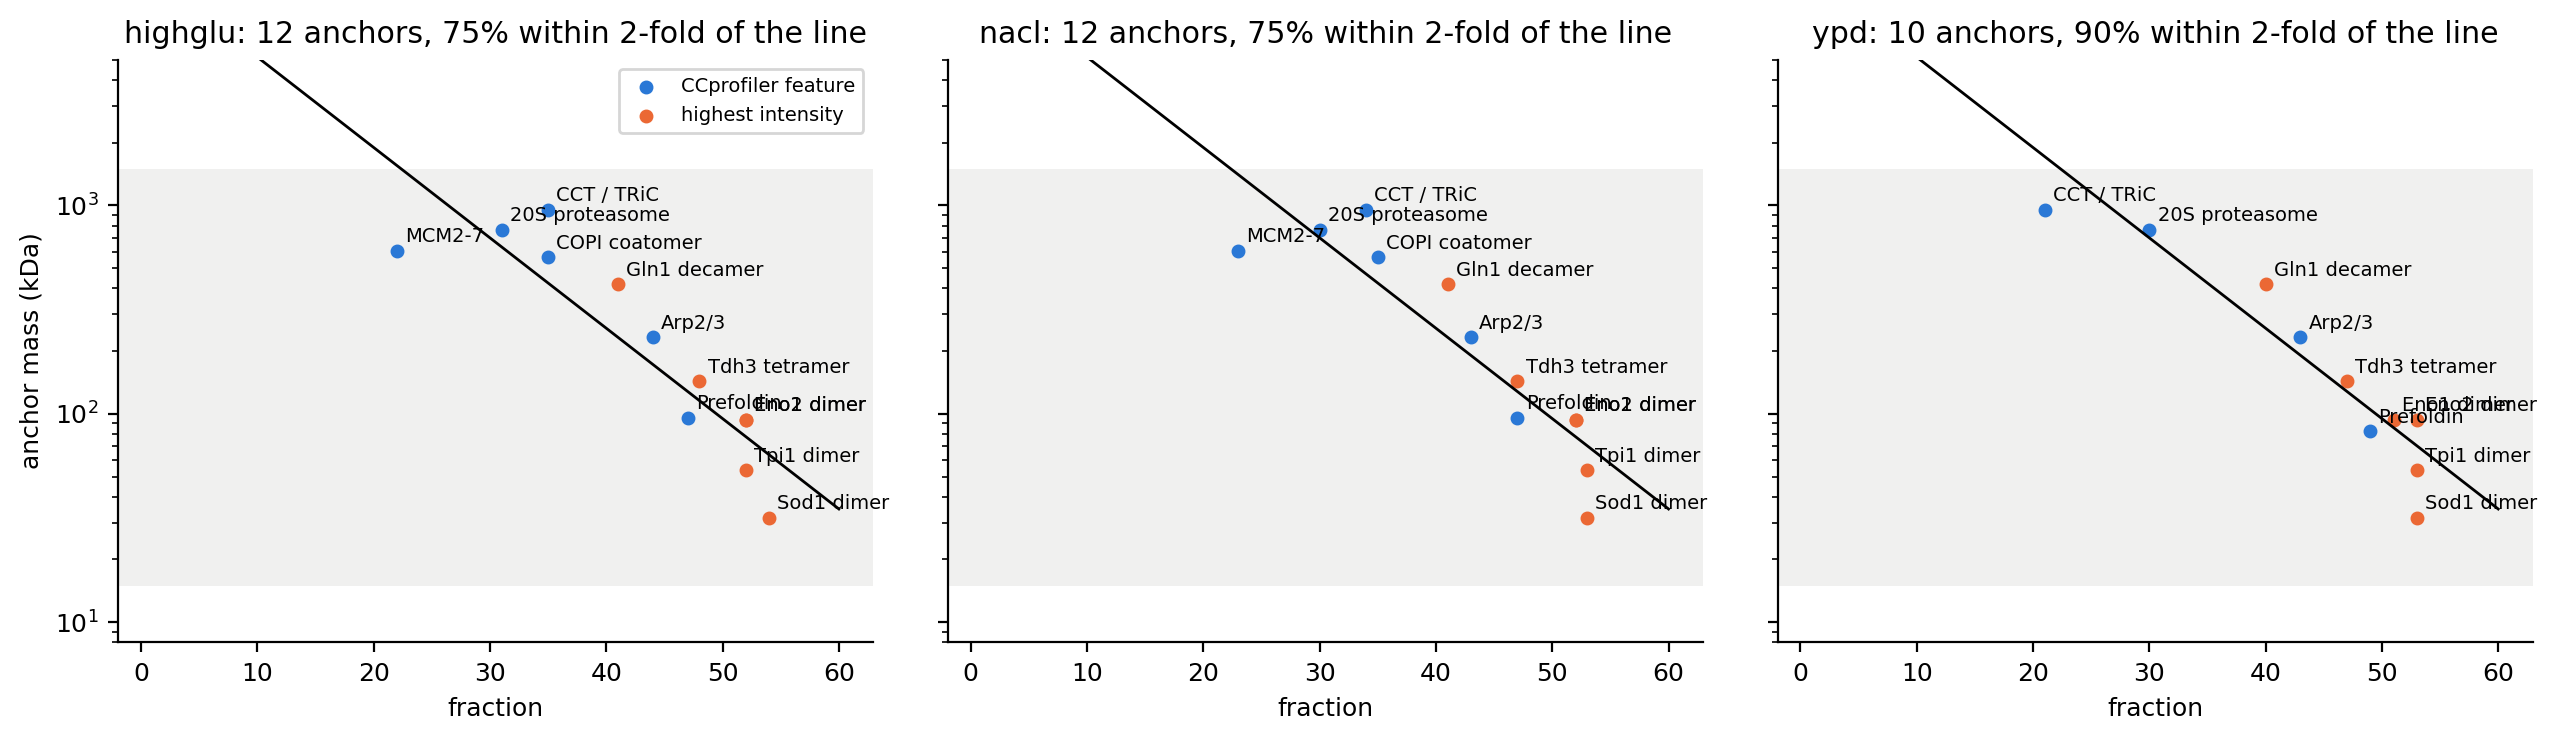

In [44]:
calibration_curves = pl.read_csv(f'{WORK_DIR}/calibration_curves.tsv', separator='\t')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, condition in zip(axes, CONDITIONS):
    points = anchor_points.filter(pl.col('condition') == condition)
    curve = calibration_curves.filter(pl.col('condition') == condition)
    ax.axhspan(*WINDOW_KDA, color=GREY, alpha=0.12, lw=0)
    for how, colour in [('CCprofiler feature', BLUE), ('highest intensity', ORANGE)]:
        subset = points.filter(pl.col('how') == how)
        ax.scatter(subset['fraction'], subset['mass_kda'], s=16, c=colour, label=how)
    for row in points.iter_rows(named=True):
        ax.annotate(row['anchor'], (row['fraction'], row['mass_kda']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.plot(curve['fraction'], curve['mass_kda'], 'k', lw=1)
    log_residual = np.log2(points['mass_kda'].to_numpy() / np.interp(points['fraction'], curve['fraction'], curve['mass_kda']))
    ax.set(yscale='log', ylim=(8, 5000), xlabel='fraction',
           title=f'{condition}: {points.height} anchors, {np.mean(np.abs(log_residual) <= 1):.0%} within 2-fold of the line')
axes[0].set_ylabel('anchor mass (kDa)'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

left out (identical to a calibration anchor):
shape: (11, 5)
┌───────────┬────────────┬───────────────────────────────────┬──────┬────────────────────────────┐
│ condition ┆ complex_id ┆ complex_name                      ┆ apex ┆ mass_detected_subunits_kda │
│ ---       ┆ ---        ┆ ---                               ┆ ---  ┆ ---                        │
│ str       ┆ str        ┆ str                               ┆ i64  ┆ f64                        │
╞═══════════╪════════════╪═══════════════════════════════════╪══════╪════════════════════════════╡
│ highglu   ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 47   ┆ 95.709846                  │
│ nacl      ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 47   ┆ 95.709846                  │
│ ypd       ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 49   ┆ 82.426079                  │
│ highglu   ┆ CPX-2156   ┆ Chaperonin-containing T-complex   ┆ 35   ┆ 954.665797                 │
│ nacl      ┆ CPX-2156   ┆ Chaperonin-containing

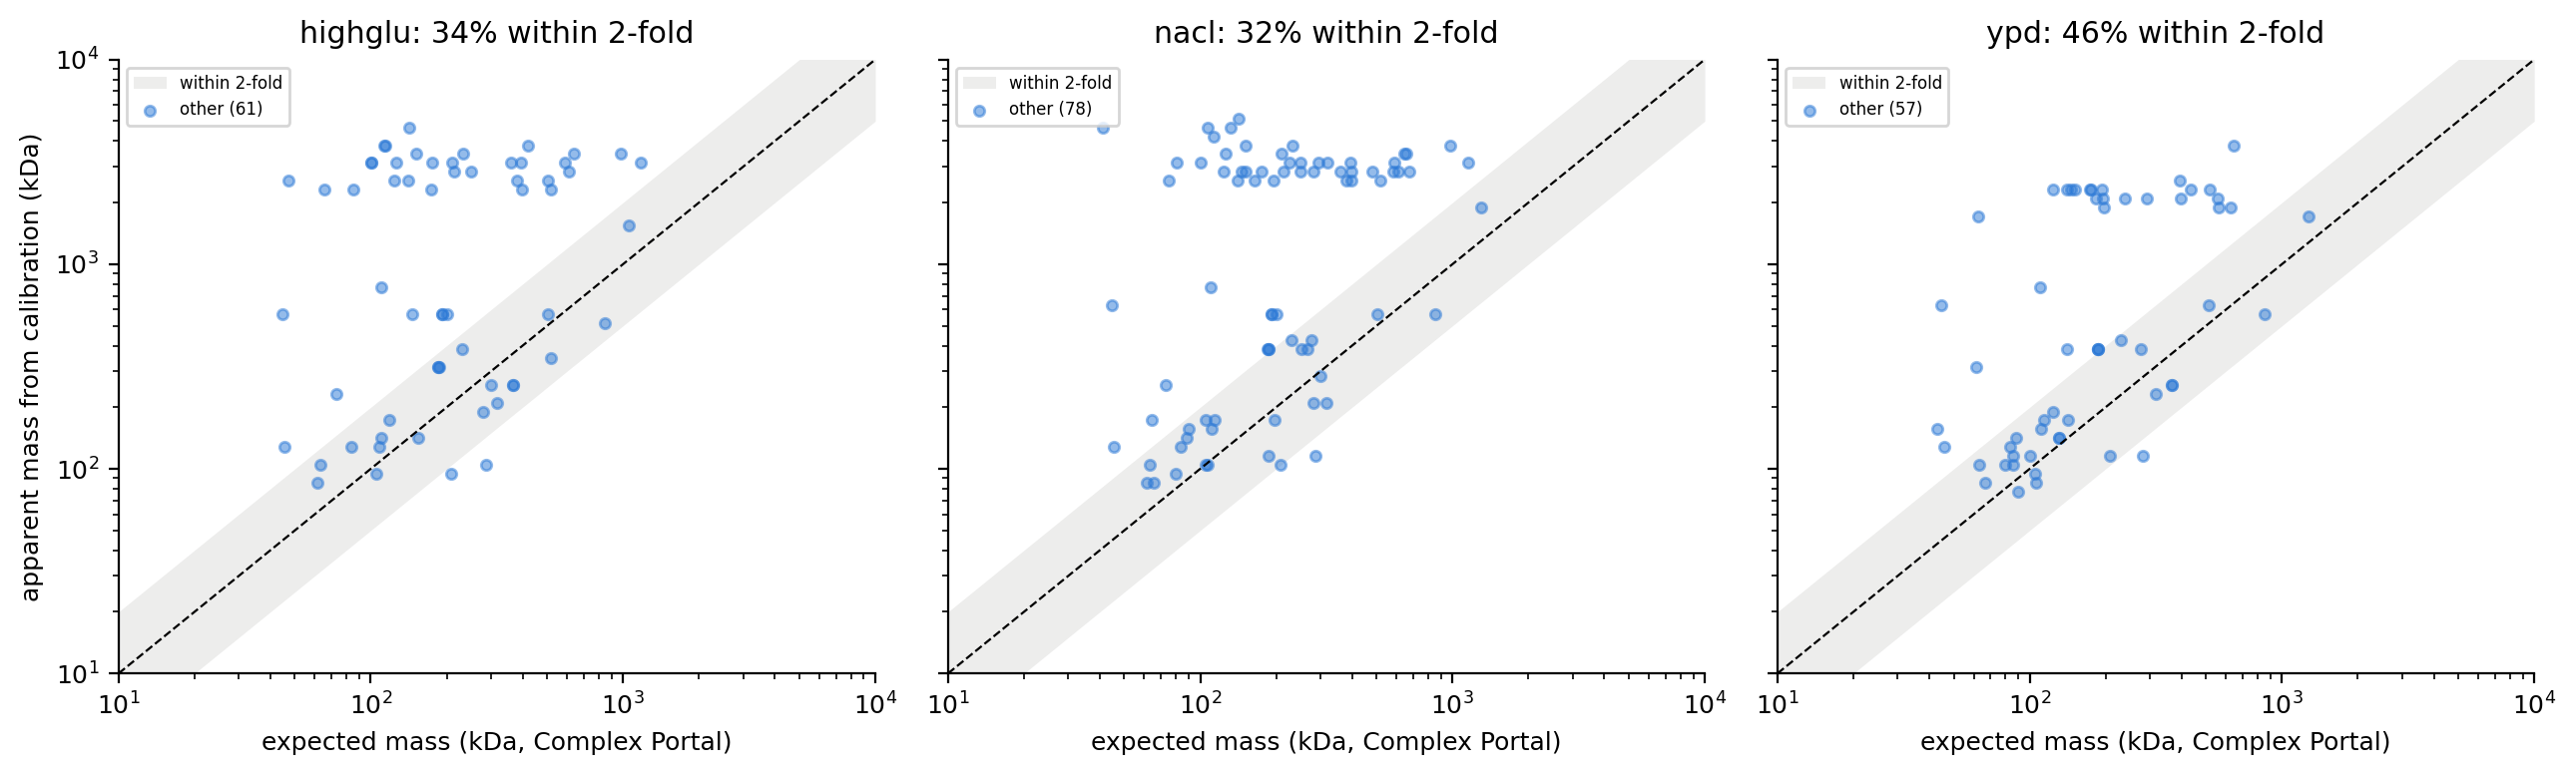

In [50]:
assert 'complex_masses_with_category' in globals(), 'run the apex-vs-mass category cell first'

apparent_vs_expected_mass = (complex_masses_with_category
    .join(calibration_curves.rename({'fraction': 'apex', 'mass_kda': 'apparent_mass_kda'}), on=['condition', 'apex'], how='left')
    .with_columns(log2_apparent_over_expected=(pl.col('apparent_mass_kda') / pl.col('mass_detected_subunits_kda')).log(2))
    .with_columns(within_2_fold=pl.col('log2_apparent_over_expected').abs() <= 1,
                  in_resolvable_range=pl.col('mass_detected_subunits_kda').is_between(*WINDOW_KDA)))
assert apparent_vs_expected_mass['apparent_mass_kda'].null_count() == 0, 'an apex has no calibration value'


# --- leave out the Complex Portal entries that are the calibration anchors themselves (they fit the line by construction) ---
COMPLEX_PORTAL_ANCHOR_DUPLICATES = {
    'CPX-607': 'Arp2/3',
    'CPX-2156': 'CCT / TRiC',
    'CPX-1652': 'COPI coatomer',
    'CPX-2944': 'MCM2-7',
    'CPX-1671': 'Prefoldin',
}
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) <= set(portal['#Complex ac']), \
    f'not in Complex Portal: {set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) - set(portal["#Complex ac"])}'
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES.values()) <= set(COMPLEX_ANCHORS), 'anchor name not in COMPLEX_ANCHORS'

is_anchor_duplicate = pl.col('complex_id').is_in(list(COMPLEX_PORTAL_ANCHOR_DUPLICATES))
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    print('left out (identical to a calibration anchor):')
    print(apparent_vs_expected_mass.filter(is_anchor_duplicate)
          .select('condition', 'complex_id', 'complex_name', 'apex', 'mass_detected_subunits_kda')
          .sort('complex_id', 'condition'))
apparent_vs_expected_mass = apparent_vs_expected_mass.filter(~is_anchor_duplicate)

# summary for all categories, for comparison

apparent_mass_summary = (apparent_vs_expected_mass
    .filter('in_resolvable_range')
    .group_by('condition', 'category')
    .agg(n_complexes=pl.len(),
         share_within_2_fold=pl.col('within_2_fold').mean().round(2),
         median_log2_apparent_over_expected=pl.col('log2_apparent_over_expected').median().round(2))
    .sort('condition', 'category'))
print(apparent_mass_summary)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
mass_axis_range = np.array([10, 10000])
for ax, condition in zip(axes, CONDITIONS):
    condition_complexes = apparent_vs_expected_mass.filter((pl.col('condition') == condition) & pl.col('in_resolvable_range')
                                                           & (pl.col('category') == 'other'))
    ax.fill_between(mass_axis_range, mass_axis_range / 2, mass_axis_range * 2, color=GREY, alpha=0.15, lw=0, label='within 2-fold')
    ax.plot(mass_axis_range, mass_axis_range, 'k--', lw=0.8)
    for category, colour in CATEGORY_COLOURS.items():
        category_complexes = condition_complexes.filter(pl.col('category') == category)
        if category_complexes.height == 0:
            continue
        ax.scatter(category_complexes['mass_detected_subunits_kda'], category_complexes['apparent_mass_kda'], s=14, c=colour,
                   alpha=0.5 if category == 'other' else 0.9, label=f'{category} ({category_complexes.height})')
    ax.set(xscale='log', yscale='log', xlim=mass_axis_range, ylim=mass_axis_range, xlabel='expected mass (kDa, Complex Portal)',
           title=f"{condition}: {condition_complexes['within_2_fold'].mean():.0%} within 2-fold")
    ax.legend(fontsize=6, loc='upper left')
axes[0].set_ylabel('apparent mass from calibration (kDa)')
plt.tight_layout(); plt.show()

left out (identical to a calibration anchor):
shape: (11, 5)
┌───────────┬────────────┬───────────────────────────────────┬──────┬────────────────────────────┐
│ condition ┆ complex_id ┆ complex_name                      ┆ apex ┆ mass_detected_subunits_kda │
│ ---       ┆ ---        ┆ ---                               ┆ ---  ┆ ---                        │
│ str       ┆ str        ┆ str                               ┆ i64  ┆ f64                        │
╞═══════════╪════════════╪═══════════════════════════════════╪══════╪════════════════════════════╡
│ highglu   ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 47   ┆ 95.709846                  │
│ nacl      ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 47   ┆ 95.709846                  │
│ ypd       ┆ CPX-1671   ┆ Prefoldin co-chaperone complex    ┆ 49   ┆ 82.426079                  │
│ highglu   ┆ CPX-2156   ┆ Chaperonin-containing T-complex   ┆ 35   ┆ 954.665797                 │
│ nacl      ┆ CPX-2156   ┆ Chaperonin-containing

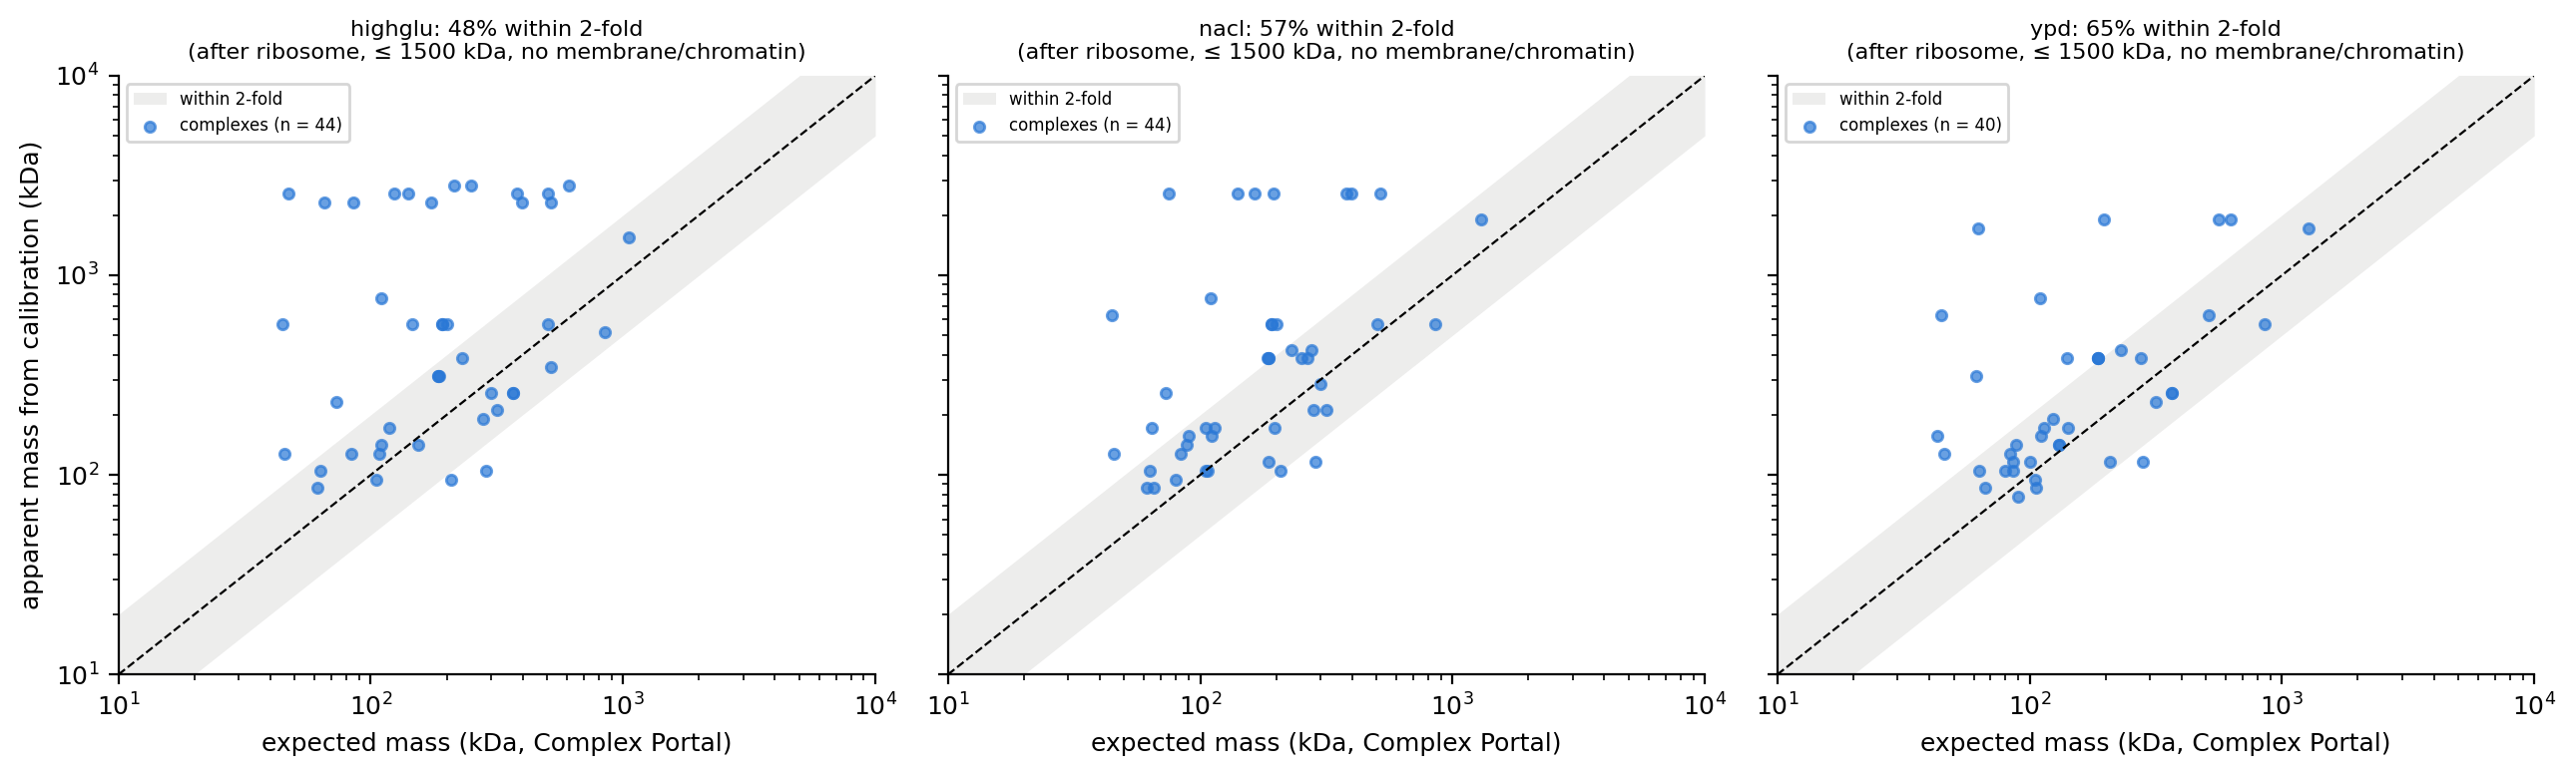

In [51]:
assert 'complex_masses_with_category' in globals(), 'run the apex-vs-mass category cell first'
assert 'ribosome_markers' in globals(), 'run the ribosome-marker cell first'

# ribosome position per condition: earliest of the 40S / 60S marker apexes
ribosome_apex_per_condition = ribosome_markers.group_by('condition').agg(ribosome_apex=pl.col('apex_of_median_profile').min())
assert ribosome_apex_per_condition.height == len(CONDITIONS), 'ribosome apex missing for a condition'

apparent_vs_expected_mass = (complex_masses_with_category
    .join(calibration_curves.rename({'fraction': 'apex', 'mass_kda': 'apparent_mass_kda'}), on=['condition', 'apex'], how='left')
    .join(ribosome_apex_per_condition, on='condition', how='left')
    .with_columns(log2_apparent_over_expected=(pl.col('apparent_mass_kda') / pl.col('mass_detected_subunits_kda')).log(2))
    .with_columns(within_2_fold=pl.col('log2_apparent_over_expected').abs() <= 1,
                  in_resolvable_range=pl.col('mass_detected_subunits_kda').is_between(*WINDOW_KDA),
                  after_ribosome=pl.col('apex') > pl.col('ribosome_apex')))
assert apparent_vs_expected_mass['apparent_mass_kda'].null_count() == 0, 'an apex has no calibration value'

# --- leave out the Complex Portal entries that are the calibration anchors themselves (they fit the line by construction) ---
COMPLEX_PORTAL_ANCHOR_DUPLICATES = {
    'CPX-607': 'Arp2/3',
    'CPX-2156': 'CCT / TRiC',
    'CPX-1652': 'COPI coatomer',
    'CPX-2944': 'MCM2-7',
    'CPX-1671': 'Prefoldin',
}
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) <= set(portal['#Complex ac']), \
    f'not in Complex Portal: {set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) - set(portal["#Complex ac"])}'
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES.values()) <= set(COMPLEX_ANCHORS), 'anchor name not in COMPLEX_ANCHORS'

is_anchor_duplicate = pl.col('complex_id').is_in(list(COMPLEX_PORTAL_ANCHOR_DUPLICATES))
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    print('left out (identical to a calibration anchor):')
    print(apparent_vs_expected_mass.filter(is_anchor_duplicate)
          .select('condition', 'complex_id', 'complex_name', 'apex', 'mass_detected_subunits_kda')
          .sort('complex_id', 'condition'))
apparent_vs_expected_mass = apparent_vs_expected_mass.filter(~is_anchor_duplicate)

# summary for all categories (resolvable range, after ribosome), for comparison
apparent_mass_summary = (apparent_vs_expected_mass
    .filter('in_resolvable_range', 'after_ribosome')
    .group_by('condition', 'category')
    .agg(n_complexes=pl.len(),
         share_within_2_fold=pl.col('within_2_fold').mean().round(2),
         median_log2_apparent_over_expected=pl.col('log2_apparent_over_expected').median().round(2))
    .sort('condition', 'category'))
print(apparent_mass_summary)

# plot: only soluble ('other') complexes, resolvable range, eluting after the ribosome
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
mass_axis_range = np.array([10, 10000])
for ax, condition in zip(axes, CONDITIONS):
    plotted_complexes = apparent_vs_expected_mass.filter(
        (pl.col('condition') == condition) & pl.col('in_resolvable_range') & pl.col('after_ribosome') & (pl.col('category') == 'other'))
    ax.fill_between(mass_axis_range, mass_axis_range / 2, mass_axis_range * 2, color=GREY, alpha=0.15, lw=0, label='within 2-fold')
    ax.plot(mass_axis_range, mass_axis_range, 'k--', lw=0.8)
    ax.scatter(plotted_complexes['mass_detected_subunits_kda'], plotted_complexes['apparent_mass_kda'], s=14, c=BLUE, alpha=0.7,
               label=f'complexes (n = {plotted_complexes.height})')
    share_within = plotted_complexes['within_2_fold'].mean() if plotted_complexes.height else float('nan')
    ax.set(xscale='log', yscale='log', xlim=mass_axis_range, ylim=mass_axis_range, xlabel='expected mass (kDa, Complex Portal)')
    ax.set_title(f'{condition}: {share_within:.0%} within 2-fold\n(after ribosome, ≤ {WINDOW_KDA[1]} kDa, no membrane/chromatin)', fontsize=8)
    ax.legend(fontsize=6, loc='upper left')
axes[0].set_ylabel('apparent mass from calibration (kDa)')
plt.tight_layout(); plt.show()

shape: (3, 5)
┌───────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────────────┐
│ condition ┆ first_fraction_in_w ┆ last_fraction_in_wi ┆ n_fractions_in_wind ┆ first_fraction_use │
│ ---       ┆ indow               ┆ ndow                ┆ ow                  ┆ d                  │
│ str       ┆ ---                 ┆ ---                 ┆ ---                 ┆ ---                │
│           ┆ i64                 ┆ i64                 ┆ u32                 ┆ i64                │
╞═══════════╪═════════════════════╪═════════════════════╪═════════════════════╪════════════════════╡
│ highglu   ┆ 23                  ┆ 60                  ┆ 38                  ┆ 21                 │
│ nacl      ┆ 23                  ┆ 60                  ┆ 38                  ┆ 21                 │
│ ypd       ┆ 23                  ┆ 60                  ┆ 38                  ┆ 21                 │
└───────────┴─────────────────────┴─────────────────────┴────────────────────

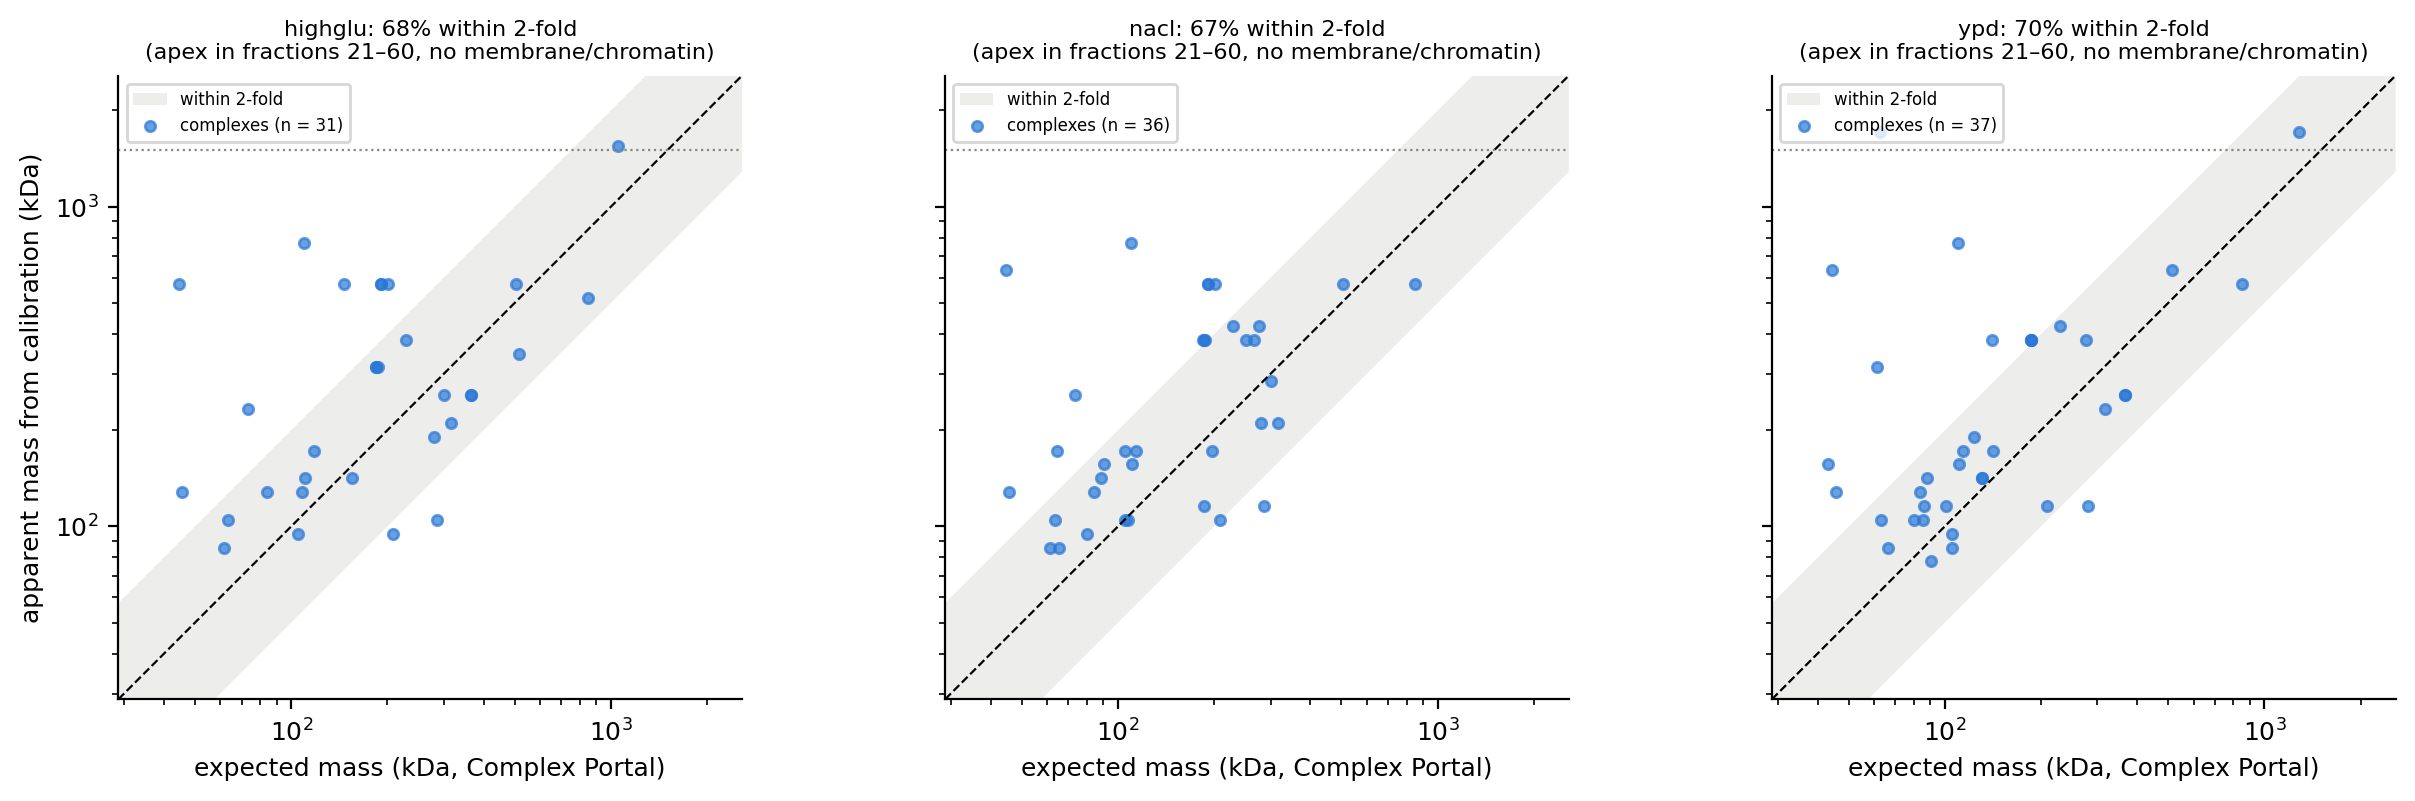

In [52]:
assert 'complex_masses_with_category' in globals(), 'run the apex-vs-mass category cell first'

EARLY_FRACTION_MARGIN = 2          # also keep this many fractions before the calibrated window starts

# fractions where the calibration curve predicts a mass inside the column's resolvable window
calibrated_fraction_range = (calibration_curves
    .filter(pl.col('mass_kda').is_between(*WINDOW_KDA))
    .group_by('condition')
    .agg(first_fraction_in_window=pl.col('fraction').min(), last_fraction_in_window=pl.col('fraction').max(),
         n_fractions_in_window=pl.len())
    .with_columns(first_fraction_used=pl.max_horizontal(pl.col('first_fraction_in_window') - EARLY_FRACTION_MARGIN, pl.lit(1)))
    .sort('condition'))
assert calibrated_fraction_range.height == len(CONDITIONS), 'calibration curve never inside the window for a condition'
assert (calibrated_fraction_range['n_fractions_in_window']
        == calibrated_fraction_range['last_fraction_in_window'] - calibrated_fraction_range['first_fraction_in_window'] + 1).all(), \
    'calibrated window is not one continuous fraction range'
print(calibrated_fraction_range)

apparent_vs_expected_mass = (complex_masses_with_category
    .join(calibration_curves.rename({'fraction': 'apex', 'mass_kda': 'apparent_mass_kda'}), on=['condition', 'apex'], how='left')
    .join(calibrated_fraction_range.select('condition', 'first_fraction_used', 'last_fraction_in_window'), on='condition', how='left')
    .with_columns(log2_apparent_over_expected=(pl.col('apparent_mass_kda') / pl.col('mass_detected_subunits_kda')).log(2))
    .with_columns(within_2_fold=pl.col('log2_apparent_over_expected').abs() <= 1,
                  in_resolvable_range=pl.col('mass_detected_subunits_kda').is_between(*WINDOW_KDA),
                  apex_in_calibrated_range=pl.col('apex').is_between(pl.col('first_fraction_used'), pl.col('last_fraction_in_window'))))
assert apparent_vs_expected_mass['apparent_mass_kda'].null_count() == 0, 'an apex has no calibration value'

# --- leave out the Complex Portal entries that are the calibration anchors themselves (they fit the line by construction) ---
COMPLEX_PORTAL_ANCHOR_DUPLICATES = {
    'CPX-607': 'Arp2/3',
    'CPX-2156': 'CCT / TRiC',
    'CPX-1652': 'COPI coatomer',
    'CPX-2944': 'MCM2-7',
    'CPX-1671': 'Prefoldin',
}
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) <= set(portal['#Complex ac']), \
    f'not in Complex Portal: {set(COMPLEX_PORTAL_ANCHOR_DUPLICATES) - set(portal["#Complex ac"])}'
assert set(COMPLEX_PORTAL_ANCHOR_DUPLICATES.values()) <= set(COMPLEX_ANCHORS), 'anchor name not in COMPLEX_ANCHORS'

is_anchor_duplicate = pl.col('complex_id').is_in(list(COMPLEX_PORTAL_ANCHOR_DUPLICATES))
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    print('left out (identical to a calibration anchor):')
    print(apparent_vs_expected_mass.filter(is_anchor_duplicate)
          .select('condition', 'complex_id', 'complex_name', 'apex', 'mass_detected_subunits_kda')
          .sort('complex_id', 'condition'))
apparent_vs_expected_mass = apparent_vs_expected_mass.filter(~is_anchor_duplicate)

# summary for all categories, for comparison
apparent_mass_summary = (apparent_vs_expected_mass
    .filter('in_resolvable_range', 'apex_in_calibrated_range')
    .group_by('condition', 'category')
    .agg(n_complexes=pl.len(),
         share_within_2_fold=pl.col('within_2_fold').mean().round(2),
         median_log2_apparent_over_expected=pl.col('log2_apparent_over_expected').median().round(2))
    .sort('condition', 'category'))
print(apparent_mass_summary)

# plot: soluble ('other') complexes, expected mass inside the window, apex in the calibrated fraction range
all_plotted_complexes = apparent_vs_expected_mass.filter(
    pl.col('in_resolvable_range') & pl.col('apex_in_calibrated_range') & (pl.col('category') == 'other'))
assert all_plotted_complexes.height > 0, 'no complexes left after the filters'
largest_plotted_mass = max(all_plotted_complexes['mass_detected_subunits_kda'].max(), all_plotted_complexes['apparent_mass_kda'].max())
smallest_plotted_mass = min(all_plotted_complexes['mass_detected_subunits_kda'].min(), all_plotted_complexes['apparent_mass_kda'].min())
AXIS_PADDING_FACTOR = 1.5          # log axes: multiplicative padding
LINEAR_PADDING_SHARE = 0.05        # linear axes: extra space above the largest point

def plot_apparent_vs_expected_mass(log_scale):
    if log_scale:
        mass_axis_range = np.array([smallest_plotted_mass / AXIS_PADDING_FACTOR, largest_plotted_mass * AXIS_PADDING_FACTOR])
    else:
        mass_axis_range = np.array([0, largest_plotted_mass * (1 + LINEAR_PADDING_SHARE)])
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
    for ax, condition in zip(axes, CONDITIONS):
        plotted_complexes = all_plotted_complexes.filter(pl.col('condition') == condition)
        fraction_range = calibrated_fraction_range.filter(pl.col('condition') == condition).row(0, named=True)
        ax.fill_between(mass_axis_range, mass_axis_range / 2, mass_axis_range * 2, color=GREY, alpha=0.15, lw=0, label='within 2-fold')
        ax.plot(mass_axis_range, mass_axis_range, 'k--', lw=0.8)
        for window_limit in WINDOW_KDA:
            if mass_axis_range[0] <= window_limit <= mass_axis_range[1]:
                ax.axhline(window_limit, color=GREY, ls=':', lw=0.8)
        ax.scatter(plotted_complexes['mass_detected_subunits_kda'], plotted_complexes['apparent_mass_kda'], s=14, c=BLUE, alpha=0.7,
                   label=f'complexes (n = {plotted_complexes.height})')
        share_within = plotted_complexes['within_2_fold'].mean() if plotted_complexes.height else float('nan')
        ax.set(xlim=mass_axis_range, ylim=mass_axis_range, xlabel='expected mass (kDa, Complex Portal)')
        if log_scale:
            ax.set(xscale='log', yscale='log')
        ax.set_aspect('equal')
        ax.set_title(f"{condition}: {share_within:.0%} within 2-fold\n"
                     f"(apex in fractions {fraction_range['first_fraction_used']}–{fraction_range['last_fraction_in_window']}, "
                     f"no membrane/chromatin)", fontsize=8)
        ax.legend(fontsize=6, loc='upper left')
    axes[0].set_ylabel('apparent mass from calibration (kDa)')
    plt.tight_layout(); plt.show()

plot_apparent_vs_expected_mass(log_scale=True)
#plot_apparent_vs_expected_mass(log_scale=False)

## 6. Stoichiometry from intensities

For each significant complex (best feature, Complex Portal, copies known), each co-eluting subunit's raw intensity is summed **between CCprofiler's peak boundaries** (`left_pp` to `right_pp`). Three versions:
* raw intensity
* intensity / protein mass
* intensity / number of tryptic peptides (iBAQ-like; only valid if the table holds summed peptide intensities)

In [53]:
#For each subunit, sums the raw intensities from the input table over fractions left_pp to right_pp
intensity_rows = []
for row in feature_subunits.filter('copies_known', pl.col('mass_kda').is_not_null()).iter_rows(named=True):
    wide = profiles_wide[row['condition']]
    peak_columns = [str(f) for f in range(row['left_pp'], row['right_pp'] + 1)]
    intensity = wide.filter(pl.col('ID') == row['protein_id']).select(peak_columns).to_numpy().sum()
    intensity_rows.append(dict(condition=row['condition'], complex_id=row['complex_id'], complex_name=row['complex_name'],
                               protein_id=row['protein_id'], copies=row['copies'], left_pp=row['left_pp'], right_pp=row['right_pp'],
                               raw=intensity, per_mass=intensity / row['mass_kda'], per_peptide=intensity / row['n_tryptic_peptides'] if row['n_tryptic_peptides'] is not None else None))
subunit_intensities = pl.DataFrame(intensity_rows, infer_schema_length=None).filter(pl.col('raw') > 0)
subunit_intensities.head()

condition,complex_id,complex_name,protein_id,copies,left_pp,right_pp,raw,per_mass,per_peptide
str,str,str,str,i64,i64,i64,f64,f64,f64
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""",1,10,20,57072.9301,1537.45422,3357.231182
"""highglu""","""CPX-1039""","""COMPASS complex""","""P38123""",1,10,20,30902.4253,889.191333,2809.311391
"""highglu""","""CPX-1039""","""COMPASS complex""","""P39706""",1,10,20,57438.684,1180.546632,2871.9342
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""",2,10,20,144843.882,2482.462816,4138.396629
"""highglu""","""CPX-1039""","""COMPASS complex""","""Q03012""",2,10,20,68692.6124,1656.52558,3271.076781


Every pair of co-eluting subunits within a complex and condition. `expected_log2` = log2(copies ratio), oriented so it is >= 0; `observed_log2_*` = log2 of the intensity ratio in the same orientation.

In [55]:
pair_rows = []
for (condition, complex_id), group in subunit_intensities.group_by('condition', 'complex_id'):
    records = group.to_dicts()
    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            first, second = sorted([records[i], records[j]], key=lambda r: -r['copies'])     # higher copy number first
            pair = dict(condition=condition, complex_id=complex_id, complex_name=first['complex_name'],
                        protein_high_copies=first['protein_id'], protein_low_copies=second['protein_id'],
                        copies=f"{first['copies']}:{second['copies']}", expected_log2=np.log2(first['copies'] / second['copies']))
            for quantity in ['raw', 'per_mass', 'per_peptide']:
                both_known = first[quantity] is not None and second[quantity] is not None
                pair[f'observed_log2_{quantity}'] = np.log2(first[quantity] / second[quantity]) if both_known else None
            pair_rows.append(pair)
all_subunit_pairs = pl.DataFrame(pair_rows, infer_schema_length=None).sort('condition', 'complex_id')

# the same protein pair can occur in several complexes within a condition (e.g. V-ATPase CPX-1192 / CPX-1193):
# keep it once, from the complex whose feature is most significant (lowest q; ties -> highest co-elution score, then complex_id)
complex_significance = best_features.select('condition', 'complex_id', 'qvalue', 'coelution_score')
assert not complex_significance.select('condition', 'complex_id').is_duplicated().any(), 'more than one best feature per complex and condition'

first_protein, second_protein = pl.col('protein_high_copies'), pl.col('protein_low_copies')
pairs_with_significance = (all_subunit_pairs
    .join(complex_significance, on=['condition', 'complex_id'], how='left')
    .with_columns(pair_key_a=pl.when(first_protein < second_protein).then(first_protein).otherwise(second_protein),   # orientation-free key:
                  pair_key_b=pl.when(first_protein < second_protein).then(second_protein).otherwise(first_protein)))  # copies can differ per complex
assert pairs_with_significance['qvalue'].null_count() == 0, 'a pair has no q-value from best_features'
assert pairs_with_significance['coelution_score'].null_count() == 0, 'a pair has no co-elution score from best_features'

duplicated_pair_groups = (pairs_with_significance
    .group_by('condition', 'pair_key_a', 'pair_key_b')
    .agg(n_complexes=pl.len(), copy_ratios=pl.col('copies').unique(), orientations=pl.col('protein_high_copies').n_unique())
    .filter(pl.col('n_complexes') > 1))
print(f'{duplicated_pair_groups.height} protein pairs occur in more than one complex within a condition; '
      f'{duplicated_pair_groups.filter(pl.col("copy_ratios").list.len() > 1).height} of them with different copy ratios, '
      f'{duplicated_pair_groups.filter(pl.col("orientations") > 1).height} with the higher-copy protein swapped')

subunit_pairs = (pairs_with_significance
    .sort(['qvalue', 'coelution_score', 'complex_id'], descending=[False, True, False])
    .unique(['condition', 'pair_key_a', 'pair_key_b'], keep='first', maintain_order=True)
    .drop('pair_key_a', 'pair_key_b')
    .sort('condition', 'complex_id'))
assert subunit_pairs.height == all_subunit_pairs.height - (duplicated_pair_groups['n_complexes'] - 1).sum()
print(f'{all_subunit_pairs.height - subunit_pairs.height} duplicate pairs removed; {subunit_pairs.height} pairs left '
      f'({(subunit_pairs["expected_log2"] > 0).sum()} unequal, {(subunit_pairs["expected_log2"] == 0).sum()} equal)')
subunit_pairs.head()

510 protein pairs occur in more than one complex within a condition; 41 of them with different copy ratios, 8 with the higher-copy protein swapped
615 duplicate pairs removed; 6008 pairs left (386 unequal, 5622 equal)


condition,complex_id,complex_name,protein_high_copies,protein_low_copies,copies,expected_log2,observed_log2_raw,observed_log2_per_mass,observed_log2_per_peptide,qvalue,coelution_score
str,str,str,str,str,str,f64,f64,f64,f64,f64,f64
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""","""P39706""","""1:1""",0.0,-0.009216,0.381088,0.225249,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""P36104""","""2:1""",1.0,1.34362,0.691229,0.3018,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""Q03323""","""2:1""",1.0,1.59316,0.007984,-0.536123,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""Q03012""","""2:2""",0.0,1.076272,0.583612,0.339306,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P39706""","""Q03323""","""1:1""",0.0,0.258756,-1.064333,-1.063172,0.015116,0.999991


Which complexes contribute the unequal pairs? (A complex with many subunits contributes many pairs, and they are not independent.)

In [56]:
(subunit_pairs.filter(pl.col('expected_log2') > 0)
   .group_by('complex_id', 'complex_name')
   .agg(unequal_pairs=pl.len(), conditions=pl.col('condition').unique().sort(), copy_ratios=pl.col('copies').unique().sort(),
        share_higher_copy_more_signal=(pl.col('observed_log2_per_peptide') > 0).mean().round(2))
   .sort('unequal_pairs', descending=True))

complex_id,complex_name,unequal_pairs,conditions,copy_ratios,share_higher_copy_more_signal
str,str,u32,list[str],list[str],f64
"""CPX-1642""","""General transcription factor c…",103,"[""highglu"", ""nacl""]","[""2:1"", ""3:1"", ""3:2""]",1.0
"""CPX-1193""","""Vacuolar proton translocating …",72,"[""highglu"", ""nacl"", ""ypd""]","[""3:1""]",0.85
"""CPX-3281""","""Mitochondrial proton-transport…",42,"[""highglu"", ""nacl""]","[""3:1""]",1.0
"""CPX-863""","""INO80 chromatin remodeling com…",32,"[""highglu"", ""nacl""]","[""6:1""]",0.94
"""CPX-1039""","""COMPASS complex""",20,"[""highglu"", ""nacl""]","[""2:1""]",0.7
"""CPX-1192""","""Vacuolar proton translocating …",16,"[""highglu"", ""nacl"", ""ypd""]","[""3:1""]",1.0
…,…,…,…,…,…
"""CPX-1383""","""TRAPPIII protein complex""",2,"[""highglu"", ""nacl""]","[""2:1""]",1.0
"""CPX-1895""","""mRNA cleavage factor complex C…",2,"[""nacl""]","[""2:1""]",0.5


In [60]:
stoichiometry_rows = []
for quantity in ['raw', 'per_mass', 'per_peptide']:
    observed = f'observed_log2_{quantity}'
    unequal = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls(observed)
    equal = subunit_pairs.filter(pl.col('expected_log2') == 0).drop_nulls(observed)
    stoichiometry_rows.append(dict(
        quantity=quantity,
        unequal_pairs=unequal.height, unequal_complexes=unequal['complex_id'].n_unique(),
        share_higher_copy_more_signal=round(float((unequal[observed] > 0).mean()), 2),
        median_observed_minus_expected_log2=round(float((unequal[observed] - unequal['expected_log2']).median()), 2),
        equal_pairs=equal.height,
        equal_pairs_median_fold=round(float(2 ** equal[observed].abs().median()), 2)))
stoichiometry_summary = pl.DataFrame(stoichiometry_rows)

print(stoichiometry_summary)

# --- cap: every protein in at most MAX_UNEQUAL_PAIRS_PER_PROTEIN unequal pairs, over all complexes and conditions, both sides of a pair ---
# --- cap: every protein in at most MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN equal pairs AND at most that many unequal pairs
#     (two separate counters), over all complexes and conditions, both sides of a pair ---
MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN = 10
N_CAP_DRAWS = 100                     # which pairs a protein keeps is random; repeat and report the spread
STOICHIOMETRY_QUANTITIES = ['raw', 'per_mass', 'per_peptide']

pairs_with_all_quantities = subunit_pairs.drop_nulls([f'observed_log2_{quantity}' for quantity in STOICHIOMETRY_QUANTITIES])
equal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') == 0)
unequal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') > 0)
print(f'{equal_pairs_all_quantities.height} equal and {unequal_pairs_all_quantities.height} unequal pairs '
      f'with all three quantities go into the cap')

def cap_stoichiometry_pairs_per_protein(pairs, max_pairs_per_protein, seed):
    '''Go through the pairs in random order; keep a pair only if neither of its proteins has reached the cap.'''
    shuffled_pairs = pairs.sample(fraction=1.0, shuffle=True, seed=seed)
    kept_pairs_per_protein, keep_pair = {}, []
    for protein_high, protein_low in shuffled_pairs.select('protein_high_copies', 'protein_low_copies').iter_rows():
        keep = (kept_pairs_per_protein.get(protein_high, 0) < max_pairs_per_protein
                and kept_pairs_per_protein.get(protein_low, 0) < max_pairs_per_protein)
        if keep:
            kept_pairs_per_protein[protein_high] = kept_pairs_per_protein.get(protein_high, 0) + 1
            kept_pairs_per_protein[protein_low] = kept_pairs_per_protein.get(protein_low, 0) + 1
        keep_pair.append(keep)
    capped_pairs = shuffled_pairs.filter(pl.Series(keep_pair))
    assert capped_pairs.height > 0, 'cap removed every pair'
    assert max(kept_pairs_per_protein.values()) <= max_pairs_per_protein
    return capped_pairs

def stoichiometry_pair_metrics(equal_pair_set, unequal_pair_set):
    unequal_pair_proteins = pl.concat([unequal_pair_set['protein_high_copies'], unequal_pair_set['protein_low_copies']])
    equal_pair_proteins = pl.concat([equal_pair_set['protein_high_copies'], equal_pair_set['protein_low_copies']])
    metrics = dict(n_unequal_pairs=unequal_pair_set.height, n_unequal_complexes=unequal_pair_set['complex_id'].n_unique(),
                   n_unequal_proteins=unequal_pair_proteins.n_unique(),
                   n_equal_pairs=equal_pair_set.height, n_equal_proteins=equal_pair_proteins.n_unique())
    for quantity in STOICHIOMETRY_QUANTITIES:
        unequal_observed_log2 = unequal_pair_set[f'observed_log2_{quantity}']
        equal_observed_log2 = equal_pair_set[f'observed_log2_{quantity}']
        metrics[f'{quantity}_share_higher_copy_more_signal'] = float((unequal_observed_log2 > 0).mean())
        metrics[f'{quantity}_median_observed_minus_expected_log2'] = float((unequal_observed_log2 - unequal_pair_set['expected_log2']).median())
        metrics[f'{quantity}_equal_pairs_median_fold'] = float(2 ** equal_observed_log2.abs().median())
    return metrics

capped_pair_metrics = pl.DataFrame([
    stoichiometry_pair_metrics(
        cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed),
        cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed))
    for seed in range(N_CAP_DRAWS)])
uncapped_pair_metrics = stoichiometry_pair_metrics(equal_pairs_all_quantities, unequal_pairs_all_quantities)

capped_pair_summary = (capped_pair_metrics.select(pl.all().cast(pl.Float64))
    .unpivot(variable_name='metric')
    .group_by('metric', maintain_order=True)
    .agg(capped_median=pl.col('value').median(),
         capped_low=pl.col('value').quantile(0.025), capped_high=pl.col('value').quantile(0.975))
    .with_columns(uncapped=pl.col('metric').replace_strict({name: float(value) for name, value in uncapped_pair_metrics.items()},
                                                           return_dtype=pl.Float64))
    .with_columns(pl.col(pl.Float64).round(2)))
with pl.Config(tbl_rows=-1):
    print(capped_pair_summary)

shape: (3, 7)
┌─────────────┬──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ quantity    ┆ unequal_pair ┆ unequal_com ┆ share_highe ┆ median_obse ┆ equal_pairs ┆ equal_pairs │
│ ---         ┆ s            ┆ plexes      ┆ r_copy_more ┆ rved_minus_ ┆ ---         ┆ _median_fol │
│ str         ┆ ---          ┆ ---         ┆ _signal     ┆ expected…   ┆ i64         ┆ d           │
│             ┆ i64          ┆ i64         ┆ ---         ┆ ---         ┆             ┆ ---         │
│             ┆              ┆             ┆ f64         ┆ f64         ┆             ┆ f64         │
╞═════════════╪══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ raw         ┆ 386          ┆ 27          ┆ 0.78        ┆ 0.36        ┆ 5622        ┆ 2.28        │
│ per_mass    ┆ 386          ┆ 27          ┆ 0.93        ┆ 0.44        ┆ 5622        ┆ 1.85        │
│ per_peptide ┆ 386          ┆ 27          ┆ 0.92        ┆ 0.34        ┆ 5622

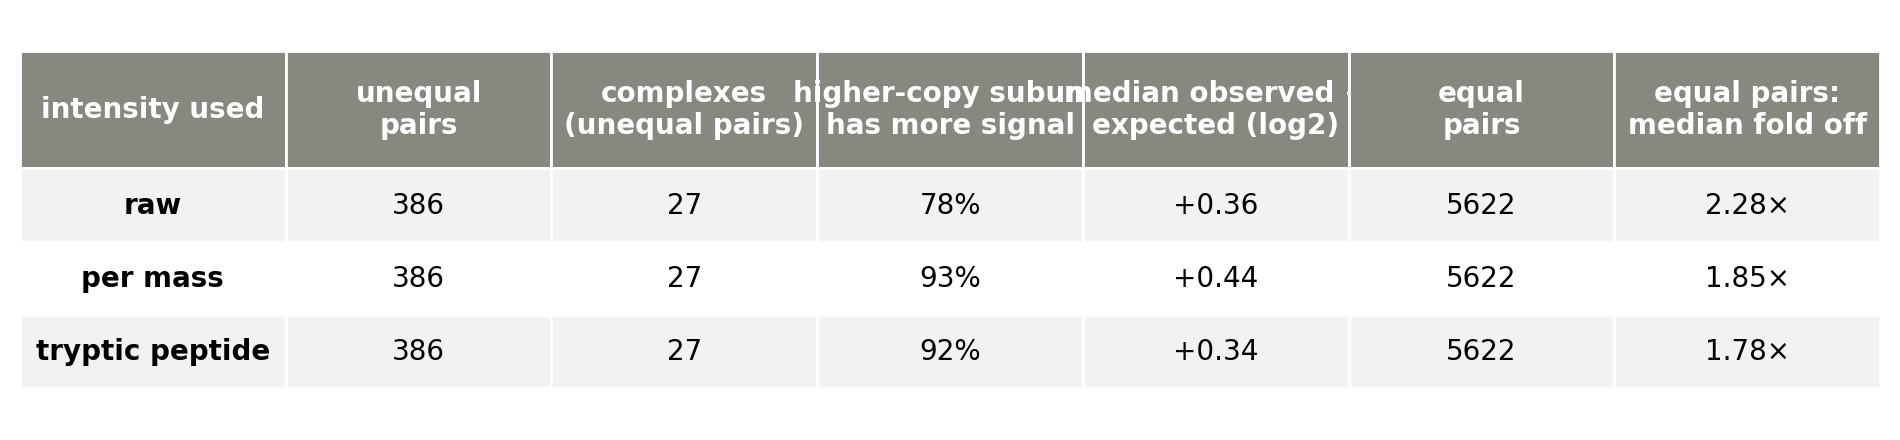

In [67]:
#uncapped
STOICHIOMETRY_TABLE_COLUMNS = {
    'quantity': 'intensity used',
    'unequal_pairs': 'unequal\npairs',
    'unequal_complexes': 'complexes\n(unequal pairs)',
    'share_higher_copy_more_signal': 'higher-copy subunit\nhas more signal',
    'median_observed_minus_expected_log2': 'median observed −\nexpected (log2)',
    'equal_pairs': 'equal\npairs',
    'equal_pairs_median_fold': 'equal pairs:\nmedian fold off',
}
QUANTITY_LABELS = {'raw': 'raw', 'per_mass': 'per mass', 'per_peptide': 'tryptic peptide'}
missing_summary_columns = set(STOICHIOMETRY_TABLE_COLUMNS) - set(stoichiometry_summary.columns)
assert not missing_summary_columns, f'rerun the stoichiometry_summary cell; missing columns: {missing_summary_columns}'
assert set(stoichiometry_summary['quantity']) <= set(QUANTITY_LABELS), 'unknown quantity in stoichiometry_summary'

def format_stoichiometry_value(column, value):
    if column == 'quantity':
        return QUANTITY_LABELS[value]
    if column == 'share_higher_copy_more_signal':
        return f'{value:.0%}'
    if column == 'median_observed_minus_expected_log2':
        return f'{value:+.2f}'
    if column.endswith('median_fold'):
        return f'{value:.2f}×'
    return str(value)

stoichiometry_table_rows = [[format_stoichiometry_value(column, value) for column, value in row.items()]
                            for row in stoichiometry_summary.select(list(STOICHIOMETRY_TABLE_COLUMNS)).iter_rows(named=True)]

fig, ax = plt.subplots(figsize=(12, 0.8 + 0.45 * (len(stoichiometry_table_rows) + 1)))
ax.axis('off')
stoichiometry_table = ax.table(cellText=stoichiometry_table_rows, colLabels=list(STOICHIOMETRY_TABLE_COLUMNS.values()),
                               cellLoc='center', loc='center')
stoichiometry_table.auto_set_font_size(False)
stoichiometry_table.set_fontsize(10)
stoichiometry_table.scale(1, 2.2)
for (row_index, column_index), cell in stoichiometry_table.get_celld().items():
    cell.set_edgecolor('white')
    if row_index == 0:
        cell.set_facecolor(GREY)
        cell.set_text_props(color='white', fontweight='bold')
        cell.set_height(cell.get_height() * 1.6)
    else:
        cell.set_facecolor('#f2f2f2' if row_index % 2 else 'white')
        if column_index == 0:
            cell.set_text_props(fontweight='bold')
plt.show()

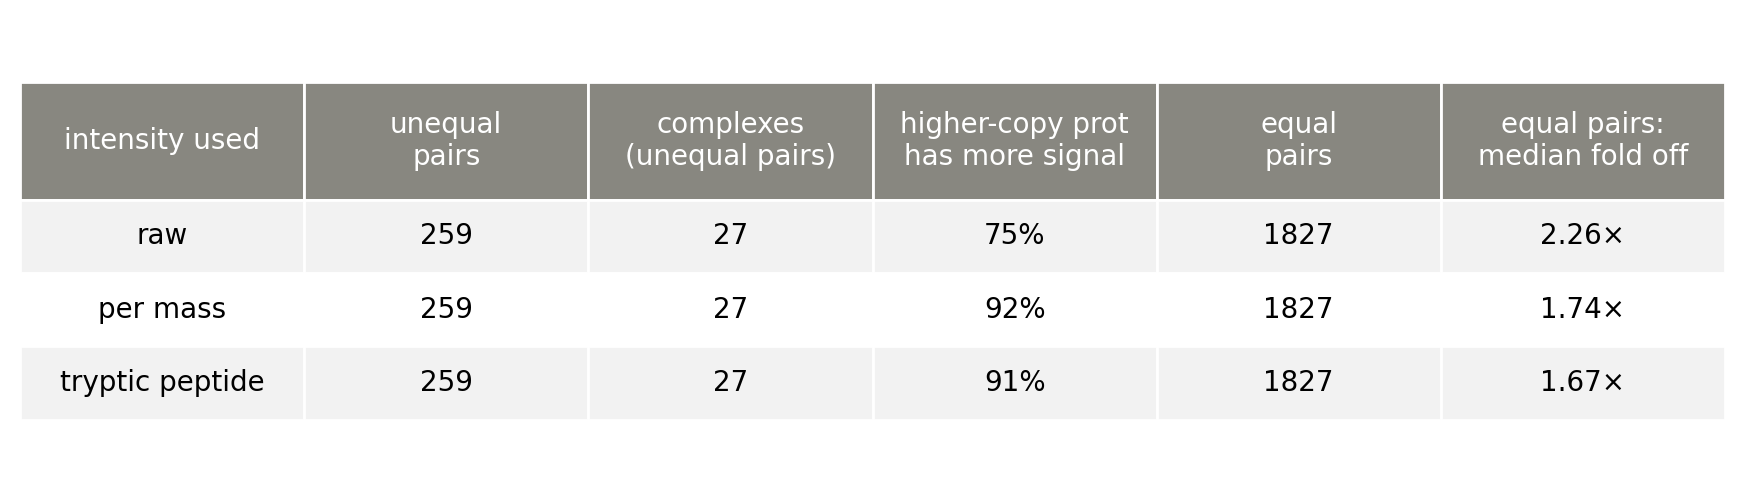

In [71]:
assert 'capped_pair_summary' in globals(), 'run the stoichiometry summary / cap cell first'
capped_medians = dict(capped_pair_summary.select('metric', 'capped_median').iter_rows())

CAPPED_TABLE_COLUMNS = ['intensity used', 'unequal\npairs', 'complexes\n(unequal pairs)', 'higher-copy prot\nhas more signal',
                        'equal\npairs', 'equal pairs:\nmedian fold off']

def capped_median(metric):
    assert metric in capped_medians, f'{metric} missing from capped_pair_summary'
    return capped_medians[metric]

capped_table_rows = [[QUANTITY_LABELS[quantity],
                      f"{capped_median('n_unequal_pairs'):.0f}",
                      f"{capped_median('n_unequal_complexes'):.0f}",
                      f"{capped_median(f'{quantity}_share_higher_copy_more_signal'):.0%}",
                      f"{capped_median('n_equal_pairs'):.0f}",
                      f"{capped_median(f'{quantity}_equal_pairs_median_fold'):.2f}×"]
                     for quantity in STOICHIOMETRY_QUANTITIES]

fig, ax = plt.subplots(figsize=(11, 0.8 + 0.55 * (len(capped_table_rows) + 1)))
ax.axis('off')
capped_stoichiometry_table = ax.table(cellText=capped_table_rows, colLabels=CAPPED_TABLE_COLUMNS, cellLoc='center', loc='center')
capped_stoichiometry_table.auto_set_font_size(False)
capped_stoichiometry_table.set_fontsize(10)
capped_stoichiometry_table.scale(1, 2.2)
for (row_index, column_index), cell in capped_stoichiometry_table.get_celld().items():
    cell.set_edgecolor('white')
    if row_index == 0:
        cell.set_facecolor(GREY)
        cell.set_text_props(color='white')
        cell.set_height(cell.get_height() * 1.6)
    else:
        cell.set_facecolor('#f2f2f2' if row_index % 2 else 'white')
        if column_index == 0:
            cell.set_text_props()
plt.show()

In [44]:
# split based on condition
unequal_pairs_in_table = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls('observed_log2_per_peptide')
assert unequal_pairs_in_table.height == stoichiometry_summary.filter(pl.col('quantity') == 'per_peptide')['unequal_pairs'][0], \
    'pair count differs from the summary table'

unequal_pairs_per_condition = (unequal_pairs_in_table
    .group_by('condition')
    .agg(unequal_pairs=pl.len(), complexes=pl.col('complex_id').n_unique(),
         share_higher_copy_more_signal=(pl.col('observed_log2_per_peptide') > 0).mean().round(2))
    .sort('condition'))
print(unequal_pairs_per_condition)

unequal_protein_pair_conditions = (unequal_pairs_in_table
    .group_by('protein_high_copies', 'protein_low_copies')
    .agg(n_conditions=pl.col('condition').n_unique(), conditions=pl.col('condition').sort()))
print(f'{unequal_pairs_in_table.height} pair x condition rows = {unequal_protein_pair_conditions.height} distinct protein pairs')
print(unequal_protein_pair_conditions.group_by('n_conditions').agg(distinct_protein_pairs=pl.len()).sort('n_conditions'))

shape: (3, 4)
┌───────────┬───────────────┬───────────┬───────────────────────────────┐
│ condition ┆ unequal_pairs ┆ complexes ┆ share_higher_copy_more_signal │
│ ---       ┆ ---           ┆ ---       ┆ ---                           │
│ str       ┆ u32           ┆ u32       ┆ f64                           │
╞═══════════╪═══════════════╪═══════════╪═══════════════════════════════╡
│ highglu   ┆ 176           ┆ 23        ┆ 0.94                          │
│ nacl      ┆ 178           ┆ 24        ┆ 0.92                          │
│ ypd       ┆ 32            ┆ 9         ┆ 0.81                          │
└───────────┴───────────────┴───────────┴───────────────────────────────┘
386 pair x condition rows = 199 distinct protein pairs
shape: (3, 2)
┌──────────────┬────────────────────────┐
│ n_conditions ┆ distinct_protein_pairs │
│ ---          ┆ ---                    │
│ u32          ┆ u32                    │
╞══════════════╪════════════════════════╡
│ 1            ┆ 41                     │

In [73]:
# capped
for variable_name in ['cap_stoichiometry_pairs_per_protein', 'unequal_pairs_all_quantities',
                      'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN', 'N_CAP_DRAWS']:
    assert variable_name in globals(), f'run the stoichiometry summary / cap cell first ({variable_name} missing)'

capped_condition_rows, capped_repeat_rows = [], []
for seed in range(N_CAP_DRAWS):
    capped_unequal_pairs = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)
    for condition in CONDITIONS:
        condition_pairs = capped_unequal_pairs.filter(pl.col('condition') == condition)
        assert condition_pairs.height > 0, f'draw {seed}: no unequal pairs left in {condition}'
        capped_condition_rows.append(dict(seed=seed, condition=condition, unequal_pairs=condition_pairs.height,
                                          complexes=condition_pairs['complex_id'].n_unique(),
                                          share_higher_copy_more_signal=float((condition_pairs['observed_log2_per_peptide'] > 0).mean())))
    conditions_per_protein_pair = (capped_unequal_pairs.group_by('protein_high_copies', 'protein_low_copies')
                                   .agg(n_conditions=pl.col('condition').n_unique())['n_conditions'])
    capped_repeat_rows += [dict(seed=seed, n_conditions=n_conditions,
                                distinct_protein_pairs=int((conditions_per_protein_pair == n_conditions).sum()))
                           for n_conditions in range(1, len(CONDITIONS) + 1)]

capped_unequal_pairs_per_condition = (pl.DataFrame(capped_condition_rows)
    .group_by('condition')
    .agg(pl.col('unequal_pairs', 'complexes', 'share_higher_copy_more_signal').median())
    .with_columns(pl.col('share_higher_copy_more_signal').round(2))
    .sort('condition'))
capped_conditions_per_protein_pair = (pl.DataFrame(capped_repeat_rows)
    .group_by('n_conditions')
    .agg(distinct_protein_pairs=pl.col('distinct_protein_pairs').median())
    .sort('n_conditions'))

print(f'capped (≤ {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN} unequal pairs per protein), median of {N_CAP_DRAWS} draws:')
print(capped_unequal_pairs_per_condition)
print(capped_conditions_per_protein_pair)

capped (≤ 10 unequal pairs per protein), median of 100 draws:
shape: (3, 4)
┌───────────┬───────────────┬───────────┬───────────────────────────────┐
│ condition ┆ unequal_pairs ┆ complexes ┆ share_higher_copy_more_signal │
│ ---       ┆ ---           ┆ ---       ┆ ---                           │
│ str       ┆ f64           ┆ f64       ┆ f64                           │
╞═══════════╪═══════════════╪═══════════╪═══════════════════════════════╡
│ highglu   ┆ 117.0         ┆ 23.0      ┆ 0.92                          │
│ nacl      ┆ 118.0         ┆ 24.0      ┆ 0.91                          │
│ ypd       ┆ 24.0          ┆ 9.0       ┆ 0.84                          │
└───────────┴───────────────┴───────────┴───────────────────────────────┘
shape: (3, 2)
┌──────────────┬────────────────────────┐
│ n_conditions ┆ distinct_protein_pairs │
│ ---          ┆ ---                    │
│ i64          ┆ f64                    │
╞══════════════╪════════════════════════╡
│ 1            ┆ 93.0             

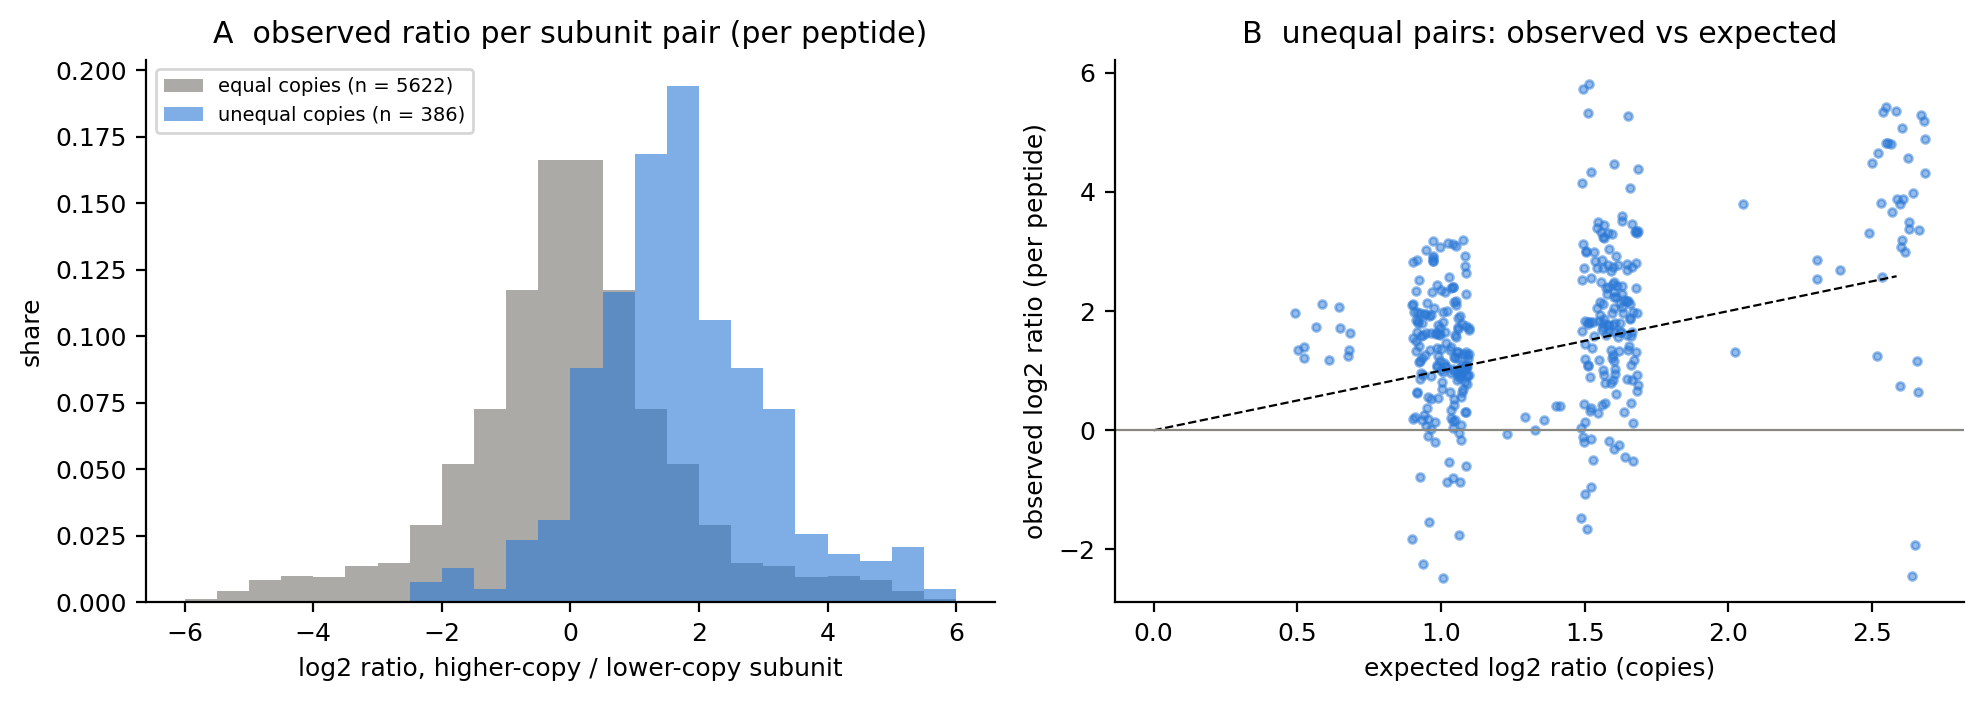

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
equal = subunit_pairs.filter(pl.col('expected_log2') == 0).drop_nulls('observed_log2_per_peptide')['observed_log2_per_peptide'].to_numpy()
unequal = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls('observed_log2_per_peptide')
bins = np.arange(-6, 6.1, 0.5)
axes[0].hist(np.r_[equal, -equal], bins, weights=np.full(2 * len(equal), 1 / (2 * len(equal))), color=GREY, alpha=0.7, label=f'equal copies (n = {len(equal)})')
axes[0].hist(unequal['observed_log2_per_peptide'], bins, weights=np.full(unequal.height, 1 / unequal.height), color=BLUE, alpha=0.6, label=f'unequal copies (n = {unequal.height})')
axes[0].set(title='A  observed ratio per subunit pair (per peptide)', xlabel='log2 ratio, higher-copy / lower-copy subunit', ylabel='share')
axes[0].legend(fontsize=7)
axes[1].scatter(unequal['expected_log2'] + np.random.default_rng(0).uniform(-0.1, 0.1, unequal.height), unequal['observed_log2_per_peptide'], s=8, alpha=0.5, c=BLUE)
line = np.array([0, unequal['expected_log2'].max()])
axes[1].plot(line, line, 'k--', lw=0.8)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].set(title='B  unequal pairs: observed vs expected', xlabel='expected log2 ratio (copies)', ylabel='observed log2 ratio (per peptide)')
plt.tight_layout(); plt.show()

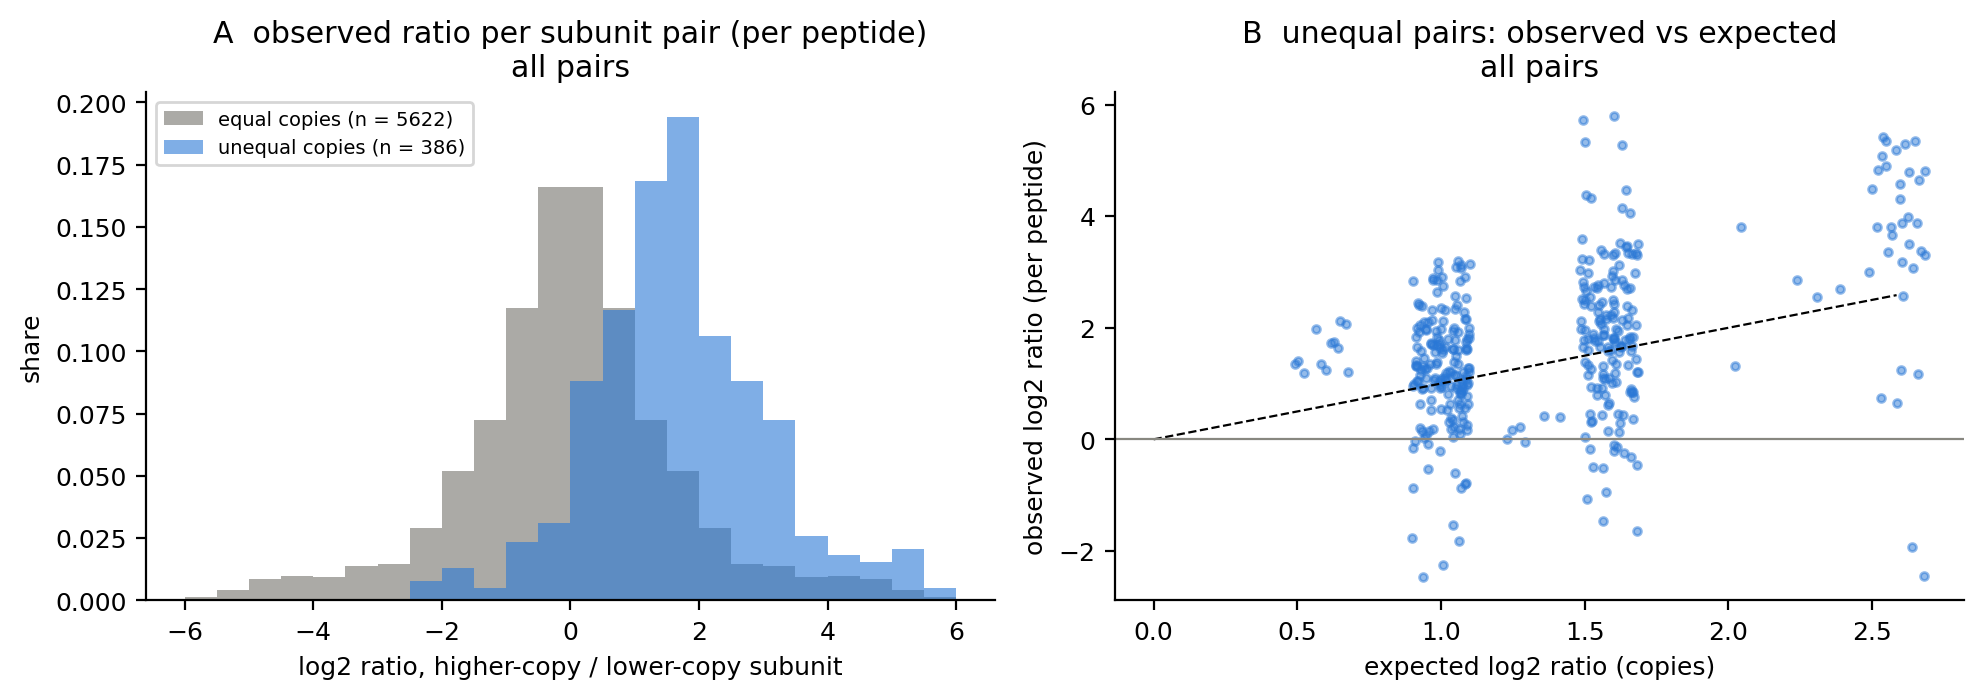

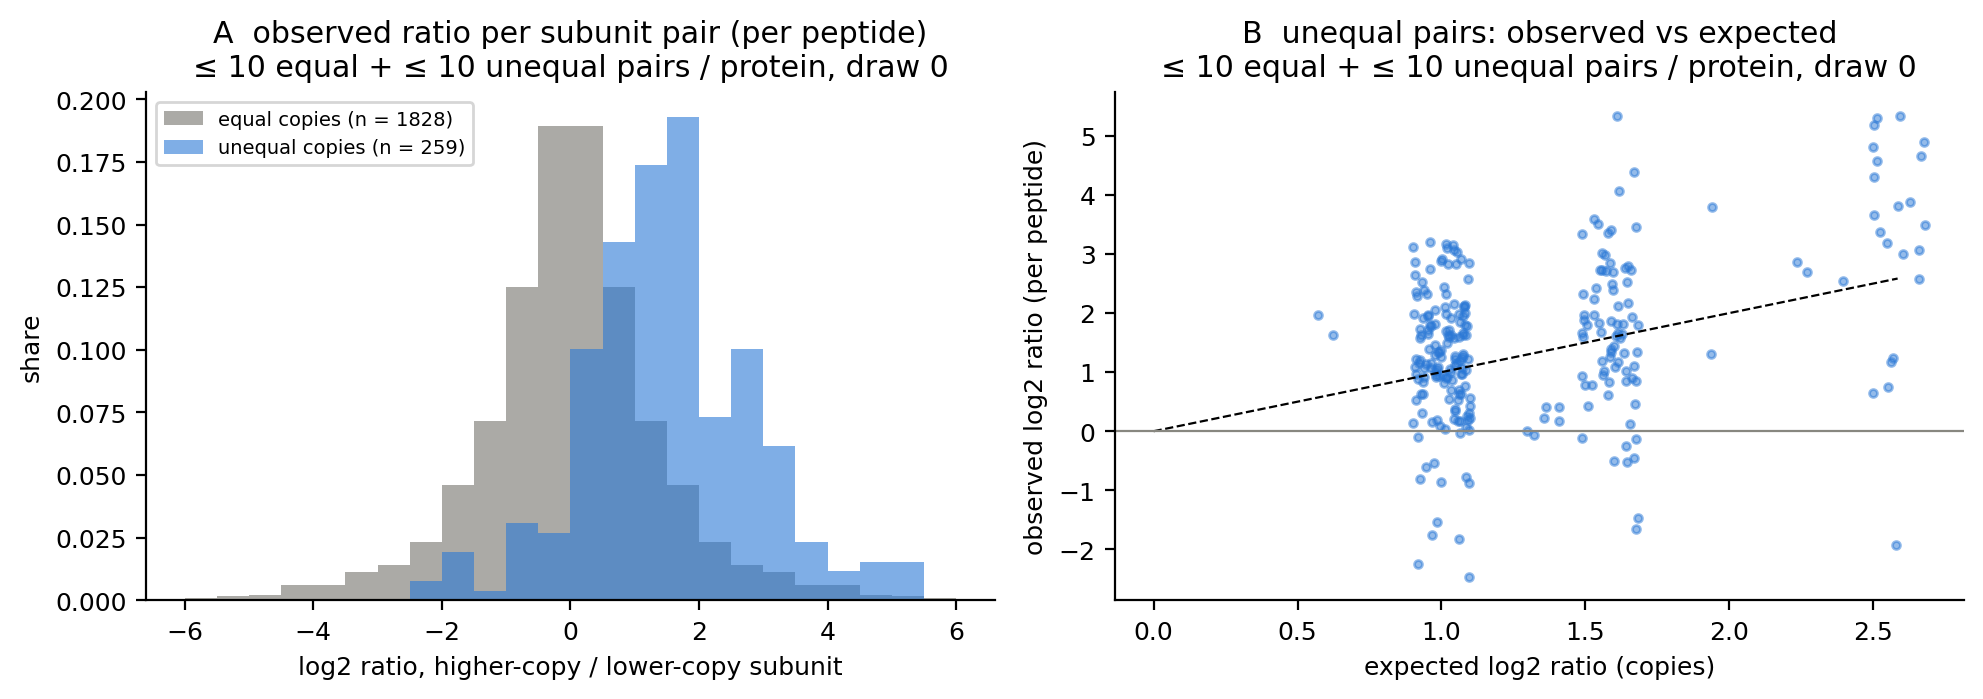

In [76]:
for variable_name in ['cap_stoichiometry_pairs_per_protein', 'equal_pairs_all_quantities', 'unequal_pairs_all_quantities',
                      'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN']:
    assert variable_name in globals(), f'run the stoichiometry summary / cap cell first ({variable_name} missing)'

OBSERVED_COLUMN = 'observed_log2_per_peptide'
PLOTTED_CAP_SEED = 0                # one draw is shown; the summary tables use the median over all draws

def plot_pair_ratios(equal_pair_set, unequal_pair_set, title_suffix):
    equal_ratios = equal_pair_set[OBSERVED_COLUMN].to_numpy()
    assert len(equal_ratios) > 0 and unequal_pair_set.height > 0, 'no equal or no unequal pairs to plot'
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    bins = np.arange(-6, 6.1, 0.5)
    axes[0].hist(np.r_[equal_ratios, -equal_ratios], bins, weights=np.full(2 * len(equal_ratios), 1 / (2 * len(equal_ratios))),
                 color=GREY, alpha=0.7, label=f'equal copies (n = {len(equal_ratios)})')
    axes[0].hist(unequal_pair_set[OBSERVED_COLUMN], bins, weights=np.full(unequal_pair_set.height, 1 / unequal_pair_set.height),
                 color=BLUE, alpha=0.6, label=f'unequal copies (n = {unequal_pair_set.height})')
    axes[0].set(title=f'A  observed ratio per subunit pair (per peptide)\n{title_suffix}',
                xlabel='log2 ratio, higher-copy / lower-copy subunit', ylabel='share')
    axes[0].legend(fontsize=7)
    axes[1].scatter(unequal_pair_set['expected_log2'] + np.random.default_rng(0).uniform(-0.1, 0.1, unequal_pair_set.height),
                    unequal_pair_set[OBSERVED_COLUMN], s=8, alpha=0.5, c=BLUE)
    identity_line = np.array([0, unequal_pair_set['expected_log2'].max()])
    axes[1].plot(identity_line, identity_line, 'k--', lw=0.8)
    axes[1].axhline(0, color=GREY, lw=0.8)
    axes[1].set(title=f'B  unequal pairs: observed vs expected\n{title_suffix}',
                xlabel='expected log2 ratio (copies)', ylabel='observed log2 ratio (per peptide)')
    plt.tight_layout(); plt.show()

# uncapped: all pairs with a per-peptide value
uncapped_equal_pairs = subunit_pairs.filter(pl.col('expected_log2') == 0).drop_nulls(OBSERVED_COLUMN)
uncapped_unequal_pairs = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls(OBSERVED_COLUMN)
plot_pair_ratios(uncapped_equal_pairs, uncapped_unequal_pairs, 'all pairs')

# capped: one draw, same cap as the summary table
capped_equal_pairs = cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
capped_unequal_pairs = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
plot_pair_ratios(capped_equal_pairs, capped_unequal_pairs,
                 f'≤ {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN} equal + ≤ {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN} unequal pairs / protein, draw {PLOTTED_CAP_SEED}')

shape: (2, 6)
┌───────────────────────┬─────────┬─────────────┬─────────────┬────────┬─────────┐
│ true_ratio            ┆ n_pairs ┆ n_complexes ┆ called_2to1 ┆ ci_low ┆ ci_high │
│ ---                   ┆ ---     ┆ ---         ┆ ---         ┆ ---    ┆ ---     │
│ str                   ┆ i64     ┆ i64         ┆ f64         ┆ f64    ┆ f64     │
╞═══════════════════════╪═════════╪═════════════╪═════════════╪════════╪═════════╡
│ 2:1                   ┆ 174     ┆ 18          ┆ 0.81        ┆ 0.55   ┆ 0.94    │
│ equal (1:1, 2:2, ...) ┆ 5622    ┆ 138         ┆ 0.34        ┆ 0.31   ┆ 0.35    │
└───────────────────────┴─────────┴─────────────┴─────────────┴────────┴─────────┘


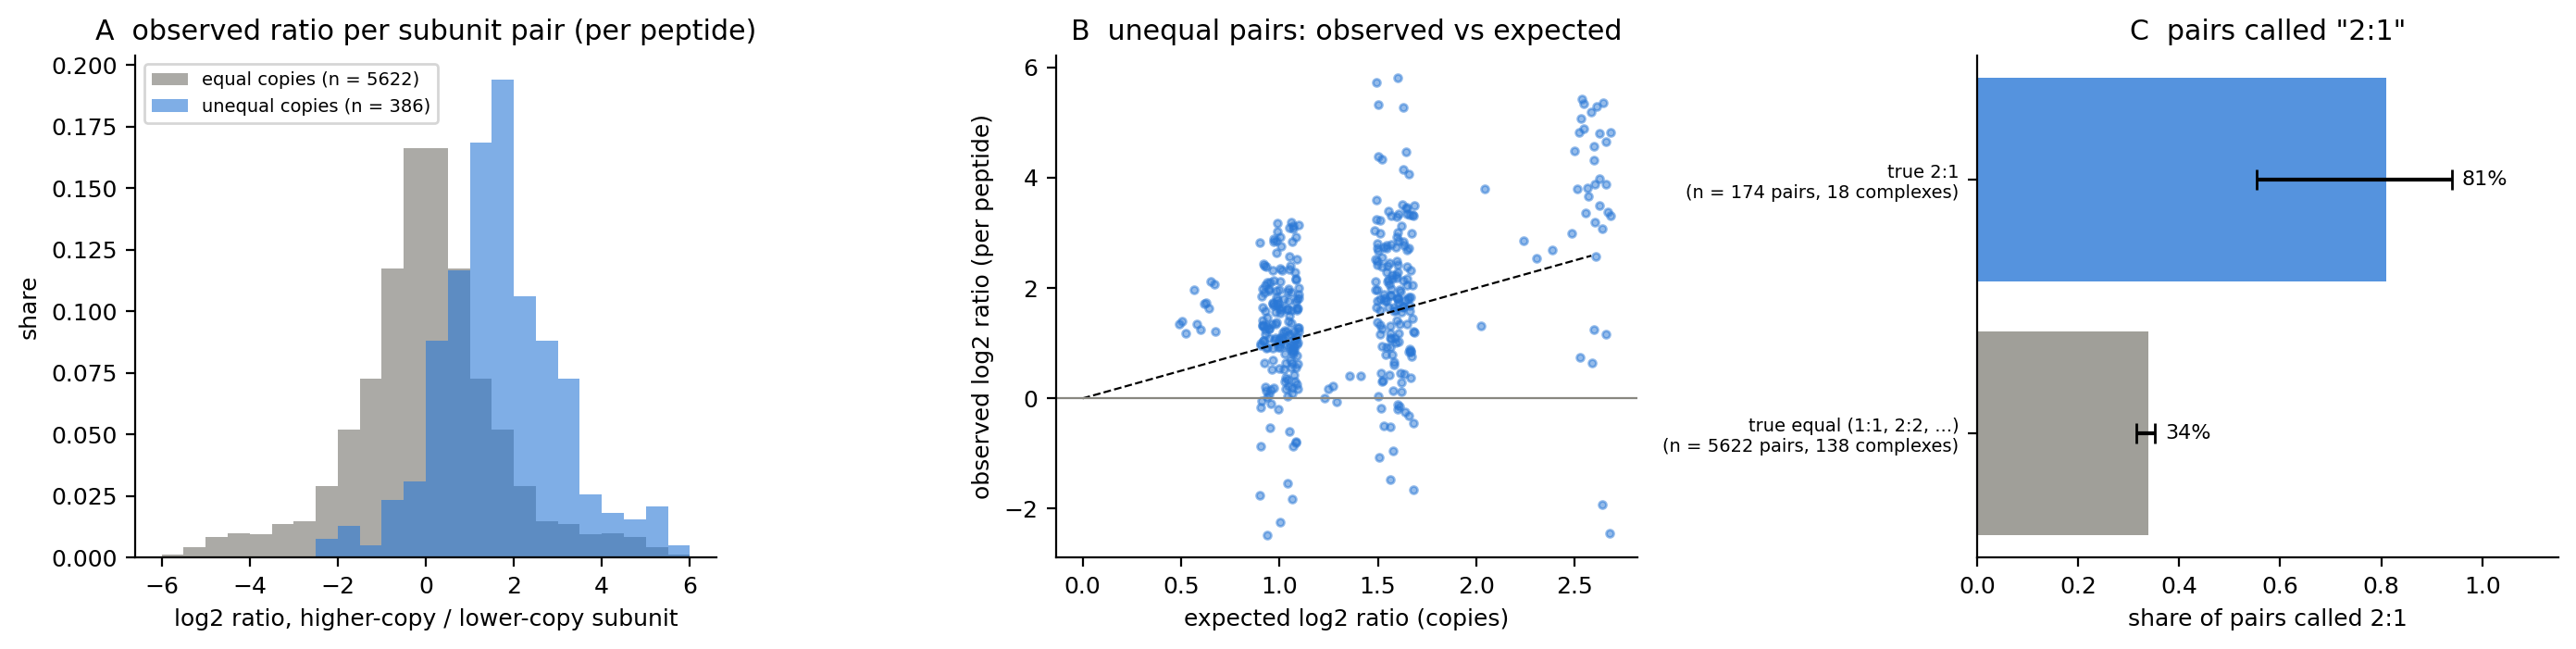

In [77]:
from scipy.stats import gaussian_kde

observed_column = 'observed_log2_per_peptide'
pairs_with_observed = subunit_pairs.drop_nulls(observed_column)

equal_pairs = pairs_with_observed.filter(pl.col('expected_log2') == 0)
two_to_one_pairs = pairs_with_observed.filter((pl.col('expected_log2') - 1).abs() < 1e-9)
assert equal_pairs.height > 0 and two_to_one_pairs.height > 0

EQUAL_LABEL = 'equal (1:1, 2:2, ...)'
tested_pairs = pl.concat([
    equal_pairs.with_columns(true_ratio=pl.lit(EQUAL_LABEL)),
    two_to_one_pairs.with_columns(true_ratio=pl.lit('2:1')),
])

# noise model per complex: equal pairs from all OTHER complexes, mirrored (orientation of an equal pair is arbitrary)
called_frames = []
for (complex_id,), complex_pairs in tested_pairs.group_by('complex_id'):
    noise_values = equal_pairs.filter(pl.col('complex_id') != complex_id)[observed_column].to_numpy()
    assert len(noise_values) >= 20, f'too few equal pairs outside {complex_id} to estimate noise'
    noise_density = gaussian_kde(np.r_[noise_values, -noise_values])
    observed_values = complex_pairs[observed_column].to_numpy()
    called_as_given = noise_density(observed_values - 1) > noise_density(observed_values)
    called_flipped = noise_density(-observed_values - 1) > noise_density(-observed_values)
    is_equal_pair = (complex_pairs['true_ratio'] == EQUAL_LABEL).to_numpy()
    called_score = np.where(is_equal_pair, (called_as_given.astype(float) + called_flipped) / 2, called_as_given)
    called_frames.append(complex_pairs.with_columns(called_2to1=pl.Series(called_score)))
called_pairs = pl.concat(called_frames)

# 95% interval: resample complexes, since pairs within a complex are not independent
per_complex_counts = called_pairs.group_by('true_ratio', 'complex_id').agg(
    n_pairs=pl.len(), n_called=pl.col('called_2to1').sum())
bootstrap_rng = np.random.default_rng(0)
call_rate_rows = []
for true_ratio in ['2:1', EQUAL_LABEL]:
    class_counts = per_complex_counts.filter(pl.col('true_ratio') == true_ratio)
    n_pairs_per_complex = class_counts['n_pairs'].to_numpy()
    n_called_per_complex = class_counts['n_called'].to_numpy()
    resampled = bootstrap_rng.integers(0, class_counts.height, (2000, class_counts.height))
    resampled_rates = n_called_per_complex[resampled].sum(1) / n_pairs_per_complex[resampled].sum(1)
    call_rate_rows.append(dict(
        true_ratio=true_ratio, n_pairs=int(n_pairs_per_complex.sum()), n_complexes=class_counts.height,
        called_2to1=n_called_per_complex.sum() / n_pairs_per_complex.sum(),
        ci_low=np.percentile(resampled_rates, 2.5), ci_high=np.percentile(resampled_rates, 97.5)))
call_rates = pl.DataFrame(call_rate_rows)
print(call_rates.with_columns(pl.col(pl.Float64).round(2)))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
equal = equal_pairs[observed_column].to_numpy()
unequal = pairs_with_observed.filter(pl.col('expected_log2') > 0)
bins = np.arange(-6, 6.1, 0.5)
axes[0].hist(np.r_[equal, -equal], bins, weights=np.full(2 * len(equal), 1 / (2 * len(equal))), color=GREY, alpha=0.7, label=f'equal copies (n = {len(equal)})')
axes[0].hist(unequal[observed_column], bins, weights=np.full(unequal.height, 1 / unequal.height), color=BLUE, alpha=0.6, label=f'unequal copies (n = {unequal.height})')
axes[0].set(title='A  observed ratio per subunit pair (per peptide)', xlabel='log2 ratio, higher-copy / lower-copy subunit', ylabel='share')
axes[0].legend(fontsize=7)
axes[1].scatter(unequal['expected_log2'] + np.random.default_rng(0).uniform(-0.1, 0.1, unequal.height), unequal[observed_column], s=8, alpha=0.5, c=BLUE)
line = np.array([0, unequal['expected_log2'].max()])
axes[1].plot(line, line, 'k--', lw=0.8)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].set(title='B  unequal pairs: observed vs expected', xlabel='expected log2 ratio (copies)', ylabel='observed log2 ratio (per peptide)')

bar_positions = np.arange(call_rates.height)
axes[2].barh(bar_positions, call_rates['called_2to1'], color=[BLUE, GREY], alpha=0.8,
             xerr=[call_rates['called_2to1'] - call_rates['ci_low'], call_rates['ci_high'] - call_rates['called_2to1']], capsize=4)
axes[2].set_yticks(bar_positions, [f"true {r}\n(n = {n} pairs, {c} complexes)" for r, n, c in call_rates.select('true_ratio', 'n_pairs', 'n_complexes').iter_rows()], fontsize=7)
axes[2].invert_yaxis()
for position, rate, ci_high in call_rates.select('called_2to1', 'ci_high').with_row_index().iter_rows():
    axes[2].text(ci_high + 0.02, position, f'{rate:.0%}', va='center', fontsize=8)
axes[2].set(title='C  pairs called "2:1"', xlabel='share of pairs called 2:1', xlim=(0, 1.15))
plt.tight_layout(); plt.show()

equal    pairs: 1828 capped (of 5622 uncapped), 527 proteins, at most 10 pairs per protein (cap 10), 138 complexes
unequal  pairs: 259 capped (of 386 uncapped), 120 proteins, at most 10 pairs per protein (cap 10), 27 complexes
AUC 0.70 from 259 unequal and 1828 equal pairs


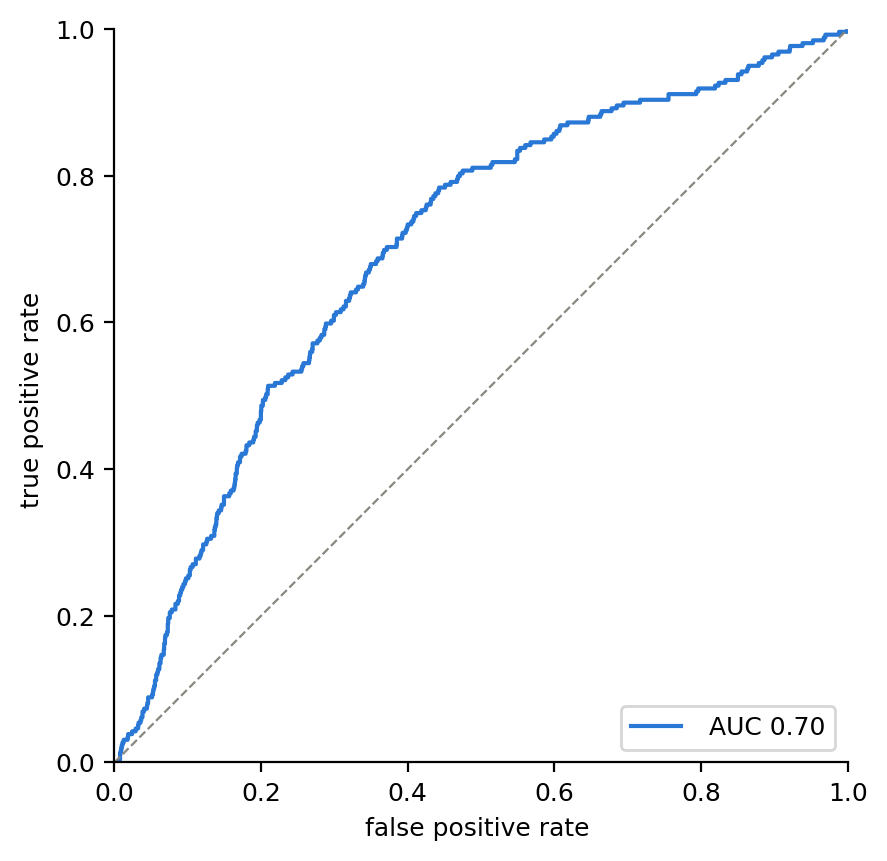

In [89]:
from scipy.stats import mannwhitneyu

for variable_name in ['capped_equal_pairs', 'capped_unequal_pairs', 'uncapped_equal_pairs', 'uncapped_unequal_pairs',
                      'OBSERVED_COLUMN', 'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN', 'PLOTTED_CAP_SEED']:
    assert variable_name in globals(), f'run the pair-ratio plot cell first ({variable_name} missing)'

# --- check and report the capped pairs that go into the curve ---
def pairs_per_protein(pair_set):
    return pl.concat([pair_set['protein_high_copies'], pair_set['protein_low_copies']]).value_counts()

for kind, capped_pair_set, uncapped_pair_set in [('equal', capped_equal_pairs, uncapped_equal_pairs),
                                                 ('unequal', capped_unequal_pairs, uncapped_unequal_pairs)]:
    capped_counts_per_protein = pairs_per_protein(capped_pair_set)
    assert capped_counts_per_protein['count'].max() <= MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, f'{kind}: a protein exceeds the cap'
    print(f'{kind:8s} pairs: {capped_pair_set.height} capped (of {uncapped_pair_set.height} uncapped), '
          f'{capped_counts_per_protein.height} proteins, at most {capped_counts_per_protein["count"].max()} pairs per protein '
          f'(cap {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN}), {capped_pair_set["complex_id"].n_unique()} complexes')

unequal_absolute_ratios = np.abs(capped_unequal_pairs[OBSERVED_COLUMN].to_numpy())
equal_absolute_ratios = np.abs(capped_equal_pairs[OBSERVED_COLUMN].to_numpy())
assert len(unequal_absolute_ratios) > 0 and len(equal_absolute_ratios) > 0, 'no pairs to compare'
assert np.isfinite(unequal_absolute_ratios).all() and np.isfinite(equal_absolute_ratios).all(), 'non-finite log2 ratios'

# every observed value is a cut-off; pairs with |log2 ratio| >= cut-off are called unequal
cut_offs = np.sort(np.unique(np.r_[unequal_absolute_ratios, equal_absolute_ratios]))[::-1]
true_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(unequal_absolute_ratios), cut_offs, side='left') / len(unequal_absolute_ratios)]
false_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(equal_absolute_ratios), cut_offs, side='left') / len(equal_absolute_ratios)]
assert true_positive_rate[-1] == 1 and false_positive_rate[-1] == 1, 'curve does not end at (1, 1)'
auc_value = (mannwhitneyu(unequal_absolute_ratios, equal_absolute_ratios, alternative='greater').statistic
             / (len(unequal_absolute_ratios) * len(equal_absolute_ratios)))
print(f'AUC {auc_value:.2f} from {len(unequal_absolute_ratios)} unequal and {len(equal_absolute_ratios)} equal pairs')

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot(false_positive_rate, true_positive_rate, color=BLUE, lw=1.5,
        label=f' AUC {auc_value:.2f}')
ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=0.8)
ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal',
       xlabel='false positive rate ', ylabel='true positive rate ')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

copy ratios in the capped pairs (draw 0):
shape: (8, 4)
┌────────────┬───────────────┬─────────┬─────────────┐
│ copy_ratio ┆ expected_log2 ┆ n_pairs ┆ n_complexes │
│ ---        ┆ ---           ┆ ---     ┆ ---         │
│ str        ┆ f64           ┆ u32     ┆ u32         │
╞════════════╪═══════════════╪═════════╪═════════════╡
│ 1:1        ┆ 0.0           ┆ 1828    ┆ 138         │
│ 3:2        ┆ 0.584963      ┆ 2       ┆ 1           │
│ 2:1        ┆ 1.0           ┆ 148     ┆ 18          │
│ 5:2        ┆ 1.321928      ┆ 6       ┆ 1           │
│ 3:1        ┆ 1.584963      ┆ 76      ┆ 7           │
│ 4:1        ┆ 2.0           ┆ 2       ┆ 2           │
│ 5:1        ┆ 2.321928      ┆ 3       ┆ 1           │
│ 6:1        ┆ 2.584963      ┆ 22      ┆ 2           │
└────────────┴───────────────┴─────────┴─────────────┘
compared (>= 10 pairs): ['1:1', '2:1', '3:1', '6:1']
AUC between copy ratios, median and 2.5–97.5% over 100 capped draws:
shape: (6, 8)
┌─────────────┬──────────────┬────────

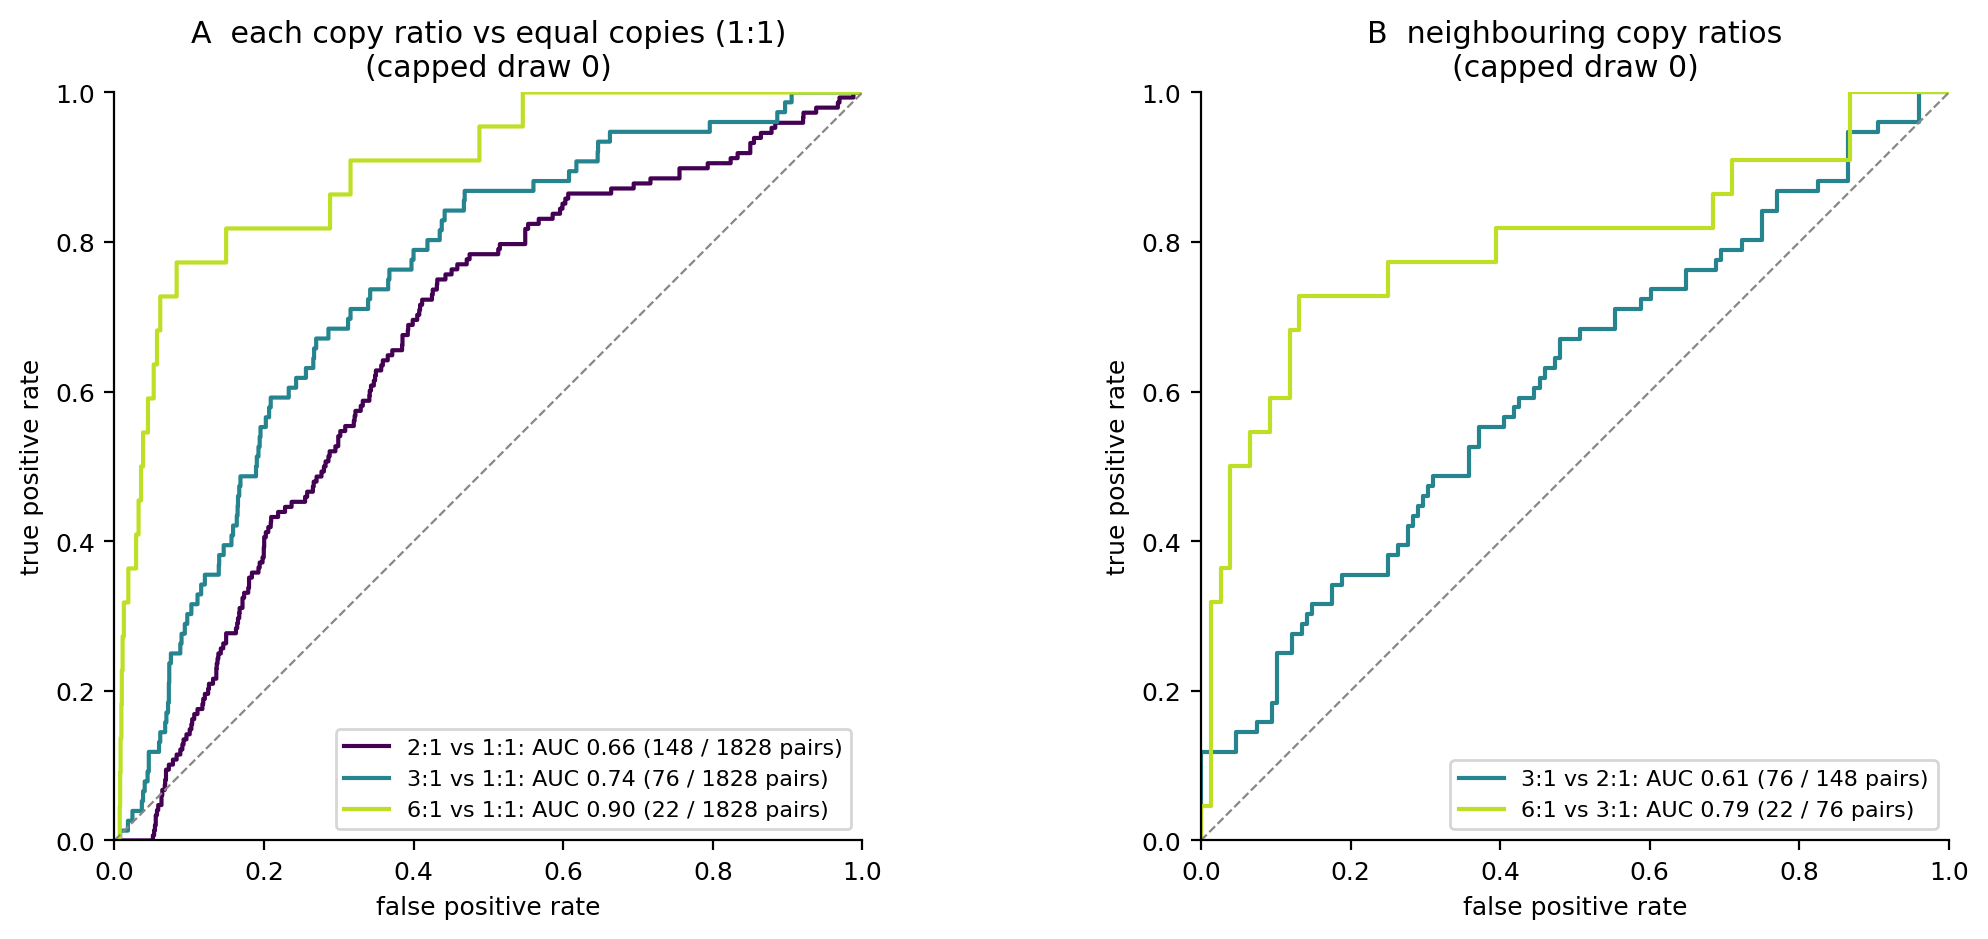

In [94]:
from scipy.stats import mannwhitneyu

for variable_name in ['capped_equal_pairs', 'capped_unequal_pairs', 'equal_pairs_all_quantities', 'unequal_pairs_all_quantities',
                      'cap_stoichiometry_pairs_per_protein', 'OBSERVED_COLUMN', 'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN',
                      'PLOTTED_CAP_SEED', 'N_CAP_DRAWS']:
    assert variable_name in globals(), f'run the stoichiometry summary / pair-ratio plot cells first ({variable_name} missing)'

MIN_PAIRS_PER_RATIO = 10               # copy ratios with fewer capped pairs (in the plotted draw) are left out

def with_copy_ratio(pair_set):
    '''Add the reduced copy ratio (4:2 -> 2:1, 2:2 -> 1:1) and the absolute observed log2 ratio.'''
    copies_high = pair_set['copies'].str.extract(r'^(\d+):\d+$', 1).cast(pl.Int64)
    copies_low = pair_set['copies'].str.extract(r'^\d+:(\d+)$', 1).cast(pl.Int64)
    assert copies_high.null_count() == 0 and copies_low.null_count() == 0, 'copies string not "int:int"'
    common_divisor = np.gcd(copies_high.to_numpy(), copies_low.to_numpy())
    reduced_ratio = [f'{high}:{low}' for high, low in zip(copies_high.to_numpy() // common_divisor, copies_low.to_numpy() // common_divisor)]
    return pair_set.with_columns(copy_ratio=pl.Series(reduced_ratio), absolute_log2_ratio=pl.col(OBSERVED_COLUMN).abs())

def capped_pairs_with_ratio(seed):
    return pl.concat([with_copy_ratio(cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)),
                      with_copy_ratio(cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed))])

def auc_higher_above_lower(lower_ratio_values, higher_ratio_values):
    '''Probability that a pair of the higher copy ratio has a larger |log2 ratio| than a pair of the lower one (ties count half).'''
    return (mannwhitneyu(higher_ratio_values, lower_ratio_values, alternative='greater').statistic
            / (len(higher_ratio_values) * len(lower_ratio_values)))

def roc_points(positive_values, negative_values):
    cut_offs = np.sort(np.unique(np.r_[positive_values, negative_values]))[::-1]
    true_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(positive_values), cut_offs, side='left') / len(positive_values)]
    false_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(negative_values), cut_offs, side='left') / len(negative_values)]
    return false_positive_rate, true_positive_rate

# --- copy-ratio classes in the plotted draw ---
plotted_draw_pairs = pl.concat([with_copy_ratio(capped_equal_pairs), with_copy_ratio(capped_unequal_pairs)])
assert plotted_draw_pairs.filter(pl.col('expected_log2') == 0)['copy_ratio'].eq('1:1').all(), 'an equal pair did not reduce to 1:1'
ratio_classes = (plotted_draw_pairs.group_by('copy_ratio')
                 .agg(expected_log2=pl.col('expected_log2').first(), n_pairs=pl.len(), n_complexes=pl.col('complex_id').n_unique())
                 .sort('expected_log2'))
print(f'copy ratios in the capped pairs (draw {PLOTTED_CAP_SEED}):')
print(ratio_classes)
compared_ratios = ratio_classes.filter(pl.col('n_pairs') >= MIN_PAIRS_PER_RATIO)['copy_ratio'].to_list()
assert len(compared_ratios) >= 2, f'fewer than two copy ratios with >= {MIN_PAIRS_PER_RATIO} pairs'
print(f'compared (>= {MIN_PAIRS_PER_RATIO} pairs): {compared_ratios}')

# --- AUC for every pair of copy ratios, over all capped draws ---
ratio_auc_rows = []
for seed in range(N_CAP_DRAWS):
    draw_pairs = capped_pairs_with_ratio(seed)
    values_by_ratio = {ratio: draw_pairs.filter(pl.col('copy_ratio') == ratio)['absolute_log2_ratio'].to_numpy() for ratio in compared_ratios}
    for lower_position, lower_ratio in enumerate(compared_ratios):
        for higher_ratio in compared_ratios[lower_position + 1:]:
            if len(values_by_ratio[lower_ratio]) == 0 or len(values_by_ratio[higher_ratio]) == 0:
                continue
            ratio_auc_rows.append(dict(seed=seed, lower_ratio=lower_ratio, higher_ratio=higher_ratio,
                                       n_lower=len(values_by_ratio[lower_ratio]), n_higher=len(values_by_ratio[higher_ratio]),
                                       auc=auc_higher_above_lower(values_by_ratio[lower_ratio], values_by_ratio[higher_ratio])))
ratio_auc_summary = (pl.DataFrame(ratio_auc_rows)
    .group_by('lower_ratio', 'higher_ratio', maintain_order=True)
    .agg(n_draws=pl.len(), median_n_lower=pl.col('n_lower').median(), median_n_higher=pl.col('n_higher').median(),
         auc_median=pl.col('auc').median(), auc_low=pl.col('auc').quantile(0.025), auc_high=pl.col('auc').quantile(0.975))
    .with_columns(pl.col('auc_median', 'auc_low', 'auc_high').round(2)))
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(f'AUC between copy ratios, median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(ratio_auc_summary)

# --- check the merging of copy ratios (e.g. 4:2 -> 2:1) ---
with pl.Config(tbl_rows=-1):
    print('original copies merged into a reduced ratio (plotted draw):')
    print(plotted_draw_pairs.filter(pl.col('copies') != pl.col('copy_ratio'))
          .group_by('copies', 'copy_ratio').agg(n_pairs=pl.len()).sort('copy_ratio', 'copies'))

# --- which comparisons: every unequal ratio vs equal (1:1), and neighbouring unequal ratios ---
assert compared_ratios[0] == '1:1', f'equal pairs (1:1) are not the lowest compared ratio: {compared_ratios}'
unequal_ratios = compared_ratios[1:]
assert len(unequal_ratios) >= 2, f'need at least two unequal copy ratios with >= {MIN_PAIRS_PER_RATIO} pairs: {unequal_ratios}'
comparisons_against_equal = [('1:1', unequal_ratio) for unequal_ratio in unequal_ratios]
neighbouring_comparisons = list(zip(unequal_ratios[:-1], unequal_ratios[1:]))

def auc_rows_for(comparisons):
    return pl.concat([ratio_auc_summary.filter((pl.col('lower_ratio') == lower_ratio) & (pl.col('higher_ratio') == higher_ratio))
                      for lower_ratio, higher_ratio in comparisons])

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(f'each unequal ratio vs equal (1:1), AUC median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(auc_rows_for(comparisons_against_equal))
    print(f'neighbouring unequal ratios, AUC median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(auc_rows_for(neighbouring_comparisons))

# --- figure: ROC curves from the plotted draw; one colour per unequal ratio (the higher ratio of each comparison) ---
ratio_colours = dict(zip(unequal_ratios, plt.get_cmap('viridis')(np.linspace(0, 0.9, len(unequal_ratios)))))

def plot_ratio_roc(ax, comparisons, x_label, title):
    for lower_ratio, higher_ratio in comparisons:
        lower_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == lower_ratio)['absolute_log2_ratio'].to_numpy()
        higher_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == higher_ratio)['absolute_log2_ratio'].to_numpy()
        assert len(lower_values) > 0 and len(higher_values) > 0, f'no pairs for {higher_ratio} vs {lower_ratio} in the plotted draw'
        false_positive_rate, true_positive_rate = roc_points(higher_values, lower_values)
        ax.plot(false_positive_rate, true_positive_rate, color=ratio_colours[higher_ratio], lw=1.5,
                label=f'{higher_ratio} vs {lower_ratio}: AUC {auc_higher_above_lower(lower_values, higher_values):.2f} '
                      f'({len(higher_values)} / {len(lower_values)} pairs)')
    ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=0.8)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xlabel=x_label,
           ylabel='true positive rate', title=title)
    ax.legend(fontsize=8, loc='lower right')

fig, (ax_against_equal, ax_neighbours) = plt.subplots(1, 2, figsize=(11, 4.8))
plot_ratio_roc(ax_against_equal, comparisons_against_equal, 'false positive rate',
               f'A  each copy ratio vs equal copies (1:1)\n(capped draw {PLOTTED_CAP_SEED})')
plot_ratio_roc(ax_neighbours, neighbouring_comparisons, 'false positive rate',
               f'B  neighbouring copy ratios\n(capped draw {PLOTTED_CAP_SEED})')
plt.tight_layout(); plt.show()

other stuff

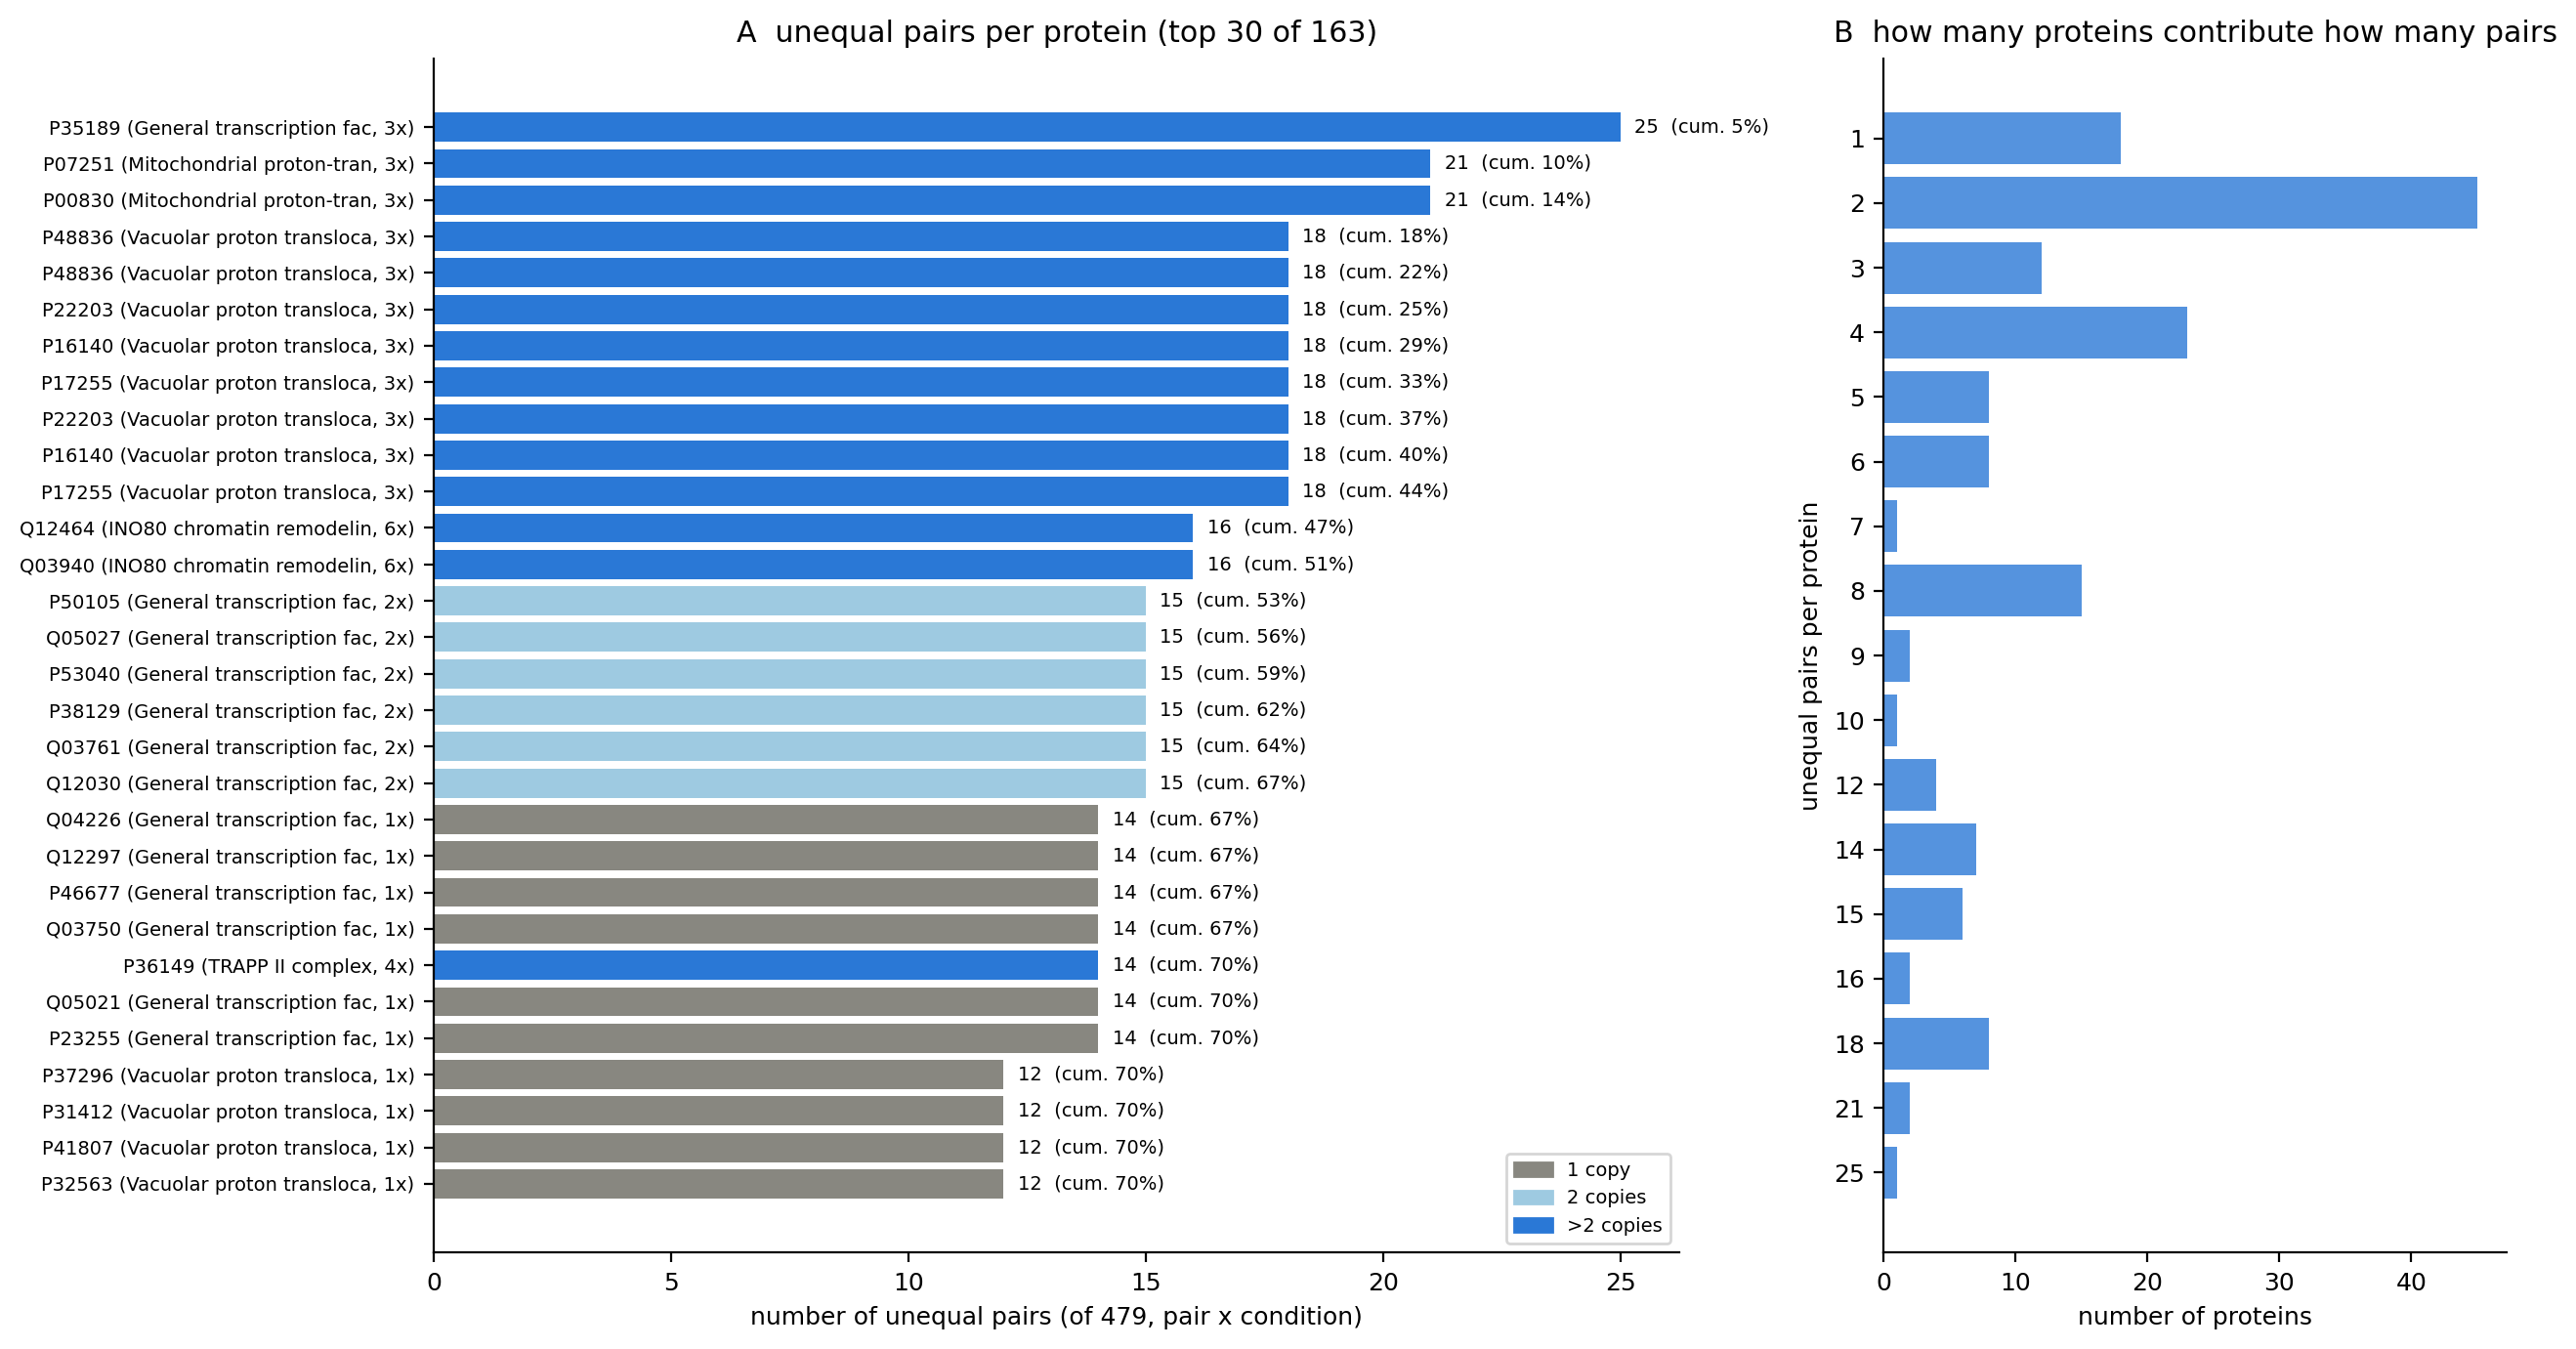

protein_id,protein_copies,complex_id,complex_name,n_unequal_pairs,n_partners,n_conditions,cumulative_share_of_unequal_pairs
str,i64,str,str,u32,u32,u32,f64
"""P35189""",3,"""CPX-1642""","""General transcription factor c…",25,13,2,0.052192
"""P07251""",3,"""CPX-3281""","""Mitochondrial proton-transport…",21,11,2,0.096033
"""P00830""",3,"""CPX-3281""","""Mitochondrial proton-transport…",21,11,2,0.139875
"""P48836""",3,"""CPX-1192""","""Vacuolar proton translocating …",18,8,3,0.177453
"""P48836""",3,"""CPX-1193""","""Vacuolar proton translocating …",18,8,3,0.215031
"""P22203""",3,"""CPX-1193""","""Vacuolar proton translocating …",18,8,3,0.25261
…,…,…,…,…,…,…,…
"""P14922""",1,"""CPX-1663""","""CYC8-TUP1 corepressor complex""",1,1,1,1.0
"""P39923""",1,"""CPX-3231""","""SEA complex""",1,1,1,1.0


In [51]:
observed_column = 'observed_log2_per_peptide'
unequal_pairs = (
    subunit_pairs.drop_nulls(observed_column)
    .filter(pl.col('expected_log2') > 0)
    .with_columns(
        copies_high=pl.col('copies').str.extract(r'^(\d+):\d+$', 1).cast(pl.Int64),
        copies_low=pl.col('copies').str.extract(r'^\d+:(\d+)$', 1).cast(pl.Int64),
    )
)
assert unequal_pairs['copies_high'].null_count() == 0 and unequal_pairs['copies_low'].null_count() == 0, 'copies string not "int:int"'
assert (unequal_pairs['copies_high'] > unequal_pairs['copies_low']).all()

unequal_pairs_indexed = unequal_pairs.with_row_index('pair_index')
protein_in_unequal_pair = pl.concat([
    unequal_pairs_indexed.select('pair_index', 'condition', 'complex_id', 'complex_name',
                                 protein_id='protein_high_copies', protein_copies='copies_high', partner_id='protein_low_copies'),
    unequal_pairs_indexed.select('pair_index', 'condition', 'complex_id', 'complex_name',
                                 protein_id='protein_low_copies', protein_copies='copies_low', partner_id='protein_high_copies'),
])

protein_pair_counts = (
    protein_in_unequal_pair.group_by('protein_id', 'protein_copies', 'complex_id', 'complex_name')
    .agg(n_unequal_pairs=pl.len(), n_partners=pl.col('partner_id').n_unique(),
         n_conditions=pl.col('condition').n_unique(), pair_indices=pl.col('pair_index'))
    .sort('n_unequal_pairs', descending=True)
)

# cumulative share of unequal pairs that involve at least one of the top-k proteins (pairs counted once)
covered_pairs = set()
cumulative_share = []
for pair_indices in protein_pair_counts['pair_indices']:
    covered_pairs.update(pair_indices)
    cumulative_share.append(len(covered_pairs) / unequal_pairs.height)
protein_pair_counts = protein_pair_counts.with_columns(cumulative_share_of_unequal_pairs=pl.Series(cumulative_share)).drop('pair_indices')
assert cumulative_share[-1] == 1.0

proteins_per_pair_count = (protein_pair_counts.group_by('n_unequal_pairs')
                           .agg(n_proteins=pl.len()).sort('n_unequal_pairs'))

N_TOP_PROTEINS = 30
top_proteins = protein_pair_counts.head(N_TOP_PROTEINS)
copy_colors = {1: GREY, 2: '#9ecae1'}                     # >2 copies -> BLUE
fig, (ax_proteins, ax_distribution) = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw=dict(width_ratios=[2, 1]))
ax_proteins.barh(np.arange(top_proteins.height), top_proteins['n_unequal_pairs'],
                 color=[copy_colors.get(copies, BLUE) for copies in top_proteins['protein_copies']])
ax_proteins.set_yticks(np.arange(top_proteins.height),
                       [f"{p} ({c[:25]}, {n}x)" for p, c, n in top_proteins.select('protein_id', 'complex_name', 'protein_copies').iter_rows()], fontsize=7)
ax_proteins.invert_yaxis()
for position, (n_pairs, share) in enumerate(top_proteins.select('n_unequal_pairs', 'cumulative_share_of_unequal_pairs').iter_rows()):
    ax_proteins.text(n_pairs + 0.3, position, f'{n_pairs}  (cum. {share:.0%})', va='center', fontsize=7)
ax_proteins.set(title=f'A  unequal pairs per protein (top {top_proteins.height} of {protein_pair_counts.height})',
                xlabel=f'number of unequal pairs (of {unequal_pairs.height}, pair x condition)')
ax_proteins.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in [GREY, '#9ecae1', BLUE]],
                   labels=['1 copy', '2 copies', '>2 copies'], fontsize=7, loc='lower right')

ax_distribution.barh(proteins_per_pair_count['n_unequal_pairs'].cast(pl.String), proteins_per_pair_count['n_proteins'], color=BLUE, alpha=0.8)
ax_distribution.invert_yaxis()
ax_distribution.set(title='B  how many proteins contribute how many pairs',
                    xlabel='number of proteins', ylabel='unequal pairs per protein')
plt.tight_layout(); plt.show()

protein_pair_counts

## Stoi just based on raw values

34 pairs dropped (no per-peptide value); 9091 pairs before the cap (697 unequal, 8394 equal); 55% have their peaks within 2 fractions of each other
shape: (10, 5)
┌─────────────────────────────────┬─────────────────┬──────────────┬───────────────┬──────────┐
│ metric                          ┆ balanced_median ┆ balanced_low ┆ balanced_high ┆ uncapped │
│ ---                             ┆ ---             ┆ ---          ┆ ---           ┆ ---      │
│ str                             ┆ f64             ┆ f64          ┆ f64           ┆ f64      │
╞═════════════════════════════════╪═════════════════╪══════════════╪═══════════════╪══════════╡
│ raw_n_unequal_pairs             ┆ 359.0           ┆ 357.0        ┆ 362.0         ┆ 697.0    │
│ raw_share_higher_copy_has_high… ┆ 0.67            ┆ 0.66         ┆ 0.7           ┆ 0.76     │
│ raw_median_observed_minus_expe… ┆ 0.07            ┆ -0.12        ┆ 0.27          ┆ 0.43     │
│ raw_n_equal_pairs               ┆ 359.0           ┆ 357.0        ┆ 

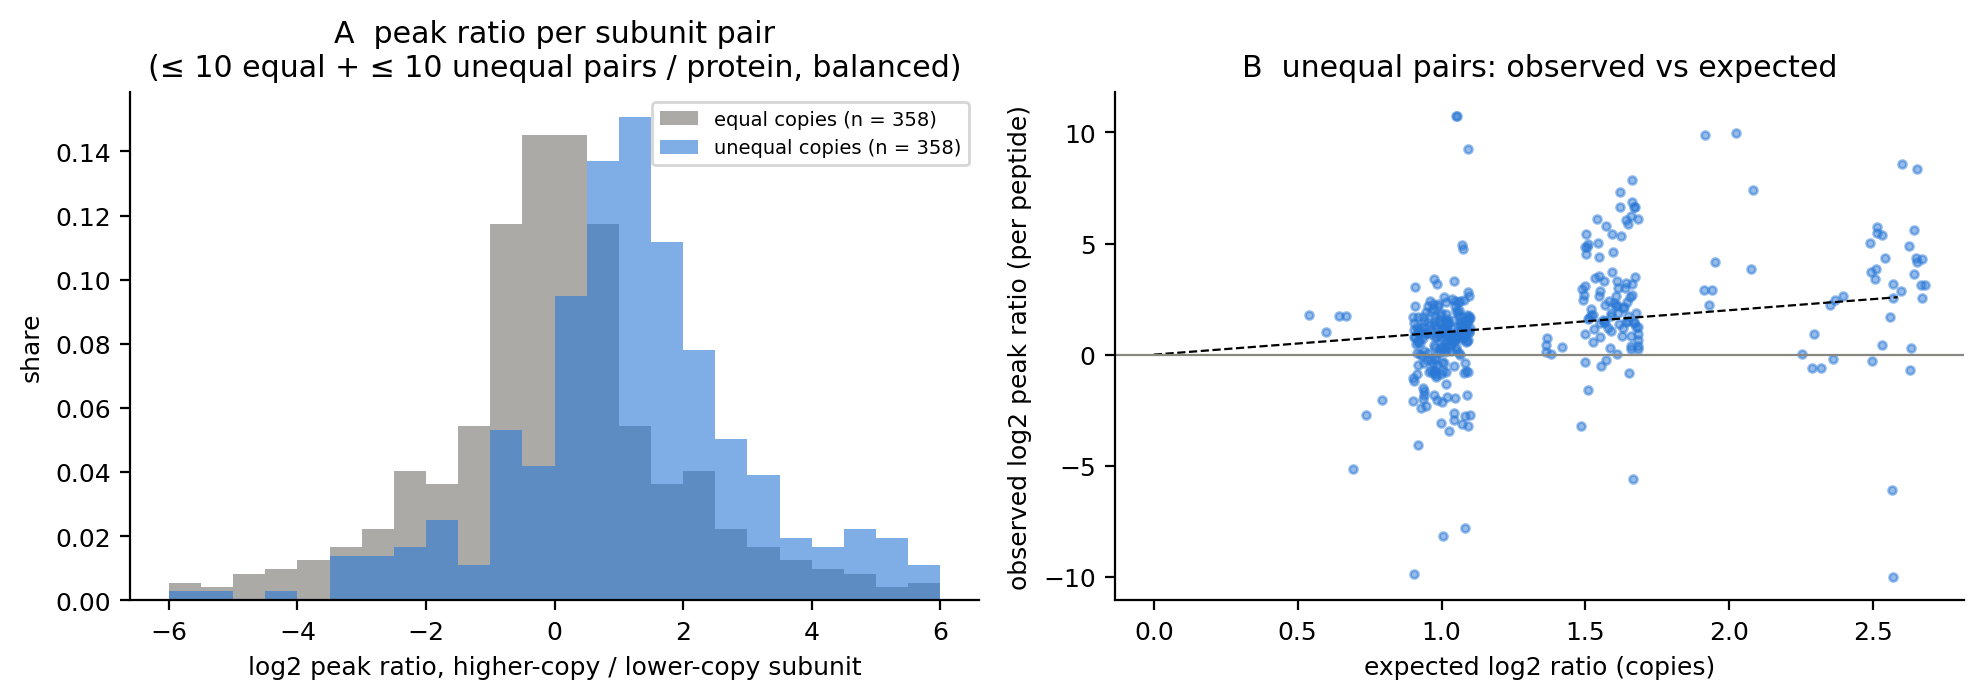

In [15]:
MAX_PAIRS_PER_PROTEIN = 10          # per kind: at most n equal AND at most n unequal pairs per protein
N_SUBSAMPLES = 100
assert 'complex_members' in globals() and 'protein_info' in globals(), 'run sections 2 and 3 (Complex Portal, pyteomics) first'

# --- 1. peak (highest value over all fractions) per protein and condition, read from the input tables ---
protein_peak_frames = []
for condition, file_name in CF_FILES.items():
    profiles = read_profiles(cofrac_data_dir / file_name).filter(~pl.col('ID').str.contains(';'))   # protein groups left out, as before
    fraction_intensities = profiles.select(FRACTION_COLUMNS).to_numpy()
    protein_peak_frames.append(pl.DataFrame({
        'condition': condition,
        'protein_id': profiles['ID'],
        'peak_intensity': fraction_intensities.max(axis=1),
        'peak_fraction': fraction_intensities.argmax(axis=1) + 1}))
protein_peaks = (pl.concat(protein_peak_frames)
    .filter(pl.col('peak_intensity') > 0)
    .join(protein_info.select('protein_id', 'n_tryptic_peptides'), on='protein_id', how='left')
    .with_columns(peak_per_peptide=pl.col('peak_intensity') / pl.col('n_tryptic_peptides')))     # null if no 6-30 aa peptide

# --- 2. all subunit pairs within complexes with fully known stoichiometry ---
members_with_known_copies = complex_members.filter('copies_known').select('complex_id', 'complex_name', 'protein_id', 'copies')
assert (members_with_known_copies['copies'] > 0).all()
member_peaks = members_with_known_copies.join(protein_peaks, on='protein_id')

pair_candidates = (member_peaks
    .join(member_peaks.select('condition', 'complex_id', 'protein_id', 'copies', 'peak_intensity', 'peak_per_peptide', 'peak_fraction'),
          on=['condition', 'complex_id'], suffix='_other')
    .filter(pl.col('protein_id') < pl.col('protein_id_other')))          # each pair once

first_has_more_copies = pl.col('copies') >= pl.col('copies_other')    # equal copies: orientation arbitrary (alphabetical)
def oriented(column, higher_copy_side):
    this_side, other_side = pl.col(column), pl.col(f'{column}_other')
    return (pl.when(first_has_more_copies).then(this_side if higher_copy_side else other_side)
              .otherwise(other_side if higher_copy_side else this_side))

all_peak_pairs = pair_candidates.select(
    'condition', 'complex_id', 'complex_name',
    protein_high_copies=oriented('protein_id', True), protein_low_copies=oriented('protein_id', False),
    copies_high=oriented('copies', True), copies_low=oriented('copies', False),
    expected_log2=(oriented('copies', True) / oriented('copies', False)).log(2),
    observed_log2_raw=(oriented('peak_intensity', True) / oriented('peak_intensity', False)).log(2),
    observed_log2_per_peptide=(oriented('peak_per_peptide', True) / oriented('peak_per_peptide', False)).log(2),
    peak_fraction_distance=(pl.col('peak_fraction') - pl.col('peak_fraction_other')).abs())
assert (all_peak_pairs['copies_high'] >= all_peak_pairs['copies_low']).all()

# same pairs for raw and per-peptide: drop pairs with a protein that has no 6-30 aa tryptic peptide
peak_pairs = all_peak_pairs.drop_nulls('observed_log2_per_peptide')
print(f"{all_peak_pairs.height - peak_pairs.height} pairs dropped (no per-peptide value); "
      f"{peak_pairs.height} pairs before the cap ({(peak_pairs['expected_log2'] > 0).sum()} unequal, "
      f"{(peak_pairs['expected_log2'] == 0).sum()} equal); "
      f"{(peak_pairs['peak_fraction_distance'] <= 2).mean():.0%} have their peaks within 2 fractions of each other")

# --- 3. cap per kind, then balance equal and unequal pairs to the same number ---
def cap_pairs_per_protein(pairs, max_pairs_per_protein, seed):
    shuffled_pairs = pairs.sample(fraction=1.0, shuffle=True, seed=seed)
    kept_pairs_per_protein, keep_pair = {}, []
    for protein_high, protein_low in shuffled_pairs.select('protein_high_copies', 'protein_low_copies').iter_rows():
        keep = (kept_pairs_per_protein.get(protein_high, 0) < max_pairs_per_protein
                and kept_pairs_per_protein.get(protein_low, 0) < max_pairs_per_protein)
        if keep:
            kept_pairs_per_protein[protein_high] = kept_pairs_per_protein.get(protein_high, 0) + 1
            kept_pairs_per_protein[protein_low] = kept_pairs_per_protein.get(protein_low, 0) + 1
        keep_pair.append(keep)
    capped_pairs = shuffled_pairs.filter(pl.Series(keep_pair))
    pairs_per_protein = pl.concat([capped_pairs['protein_high_copies'], capped_pairs['protein_low_copies']]).value_counts()
    assert pairs_per_protein['count'].max() <= max_pairs_per_protein
    return capped_pairs

def capped_and_balanced_pairs(pairs, max_pairs_per_protein, seed):
    '''Cap equal and unequal pairs separately per protein, then downsample the larger group to the size of the smaller.'''
    capped_equal_pairs = cap_pairs_per_protein(pairs.filter(pl.col('expected_log2') == 0), max_pairs_per_protein, seed)
    capped_unequal_pairs = cap_pairs_per_protein(pairs.filter(pl.col('expected_log2') > 0), max_pairs_per_protein, seed)
    n_per_group = min(capped_equal_pairs.height, capped_unequal_pairs.height)
    assert n_per_group > 0, 'no pairs left in one of the groups'
    return pl.concat([capped_equal_pairs.sample(n=n_per_group, seed=seed),
                      capped_unequal_pairs.sample(n=n_per_group, seed=seed)])

def peak_pair_metrics(pairs):
    metrics = {}
    for quantity in ['raw', 'per_peptide']:
        observed = f'observed_log2_{quantity}'
        unequal = pairs.filter(pl.col('expected_log2') > 0)
        equal = pairs.filter(pl.col('expected_log2') == 0)
        metrics |= {f'{quantity}_n_unequal_pairs': unequal.height,
                    f'{quantity}_share_higher_copy_has_higher_peak': float((unequal[observed] > 0).mean()),
                    f'{quantity}_median_observed_minus_expected_log2': float((unequal[observed] - unequal['expected_log2']).median()),
                    f'{quantity}_n_equal_pairs': equal.height,
                    f'{quantity}_equal_pairs_median_fold': float(2 ** equal[observed].abs().median())}
    return metrics

peak_subsample_results = pl.DataFrame([peak_pair_metrics(capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed))
                                       for seed in range(N_SUBSAMPLES)])
peak_pair_summary = (peak_subsample_results.select(pl.all().cast(pl.Float64))
    .unpivot(variable_name='metric')
    .group_by('metric', maintain_order=True)
    .agg(balanced_median=pl.col('value').median(), balanced_low=pl.col('value').quantile(0.025), balanced_high=pl.col('value').quantile(0.975))
    .with_columns(uncapped=pl.col('metric').replace_strict({k: float(v) for k, v in peak_pair_metrics(peak_pairs).items()}))
    .with_columns(pl.col(pl.Float64).round(2)))
with pl.Config(tbl_rows=-1):
    print(peak_pair_summary)

# --- 4. one draw (seed 0) as a figure, per-peptide normalised peaks ---
balanced_peak_pairs = capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed=0)
equal_peak_ratios = balanced_peak_pairs.filter(pl.col('expected_log2') == 0)['observed_log2_per_peptide'].to_numpy()
unequal_peak_pairs = balanced_peak_pairs.filter(pl.col('expected_log2') > 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.arange(-6, 6.1, 0.5)
axes[0].hist(np.r_[equal_peak_ratios, -equal_peak_ratios], bins, weights=np.full(2 * len(equal_peak_ratios), 1 / (2 * len(equal_peak_ratios))),
             color=GREY, alpha=0.7, label=f'equal copies (n = {len(equal_peak_ratios)})')
axes[0].hist(unequal_peak_pairs['observed_log2_per_peptide'], bins, weights=np.full(unequal_peak_pairs.height, 1 / unequal_peak_pairs.height),
             color=BLUE, alpha=0.6, label=f'unequal copies (n = {unequal_peak_pairs.height})')
axes[0].set(title=f'A  peak ratio per subunit pair\n(≤ {MAX_PAIRS_PER_PROTEIN} equal + ≤ {MAX_PAIRS_PER_PROTEIN} unequal pairs / protein, balanced)',
            xlabel='log2 peak ratio, higher-copy / lower-copy subunit', ylabel='share')
axes[0].legend(fontsize=7)
axes[1].scatter(unequal_peak_pairs['expected_log2'] + np.random.default_rng(0).uniform(-0.1, 0.1, unequal_peak_pairs.height),
                unequal_peak_pairs['observed_log2_per_peptide'], s=8, alpha=0.5, c=BLUE)
identity_line = np.array([0, unequal_peak_pairs['expected_log2'].max()])
axes[1].plot(identity_line, identity_line, 'k--', lw=0.8)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].set(title='B  unequal pairs: observed vs expected', xlabel='expected log2 ratio (copies)',
            ylabel='observed log2 peak ratio (per peptide)')
plt.tight_layout(); plt.show()

shape: (4, 7)
┌─────────────┬──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ quantity    ┆ comparison   ┆ median_n_un ┆ auc_balance ┆ auc_balance ┆ auc_balance ┆ auc_uncappe │
│ ---         ┆ ---          ┆ equal       ┆ d_median    ┆ d_low       ┆ d_high      ┆ d           │
│ str         ┆ str          ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         │
│             ┆              ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ f64         │
╞═════════════╪══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ raw         ┆ any unequal  ┆ 359.0       ┆ 0.64        ┆ 0.63        ┆ 0.65        ┆ 0.71        │
│             ┆ vs equal     ┆             ┆             ┆             ┆             ┆             │
│ raw         ┆ 2:1 vs equal ┆ 207.0       ┆ 0.56        ┆ 0.55        ┆ 0.57        ┆ 0.58        │
│ per_peptide ┆ any unequal  ┆ 359.0       ┆ 0.69        ┆ 0.68        ┆ 0.71

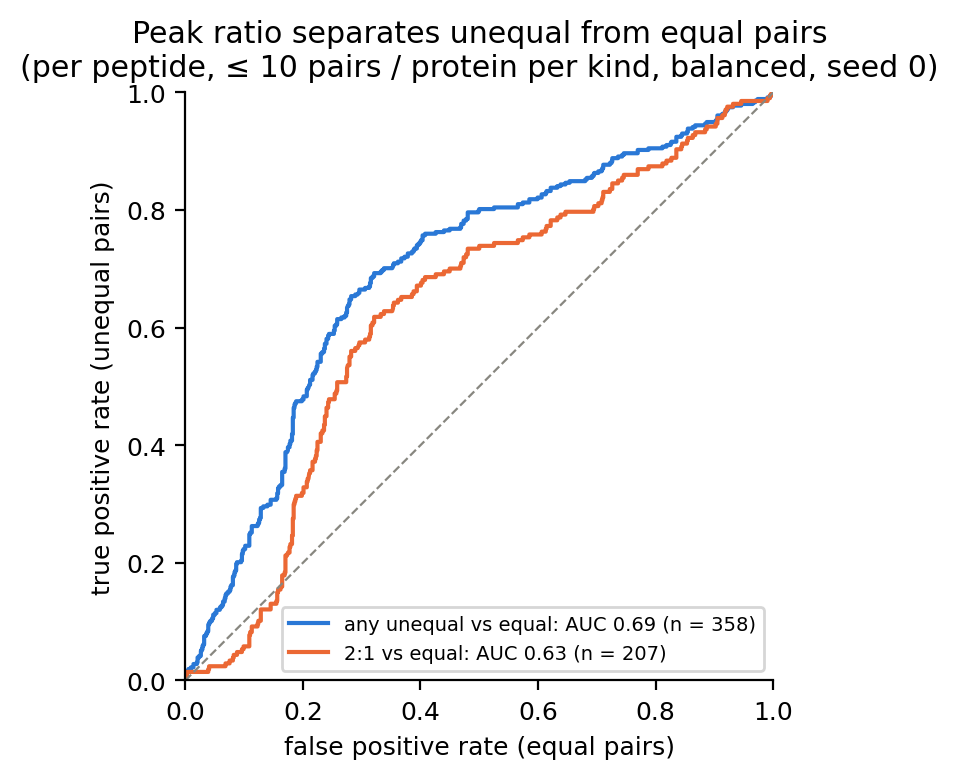

In [16]:
from scipy.stats import mannwhitneyu

AUC_COMPARISONS = {
    'any unequal vs equal': pl.col('expected_log2') > 0,
    '2:1 vs equal': (pl.col('expected_log2') - 1).abs() < 1e-9,
}

def split_unequal_and_mirrored_equal(pairs, observed_column, unequal_condition):
    unequal_values = pairs.filter(unequal_condition)[observed_column].to_numpy()
    equal_values = pairs.filter(pl.col('expected_log2') == 0)[observed_column].to_numpy()
    assert len(unequal_values) > 0 and len(equal_values) > 0, f'no pairs to compare for {observed_column}'
    return unequal_values, np.r_[equal_values, -equal_values]     # equal pairs in both orientations

def auc_unequal_vs_equal(pairs, observed_column, unequal_condition):
    unequal_values, mirrored_equal_values = split_unequal_and_mirrored_equal(pairs, observed_column, unequal_condition)
    u_statistic = mannwhitneyu(unequal_values, mirrored_equal_values, alternative='greater').statistic   # ties count 0.5
    return u_statistic / (len(unequal_values) * len(mirrored_equal_values))

def auc_rows(pairs, seed):
    return [dict(seed=seed, quantity=quantity, comparison=comparison,
                 n_unequal=pairs.filter(unequal_condition).height,
                 auc=auc_unequal_vs_equal(pairs, f'observed_log2_{quantity}', unequal_condition))
            for quantity in ['raw', 'per_peptide'] for comparison, unequal_condition in AUC_COMPARISONS.items()]

peak_pair_aucs = pl.DataFrame([row for seed in range(N_SUBSAMPLES)
                               for row in auc_rows(capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed), seed)])
uncapped_aucs = {(row['quantity'], row['comparison']): row['auc'] for row in auc_rows(peak_pairs, seed=-1)}

peak_pair_auc_summary = (peak_pair_aucs
    .group_by('quantity', 'comparison', maintain_order=True)
    .agg(median_n_unequal=pl.col('n_unequal').median(),
         auc_balanced_median=pl.col('auc').median(), auc_balanced_low=pl.col('auc').quantile(0.025), auc_balanced_high=pl.col('auc').quantile(0.975))
    .with_columns(auc_uncapped=pl.struct('quantity', 'comparison').map_elements(
        lambda key: uncapped_aucs[(key['quantity'], key['comparison'])], return_dtype=pl.Float64))
    .with_columns(pl.col(pl.Float64).round(2)))
print(peak_pair_auc_summary)

# ROC curves for one draw (seed 0), per-peptide peaks
def roc_curve_points(positive_values, negative_values):
    thresholds = np.r_[np.inf, np.sort(np.unique(np.r_[positive_values, negative_values]))[::-1]]
    true_positive_rate = np.array([(positive_values >= threshold).mean() for threshold in thresholds])
    false_positive_rate = np.array([(negative_values >= threshold).mean() for threshold in thresholds])
    return false_positive_rate, true_positive_rate

balanced_pairs_seed_0 = capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed=0)
fig, ax = plt.subplots(figsize=(4.2, 4))
for (comparison, unequal_condition), colour in zip(AUC_COMPARISONS.items(), [BLUE, ORANGE]):
    unequal_values, mirrored_equal_values = split_unequal_and_mirrored_equal(balanced_pairs_seed_0, 'observed_log2_per_peptide', unequal_condition)
    false_positive_rate, true_positive_rate = roc_curve_points(unequal_values, mirrored_equal_values)
    auc_value = auc_unequal_vs_equal(balanced_pairs_seed_0, 'observed_log2_per_peptide', unequal_condition)
    ax.plot(false_positive_rate, true_positive_rate, color=colour, lw=1.5,
            label=f'{comparison}: AUC {auc_value:.2f} (n = {len(unequal_values)})')
ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=0.8)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='false positive rate (equal pairs)', ylabel='true positive rate (unequal pairs)',
       title=f'Peak ratio separates unequal from equal pairs\n(per peptide, ≤ {MAX_PAIRS_PER_PROTEIN} pairs / protein per kind, balanced, seed 0)')
ax.set_aspect('equal')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

shape: (8, 3)
┌────────────┬───────────────┬───────────────┐
│ copy_ratio ┆ expected_log2 ┆ n_pairs_total │
│ ---        ┆ ---           ┆ ---           │
│ str        ┆ f64           ┆ u32           │
╞════════════╪═══════════════╪═══════════════╡
│ 3:2        ┆ 0.584963      ┆ 13            │
│ 5:3        ┆ 0.736966      ┆ 3             │
│ 2:1        ┆ 1.0           ┆ 275           │
│ 5:2        ┆ 1.321928      ┆ 6             │
│ 3:1        ┆ 1.584963      ┆ 316           │
│ 4:1        ┆ 2.0           ┆ 8             │
│ 5:1        ┆ 2.321928      ┆ 9             │
│ 6:1        ┆ 2.584963      ┆ 67            │
└────────────┴───────────────┴───────────────┘
shape: (8, 8)
┌────────────┬────────────┬────────────┬────────────┬─────────┬──────────┬────────────┬────────────┐
│ copy_ratio ┆ n_draws_wi ┆ median_n_p ┆ auc_median ┆ auc_low ┆ auc_high ┆ expected_l ┆ n_pairs_to │
│ ---        ┆ th_pairs   ┆ airs       ┆ ---        ┆ ---     ┆ ---      ┆ og2        ┆ tal        │
│ str      

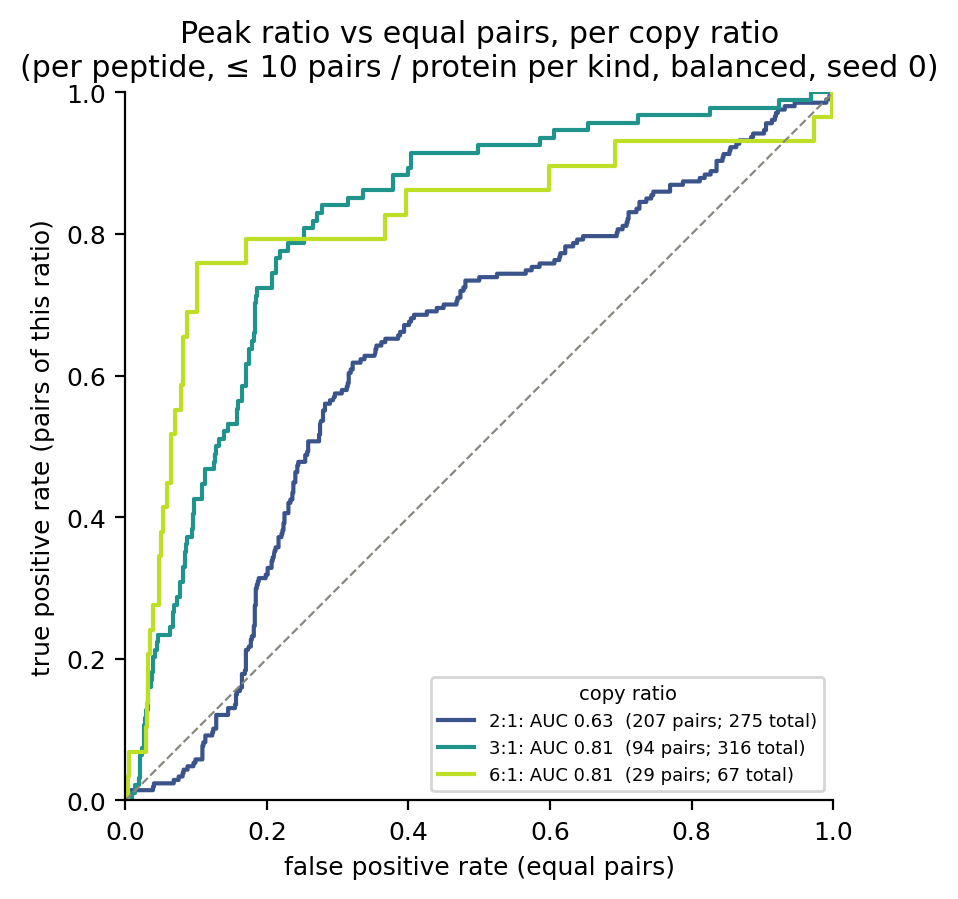

not drawn (< 10 pairs in this draw): ['3:2 (4 in draw, 13 total)', '5:3 (3 in draw, 3 total)', '5:2 (5 in draw, 6 total)', '4:1 (8 in draw, 8 total)', '5:1 (8 in draw, 9 total)']


In [18]:
MIN_PAIRS_FOR_CURVE = 10          # ratios with fewer pairs in the plotted draw are not drawn (listed instead)

# reduced copy ratio per pair: divide both copy numbers by their greatest common divisor (24:12 -> 2:1, 4:2 -> 2:1)
copies_high_array = peak_pairs['copies_high'].to_numpy()
copies_low_array = peak_pairs['copies_low'].to_numpy()
copies_gcd = np.gcd(copies_high_array, copies_low_array)
assert (copies_gcd > 0).all()
peak_pairs = peak_pairs.with_columns(
    copy_ratio=pl.Series([f'{high}:{low}' for high, low in zip(copies_high_array // copies_gcd, copies_low_array // copies_gcd)]))
assert peak_pairs.filter(pl.col('expected_log2') == 0)['copy_ratio'].eq('1:1').all(), 'an equal pair did not reduce to 1:1'

copy_ratio_order = (peak_pairs.filter(pl.col('expected_log2') > 0)
                    .group_by('copy_ratio').agg(expected_log2=pl.col('expected_log2').first(), n_pairs_total=pl.len())
                    .sort('expected_log2', 'copy_ratio'))
print(copy_ratio_order)

def ratio_condition(copy_ratio):
    return (pl.col('copy_ratio') == copy_ratio) & (pl.col('expected_log2') > 0)

# AUC per copy ratio over all balanced draws
per_ratio_auc_rows = []
for seed in range(N_SUBSAMPLES):
    balanced_pairs = capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed)
    for copy_ratio in copy_ratio_order['copy_ratio']:
        n_ratio_pairs = balanced_pairs.filter(ratio_condition(copy_ratio)).height
        if n_ratio_pairs == 0:
            continue
        per_ratio_auc_rows.append(dict(seed=seed, copy_ratio=copy_ratio, n_pairs=n_ratio_pairs,
                                       auc=auc_unequal_vs_equal(balanced_pairs, 'observed_log2_per_peptide', ratio_condition(copy_ratio))))
per_ratio_auc_summary = (pl.DataFrame(per_ratio_auc_rows)
    .group_by('copy_ratio')
    .agg(n_draws_with_pairs=pl.len(), median_n_pairs=pl.col('n_pairs').median(),
         auc_median=pl.col('auc').median(), auc_low=pl.col('auc').quantile(0.025), auc_high=pl.col('auc').quantile(0.975))
    .join(copy_ratio_order, on='copy_ratio')
    .sort('expected_log2', 'copy_ratio')
    .with_columns(pl.col('auc_median', 'auc_low', 'auc_high').round(2)))
with pl.Config(tbl_rows=-1):
    print(per_ratio_auc_summary)

# ROC curves per copy ratio for one draw (seed 0)
balanced_pairs_seed_0 = capped_and_balanced_pairs(peak_pairs, MAX_PAIRS_PER_PROTEIN, seed=0)
ratio_colours = plt.cm.viridis(np.linspace(0, 0.9, copy_ratio_order.height))
fig, ax = plt.subplots(figsize=(5, 4.6))
ratios_not_drawn = []
for (copy_ratio, n_pairs_total), colour in zip(copy_ratio_order.select('copy_ratio', 'n_pairs_total').iter_rows(), ratio_colours):
    n_in_draw = balanced_pairs_seed_0.filter(ratio_condition(copy_ratio)).height
    if n_in_draw < MIN_PAIRS_FOR_CURVE:
        ratios_not_drawn.append(f'{copy_ratio} ({n_in_draw} in draw, {n_pairs_total} total)')
        continue
    unequal_values, mirrored_equal_values = split_unequal_and_mirrored_equal(balanced_pairs_seed_0, 'observed_log2_per_peptide', ratio_condition(copy_ratio))
    false_positive_rate, true_positive_rate = roc_curve_points(unequal_values, mirrored_equal_values)
    auc_value = auc_unequal_vs_equal(balanced_pairs_seed_0, 'observed_log2_per_peptide', ratio_condition(copy_ratio))
    ax.plot(false_positive_rate, true_positive_rate, color=colour, lw=1.5,
            label=f'{copy_ratio}: AUC {auc_value:.2f}  ({n_in_draw} pairs; {n_pairs_total} total)')
ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=0.8)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='false positive rate (equal pairs)', ylabel='true positive rate (pairs of this ratio)',
       title=f'Peak ratio vs equal pairs, per copy ratio\n(per peptide, ≤ {MAX_PAIRS_PER_PROTEIN} pairs / protein per kind, balanced, seed 0)')
ax.set_aspect('equal')
ax.legend(fontsize=6.5, loc='lower right', title='copy ratio', title_fontsize=7)
plt.tight_layout(); plt.show()
print(f'not drawn (< {MIN_PAIRS_FOR_CURVE} pairs in this draw):', ratios_not_drawn)

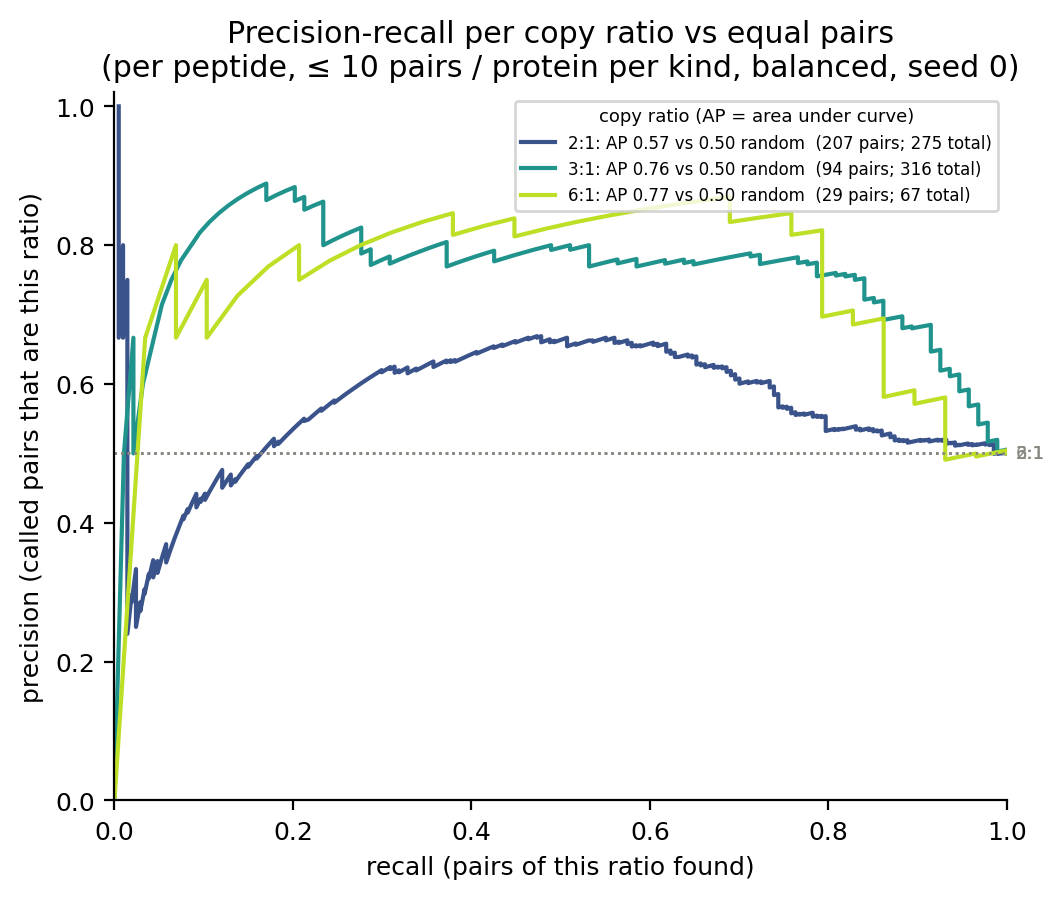

not drawn (< 10 pairs in this draw): ['3:2 (4 in draw, 13 total)', '5:3 (3 in draw, 3 total)', '5:2 (5 in draw, 6 total)', '4:1 (8 in draw, 8 total)', '5:1 (8 in draw, 9 total)']


In [21]:
def precision_recall_points(positive_values, mirrored_negative_values):
    '''Negatives are equal pairs in both orientations; each orientation counts as half a pair.'''
    thresholds = np.sort(np.unique(np.r_[positive_values, mirrored_negative_values]))[::-1]
    true_positives = np.array([(positive_values >= threshold).sum() for threshold in thresholds])
    false_positives = np.array([0.5 * (mirrored_negative_values >= threshold).sum() for threshold in thresholds])
    called_positive = true_positives + false_positives
    keep = called_positive > 0
    recall = true_positives[keep] / len(positive_values)
    precision = true_positives[keep] / called_positive[keep]
    return recall, precision

def average_precision(recall, precision):
    '''Step-wise area under the precision-recall curve (precision at each recall increase).'''
    recall_steps = np.diff(np.r_[0, recall])
    return float((recall_steps * precision).sum())

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ratios_not_drawn = []
for (copy_ratio, n_pairs_total), colour in zip(copy_ratio_order.select('copy_ratio', 'n_pairs_total').iter_rows(), ratio_colours):
    n_in_draw = balanced_pairs_seed_0.filter(ratio_condition(copy_ratio)).height
    if n_in_draw < MIN_PAIRS_FOR_CURVE:
        ratios_not_drawn.append(f'{copy_ratio} ({n_in_draw} in draw, {n_pairs_total} total)')
        continue
    ratio_values, all_mirrored_equal_values = split_unequal_and_mirrored_equal(balanced_pairs_seed_0, 'observed_log2_per_peptide', ratio_condition(copy_ratio))
    all_equal_values = all_mirrored_equal_values[:len(all_mirrored_equal_values) // 2]          # first half = each equal pair once
    assert len(all_equal_values) >= len(ratio_values), f'fewer equal pairs than {copy_ratio} pairs'
    sampled_equal_values = np.random.default_rng(0).choice(all_equal_values, size=len(ratio_values), replace=False)
    mirrored_equal_values = np.r_[sampled_equal_values, -sampled_equal_values]
    recall, precision = precision_recall_points(ratio_values, mirrored_equal_values)
    n_equal_pairs = len(mirrored_equal_values) / 2
    random_guess_precision = len(ratio_values) / (len(ratio_values) + n_equal_pairs)
    ax.plot(recall, precision, color=colour, lw=1.5,
            label=f'{copy_ratio}: AP {average_precision(recall, precision):.2f} vs {random_guess_precision:.2f} random  '
                  f'({n_in_draw} pairs; {n_pairs_total} total)')
    ax.axhline(random_guess_precision, color=GREY, ls=':', lw=0.9)
    ax.text(1.01, random_guess_precision, copy_ratio, color=GREY, fontsize=6.5, va='center', transform=ax.get_yaxis_transform())
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='recall (pairs of this ratio found)', ylabel='precision (called pairs that are this ratio)',
       title=f'Precision-recall per copy ratio vs equal pairs\n(per peptide, ≤ {MAX_PAIRS_PER_PROTEIN} pairs / protein per kind, balanced, seed 0)')
ax.legend(fontsize=6, loc='upper right', title='copy ratio (AP = area under curve)', title_fontsize=6.5)
plt.tight_layout(); plt.show()
print(f'not drawn (< {MIN_PAIRS_FOR_CURVE} pairs in this draw):', ratios_not_drawn)

## 7. Choices in this analysis

| Choice | Basis |
|---|---|
| Peak finding, co-elution score, FDR | CCprofiler defaults (`corr_cutoff` 0.95, `window_size` 15, `smoothing_length` 11, `rt_height` 5, decoys at network distance >= 2) |
| One feature per complex | CCprofiler `getBestFeatures` among features with q <= 0.05 |
| Protein groups `[A;B]` left out | one trace per protein needed; splitting would create artificial co-elution |
| Complex Portal paralogue sets left out; non-protein molecules ignored | as before |
| Expected mass = subunits in the feature x Complex Portal copies | as before; masses from pyteomics |
| Single-protein anchors: highest-intensity fraction; PCNA left out | no complex method for single proteins; PCNA has two states |
| Calibration: least-squares line of log mass vs fraction | CCprofiler `calibrateMW` (previously Theil-Sen) |
| Stoichiometry window = CCprofiler peak boundaries | replaces the apex +- 2 window |
| Tryptic peptides: distinct 6-30 aa, ExPASy trypsin rule | pyteomics |
| Proteins without a 6-30 aa tryptic peptide: per-peptide value left empty | nothing to normalise by; raw and per-mass unaffected |